<a href="https://colab.research.google.com/github/alexmordashov/image_processing/blob/main/%D0%A0%D0%B0%D0%B1%D0%BE%D1%82%D0%B0%20%E2%84%966/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%E2%84%965_%D0%9A%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D1%8F_%D0%B8_%D0%BA%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D0%B8%D1%8F_%D1%81%D0%BF%D1%83%D1%82%D0%BD%D0%B8%D0%BA%D0%BE%D0%B2%D1%8B%D1%85_%D1%81%D0%BD%D0%B8%D0%BC%D0%BA%D0%BE%D0%B2_%D0%B2_GEE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Практическая работа №5. Сравнительный анализ контролируемой классификации и неконтролируемой кластеризации спутниковых снимков в Google Earth Engine: выявление ошибок пропуска и скрытых пространственных структур**

## **1. Цель работы**

Обучить в Google Earth Engine классификаторы земного покрова по разметке Dynamic World и честно оценить их точность, найти кластеризацией на снимке территории объекты, которых нет в легенде готовых карт, и экспериментально определить, когда кластеризация цветов действительно уменьшает размер изображений.

## **2. Задачи работы**

1.  **Подготовить** летний композит Sentinel-2 и карту Dynamic World для территории своего варианта, рассмотреть снимок в естественных цветах и в инфракрасной комбинации каналов и записать гипотезы о том, что на нём можно найти;
2.  **Обучить** несколько классификаторов GEE на стратифицированной выборке с метками Dynamic World, сравнить случайную и пространственную проверку точности, оценить точность по классам и важность признаков;
3.  **Построить** карту классификации территории и сравнить её с картой Dynamic World;
4.  **Кластеризовать** снимок алгоритмом K-средних на серверах GEE при нескольких значениях $K$, дать кластерам названия, найти малые и необычные группы пикселей и проверить гипотезы;
5.  **Провести** эксперименты по сжатию фотографий, карты и снимка кластеризацией цветов: размер файлов, время, качество, сравнение со встроенным методом квантизации;
6.  **Сформулировать** выводы с конкретными числами.

> **Примечание.** Работа опирается на две лекции:
> - [лекция «Экспорт растровых данных и применение методов машинного обучения в среде Google Earth Engine»](https://colab.research.google.com/drive/1BU-Q4D0XEIy2KiEtzw-3dKISE0lwGLV2) — **Разделы 1–4** (композиты, экспорт, выборки, классификаторы);
> - лекция «Кластеризация спутниковых снимков в среде Google Earth Engine» — **Разделы 2–6** (K-средних, интерпретация кластеров, поиск необычного, сжатие изображений).
>
> Код из лекций можно использовать как образец, но задания этой работы отличаются от лекционных примеров: другая разметка, другая территория, другие проверки.

> 📝 **Как выполнять работу.** Выполняйте ячейки по порядку. В ячейки `# Ваш код` впишите свой код; если в ячейке уже есть заготовка, замените в ней `...`. Ответы на вопросы пишите в ячейки **Ответ:** — двойной щелчок по ячейке, текст ответа, затем Shift+Enter. В ответах приводите числа из своих результатов.

---

## **3. Выбор территории и подготовка данных в Google Earth Engine**

### **3.1. Настройка рабочей среды и аутентификация**

In [ ]:
%%capture
!pip install -U geemap geedim rasterio scikit-learn scikit-image

In [ ]:
# Импорт основных библиотек для работы
import os
import time

import ee                        # Google Earth Engine
import geemap                    # Интерактивные карты и экспорт растров из GEE
import numpy as np               # Работа с массивами
import pandas as pd              # Работа с таблицами
import rasterio                  # Чтение экспортированных GeoTIFF
import matplotlib.pyplot as plt  # Построение графиков
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from PIL import Image            # Сохранение изображений, в том числе палитровых PNG
from sklearn.cluster import KMeans
from skimage import data as skdata
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

%config InlineBackend.figure_format = 'jpeg'  # рисунки со снимками компактнее в JPEG

Перед началом работы с geemap и Google Earth Engine необходимо:

- **Зарегистрировать аккаунт Google Earth Engine**: Перейдите на [https://code.earthengine.google.com/register](https://code.earthengine.google.com/register) для создания аккаунта GEE. После регистрации нужно настроить проект Google Cloud и активировать API Earth Engine, следуя инструкциям [здесь](https://docs.google.com/document/d/1ZGSmrNm6_baqd8CHt33kIBWOlvkh-HLr46bODgJN1h0/edit?usp=sharing). GEE бесплатен для [некоммерческого и исследовательского использования](https://earthengine.google.com/noncommercial).

- **Проверить аутентификацию API**: Чтобы убедиться в правильности настройки аккаунта Earth Engine, запустите [этот тестовый блокнот](https://colab.research.google.com/github/gee-community/geemap/blob/master/docs/notebooks/geemap_colab.ipynb) в Google Colab.

In [ ]:
ee.Authenticate()
ee.Initialize(project="project2ana")

### **3.2. Выбор территории**

Ниже перечислены территории, на которых есть объекты, плохо заметные на снимке в естественных цветах или отсутствующие в легенде готовых карт земного покрова: месторождения полезных ископаемых, нефтепромыслы, лесные гари, солепромыслы. Что именно и где искать, в таблице не сказано — это и предстоит выяснить. Номер варианта назначает преподаватель (если не назначен — номер в списке группы по модулю 7, нулю соответствует вариант 7).

#### **Таблица 1. Варианты территорий**

| **Вариант** | **Территория** | **Широта, долгота центра** | **Природная зона** |
|---|---|---|---|
| 1 | Олимпиадинское золоторудное месторождение, Красноярский край | 59.585, 92.990 | Южная тайга |
| 2 | Норильск: медно-никелевые и платиноидные руды, Красноярский край | 69.350, 88.200 | Лесотундра |
| 3 | Губкин, железные руды Курской магнитной аномалии, Белгородская область | 51.290, 37.700 | Лесостепь |
| 4 | Железногорск, железные руды Курской магнитной аномалии, Курская область | 52.360, 35.400 | Лесостепь |
| 5 | Самотлорское нефтяное месторождение, Ханты-Мансийский АО | 61.130, 76.750 | Средняя тайга, болота |
| 6 | Тайга в Забайкальском крае, район весенних лесных пожаров 2024 года | 54.665, 118.893 | Горная тайга |
| 7 | Озеро Баскунчак, Астраханская область | 48.200, 46.880 | Полупустыня |

Область интереса — квадрат 14×14 км вокруг центра. Все варианты анализируются по снимкам лета 2024 года.

In [ ]:
PLACES = {
    1: ('Олимпиадинское золоторудное месторождение', 59.585, 92.990),
    2: ('Норильск', 69.350, 88.200),
    3: ('Губкин, Лебединский ГОК', 51.290, 37.700),
    4: ('Железногорск, Михайловский ГОК', 52.360, 35.400),
    5: ('Самотлорское нефтяное месторождение', 61.130, 76.750),
    6: ('Тайга в Забайкальском крае', 54.665, 118.893),
    7: ('Озеро Баскунчак', 48.200, 46.880),
}
YEAR = 2024

In [ ]:
VARIANT = 2
PLACE, LAT, LON = PLACES[VARIANT]
roi = ee.Geometry.Point([LON, LAT]).buffer(7000).bounds()
map_roi = geemap.Map(zoom=10)
map_roi.add_basemap('Esri.WorldImagery')
map_roi.centerObject(roi, 11)
map_roi.addLayer(roi, {'color': 'red'}, 'Область интереса')
map_roi

Map(center=[69.34998106248189, 88.20033996158713], controls=(WidgetControl(options=['position', 'transparent_b…

**Задание 3.2.** Рассмотрите территорию на карте-подложке. Ответьте до начала анализа.

**Вопрос:** Какие типы земного покрова вы видите на подложке? Какие объекты, связанные с названием территории (добыча, промыслы, пожары), вы ожидаете найти и где? Какие из них, по-вашему, не имеют своего класса в легенде Dynamic World (вода, деревья, трава, затопляемая растительность, сельхозкультуры, кустарники, застройка, голая земля, снег и лёд)?

**Ответ:** На подложке можно увидеть растительность (в основном, деревья), застройку (жилые и промышленные здания), а также воду в виде рек или прудов (в т.ч. антропогенного происхождения). На карте я ожидаю найти карьеры и рудники, т.к. в Норильске добывают никель. Я считаю, что сельхозкультуры не имеют своего класса в легенде Dynamic World.

### **3.3. Летний композит Sentinel-2 и спектральные индексы**

> 📚 **Подсказка:** [лекция по GEE](https://colab.research.google.com/drive/1BU-Q4D0XEIy2KiEtzw-3dKISE0lwGLV2), **разделы 2.2–2.3** (фильтрация, маска облаков по каналу SCL, медианный композит) и **3.3** (индексы).

**Задание 3.3.** Постройте медианный композит `composite` снимков Sentinel-2 уровня 2A (`COPERNICUS/S2_SR_HARMONIZED`) за 1 июня – 31 августа 2024 года:
- каналы `BANDS = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']`, значения отражения переведены в диапазон 0–1 (деление на 10000);
- снимки с облачностью `CLOUDY_PIXEL_PERCENTAGE` < 20%, облака и тени замаскированы по каналу SCL (классы 3, 8, 9, 10);
- к композиту добавлены индексы `NDVI` (B8, B4), `NDWI` (B3, B8) и `NDBI` (B11, B8);
- список всех признаков сохраните в переменную `FEATURES` — он понадобится для обучения классификаторов.

In [ ]:
def load_sentinel2_collection(roi, start_date, end_date, bands, cloud_percentage=20):
    collection = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    collection = collection.filterBounds(roi)
    collection = collection.filterDate(start_date, end_date)
    collection = collection.filter(ee.Filter.lessThan('CLOUDY_PIXEL_PERCENTAGE', cloud_percentage))

    def mask_clouds(image):
        scl = image.select('SCL')
        mask = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
        return image.select(bands).updateMask(mask).divide(10000).copyProperties(image, ['system:time_start'])
    return collection.map(mask_clouds)

def add_spectral_indices(image):
    ndvi = image.normalizedDifference(['B8', 'B4']).rename('NDVI')
    ndwi = image.normalizedDifference(['B3', 'B8']).rename('NDWI')
    ndbi = image.normalizedDifference(['B11', 'B8']).rename('NDBI')
    return image.addBands([ndvi, ndwi, ndbi])

def create_median_composite(collection, roi):
    median_image = collection.median()
    median_image = median_image.clip(roi)
    return median_image

BANDS = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']

start_ = f'{YEAR}-06-01'
end_ = f'{YEAR}-08-31'
composite_2024 = create_median_composite(load_sentinel2_collection(roi, start_, end_, BANDS), roi)
sentinel_2024 = add_spectral_indices(composite_2024)

FEATURES = BANDS + ['NDVI', 'NDWI', 'NDBI']

In [ ]:
vis_params = {'bands': ['B4', 'B3', 'B2'], 'min': 0.0, 'max': 0.3, 'gamma': 1.4}

map_composite = geemap.Map()
map_composite.add_basemap('Esri.WorldTopoMap')
map_composite.centerObject(roi, 11)
map_composite.addLayer(sentinel_2024, vis_params, 'Медианный композит RGB')

map_composite

Map(center=[69.34998106248189, 88.20033996158713], controls=(WidgetControl(options=['position', 'transparent_b…

### **3.4. Карта Dynamic World**

Dynamic World — карта земного покрова с пикселем 10 м, которую Google строит нейросетью для каждого снимка Sentinel-2. В этой работе она служит **разметкой для обучения**: классификатор будет учиться повторять её классы по спектру пикселей.

**Задание 3.4.** Получите `dynamic_world` — моду канала `label` коллекции `GOOGLE/DYNAMICWORLD/V1` за тот же период (наиболее частый класс в каждом пикселе), обрежьте по `roi` и переименуйте канал в `'class'`.

In [ ]:
DW_NAMES = ['Вода', 'Деревья', 'Трава', 'Затопл. растительность', 'Культуры',
            'Кустарники', 'Застройка', 'Голая земля', 'Снег и лед']
DW_COLORS = ['#419bdf', '#397d49', '#88b053', '#7a87c6', '#e49635',
             '#dfc35a', '#c4281b', '#a59b8f', '#b39fe1']

dynamic_world = (ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1')
                 .filterBounds(roi)
                 .filterDate(f'{YEAR}-06-01', f'{YEAR}-08-31')
                 .select('label')
                 .mode()
                 .clip(roi)
                 .rename('class'))

### **3.5. Экспорт и просмотр растров**

Для анализа на локальной машине нужны шесть основных каналов композита, индексы NDVI и NDWI и карта Dynamic World. Растры экспортируются в проекции UTM с пикселем 10 м и загружаются плитками 256×256 пикселей. Карты классов сохраняются с типом `int16`: при типе `uint8` значение 0 используется как «нет данных» и совпало бы с классом «Вода». **Если экспорт идёт слишком долго, увеличьте `SCALE` до 20 м.**

In [ ]:
#@title Готовая функция экспорта
SCALE = 10  # размер пикселя, м

def utm_crs(region):
    """Код EPSG зоны UTM для центра области."""
    lon, lat = region.centroid(maxError=1).coordinates().getInfo()
    return f'EPSG:{(32600 if lat >= 0 else 32700) + int((lon + 180) // 6) + 1}'

def export_georeferenced_raster(image, region, filename, scale=SCALE, dtype='float32', tile_size=256):
    """Экспорт в GeoTIFF в проекции UTM с загрузкой плитками."""
    geemap.download_ee_image(image=image, filename=filename, region=region, scale=scale,
                             crs=utm_crs(region), dtype=dtype, max_tile_dim=tile_size)
    return filename

def read_raster(filename):
    """Массив каналов растра (каналы, строки, столбцы)."""
    with rasterio.open(filename) as src:
        return src.read()

os.makedirs('data', exist_ok=True)

**Задание 3.5.** Экспортируйте каналы `LOCAL_BANDS` композита в `data/sentinel2.tif` (тип `float32`) и `dynamic_world` в `data/dynamic_world.tif` (тип `int16`). Загрузите их в массивы `bands` и `dw`, получите маску пикселей с данными `valid` (все каналы конечны и `dw >= 0`), размеры `H`, `W` и площадь пикселя в гектарах `PIXEL_AREA_HA`.

In [ ]:
LOCAL_BANDS = ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDWI']

In [ ]:
export_georeferenced_raster(sentinel_2024.select(LOCAL_BANDS), roi, 'data/sentinel2.tif', scale=SCALE)
export_georeferenced_raster(dynamic_world, roi, 'data/dynamic_world.tif', scale=SCALE, dtype='int16')

with rasterio.open('data/sentinel2.tif') as src:
  bands = src.read().astype('float32')
  PIXEL_AREA_HA = src.res[0] * src.res[1] / 10000
with rasterio.open('data/dynamic_world.tif') as src:
  dw = src.read(1)

valid = np.isfinite(bands).all(axis=0) & (dw >= 0)
H, W = valid.shape

  0%|          |0/288 tiles [00:00<?]

  0%|          |0/36 tiles [00:00<?]

Человеческий глаз видит только видимый диапазон, поэтому многие объекты на снимке в естественных цветах неразличимы. Комбинация **B12 – B8 – B4** (коротковолновый ИК, ближний ИК, красный) отображает здоровую растительность ярко-зелёной (высокое отражение в B8), открытый грунт, горные породы и гари — красно-бурыми и сиреневыми (высокое отражение в B12), воду — почти чёрной. Покажем снимок в обеих комбинациях и карту Dynamic World.

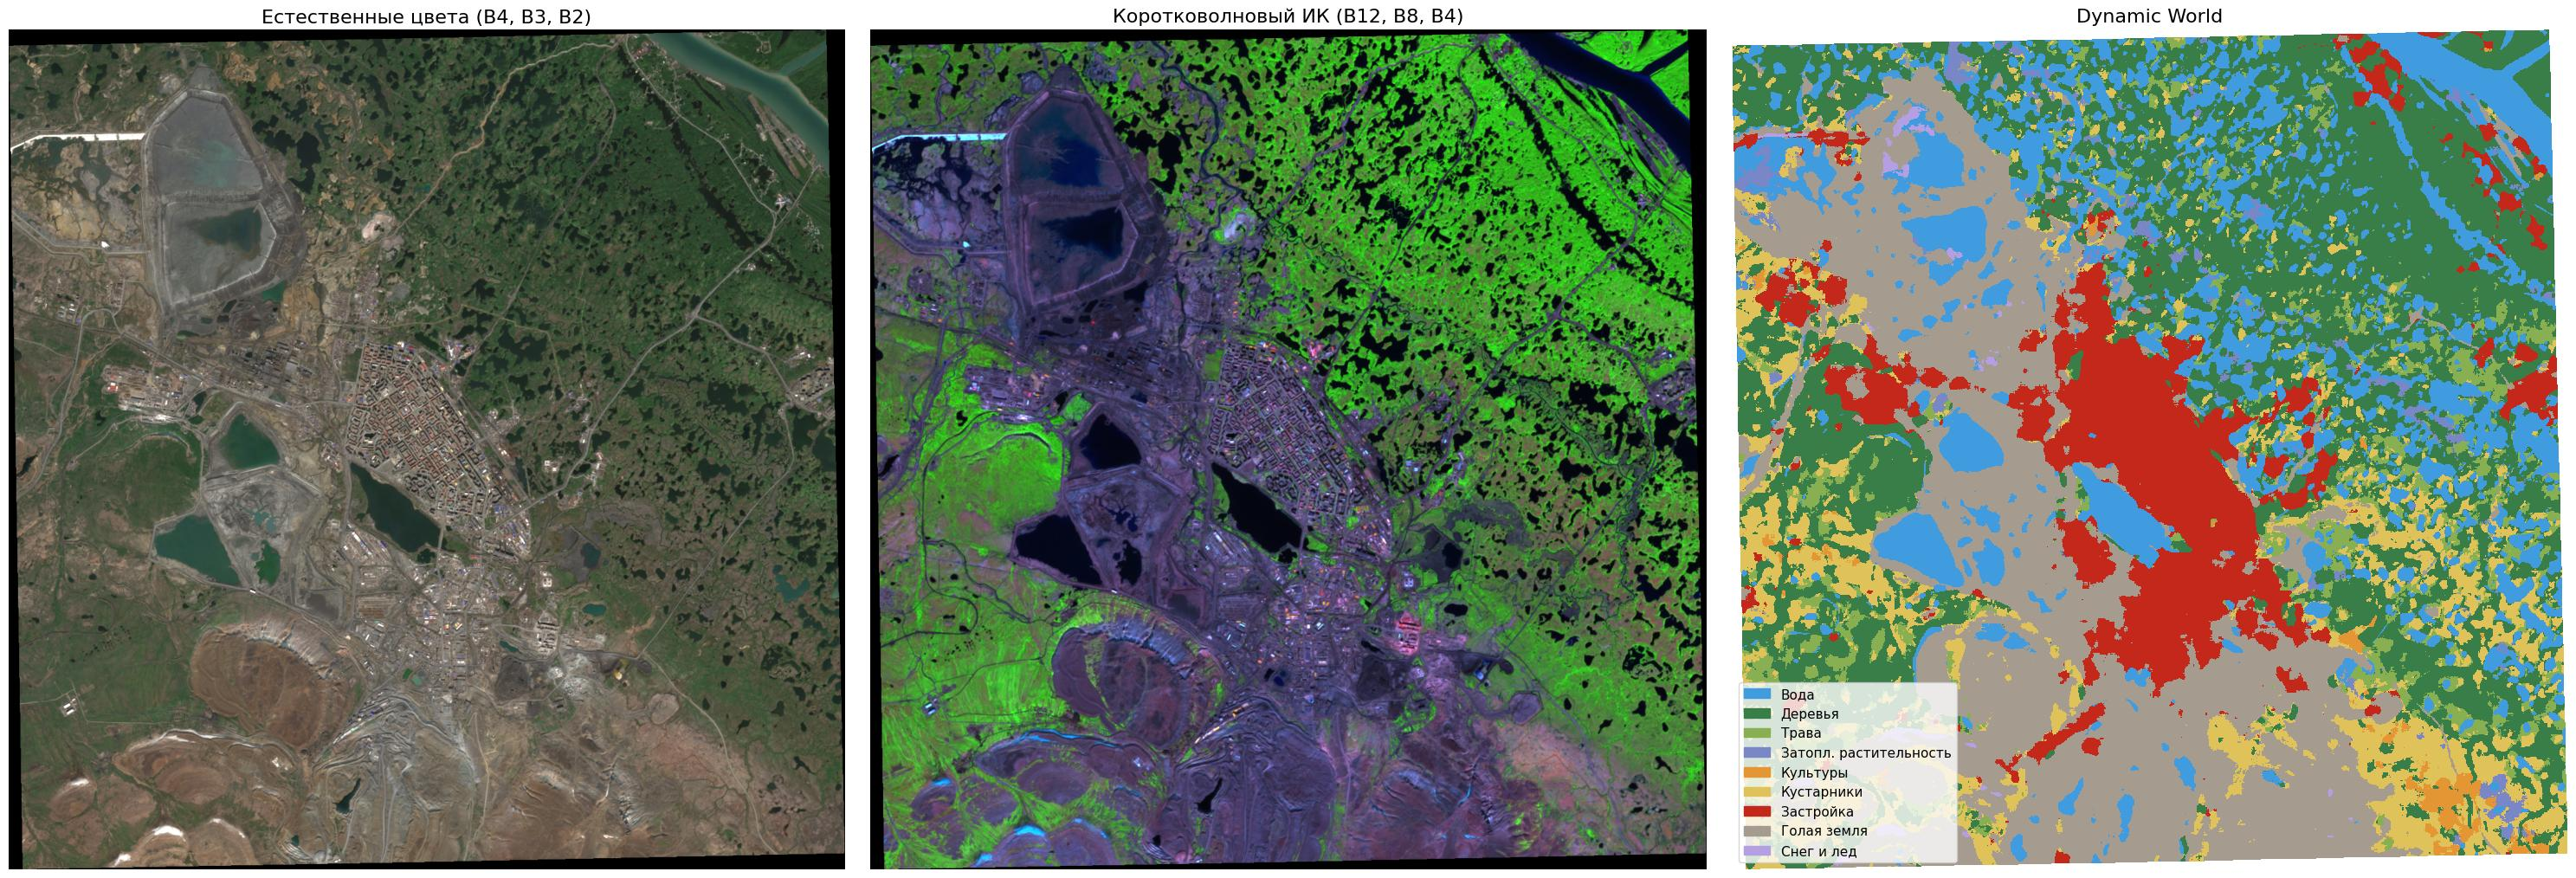

,"Площадь, га"
Деревья,5628.8
Голая земля,5058.2
Вода,3143.6
Застройка,2146.5
Кустарники,2021.6
Трава,1140.7
Затопл. растительность,264.8
Культуры,164.5
Снег и лед,76.5


In [ ]:
#@title Готовая функция: снимок в естественных цветах и в комбинации B12-B8-B4
def stretch(x, high):
    """Линейное растяжение значений отражения в диапазон 0-1."""
    return np.clip(np.nan_to_num(x, nan=0, posinf=0, neginf=0) / high, 0, 1)

rgb = stretch(np.dstack([bands[2], bands[1], bands[0]]), 0.3) ** (1 / 1.4)   # B4, B3, B2
swir = np.dstack([stretch(bands[5], 0.4), stretch(bands[3], 0.45), stretch(bands[2], 0.25)])   # B12, B8, B4
dw_cmap = ListedColormap(DW_COLORS)
dw_legend = [Patch(color=col, label=name) for col, name in zip(DW_COLORS, DW_NAMES)]

fig, axes = plt.subplots(1, 3, figsize=(30, 10))
axes[0].imshow(rgb)
axes[0].set_title('Естественные цвета (B4, B3, B2)', fontsize=16)
axes[1].imshow(swir)
axes[1].set_title('Коротковолновый ИК (B12, B8, B4)', fontsize=16)
axes[2].imshow(np.ma.masked_less(dw, 0), cmap=dw_cmap, vmin=-0.5, vmax=8.5, interpolation='nearest')
axes[2].set_title('Dynamic World', fontsize=16)
axes[2].legend(handles=dw_legend, loc='lower left', fontsize=11)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

dw_areas = pd.Series(np.bincount(dw[valid], minlength=9) * PIXEL_AREA_HA, index=DW_NAMES, name='Площадь, га')
dw_areas[dw_areas > 0].sort_values(ascending=False).round(1)

**Задание 3.5 (продолжение).** Сравните три изображения. Запишите гипотезы: какие участки выглядят необычно на комбинации B12–B8–B4, хотя на снимке в естественных цветах не выделяются (или наоборот), и к какому классу Dynamic World их отнёс. Гипотезы проверите в разделе 5.

#### **Таблица 2. Гипотезы до анализа**

| № | Наблюдение (где, как выглядит в естественных цветах и в B12–B8–B4) | Класс Dynamic World | Гипотеза: что это за объект | Как проверить |
|---|---|---|---|---|
| 1 | В левом верхнем углу полоска белого цвета в RGB и голубого цвета в ИК | Частично голая земля, частично застройка | Дорога, вдоль которой лежит либо снег, либо отвалы породы | Проверить космоснимки высокого разрешения. |
| 2 | Маленькие зелёные участки между домами | Городские кварталы определены как застройка | Часть городской растительности (скверы, парки, клумбы) | Проверить космоснимки высокого разрешения. |
| 3 | В левой нижней части участки с белыми пятнами | Снег рядом с голой землёй, частично кустарники, в некоторых местах вода(склон) | Холмы из горных пород | Проверить космоснимки высокого разрешения. |

<details>
<summary><b>Пример формулировки</b></summary>

*Условный пример:* «В центре — светлое пятно неправильной формы около 2×3 км, в естественных цветах серо-бежевое, в B12–B8–B4 сиреневое, вокруг ярко-зелёная тайга. Dynamic World относит его к кустарникам и голой земле. Гипотеза: карьер и отвалы пустой породы. Проверка: отдельный кластер со спектром без растительности и высоким отражением в B11–B12».

</details>

**Ответ:** _______________

---

## **4. Классификация с учителем по разметке Dynamic World**

В лекции классификаторы обучались по карте ESA WorldCover. Здесь разметкой будет Dynamic World: классификатор учится по спектру пикселя предсказывать класс, который поставил бы Dynamic World. Это удобно — разметку не нужно создавать вручную, — но у такого подхода есть пределы: модель повторит и классы, и ошибки разметки. Их мы и увидим.

### **4.1. Стратифицированная обучающая выборка**

Классы на территории занимают очень разную площадь: например, тайга — десятки квадратных километров, застройка — несколько гектаров. Простая случайная выборка (`sample`) почти не содержит точек редких классов, и модель их не выучит. **Стратифицированная выборка** (`stratifiedSample`) берёт заданное число точек из каждого класса: если пикселей класса меньше, берутся все.

**Параметры метода `stratifiedSample`:**
- `numPoints` — число точек на класс
- `classBand` — канал с метками классов
- `region`, `scale` — область и размер пикселя выборки
- `seed` — начальное значение генератора для воспроизводимости
- `tileScale` — дробление вычислений на более мелкие плитки (помогает избежать ошибки нехватки памяти)

К каждой точке сразу добавим номер блока «шахматной доски» со стороной 1 км — он понадобится для пространственной проверки в разделе 4.2.

In [ ]:
# Номер блока шахматной доски 1×1 км: 0 — «чёрные» клетки, 1 — «белые»
BLOCK_SIZE = 1000
blocks = (ee.Image.pixelCoordinates(ee.Projection(utm_crs(roi)))
          .divide(BLOCK_SIZE).floor().reduce('sum').mod(2).toInt().rename('block'))

**Задание 4.1.** Получите выборку `samples`: по 400 точек каждого класса из изображения `composite.addBands(dynamic_world).addBands(blocks)` (`scale=SCALE`, `projection=utm_crs(roi)`, `seed=42`, `tileScale=4`). Проекция UTM обязательна: по умолчанию выборка берётся в географических координатах, где пиксель «10 м» по долготе в высоких широтах вдвое уже, и точки редких классов дублируются. Выведите число точек по классам (`aggregate_histogram('class')`) с названиями классов. Классы, у которых меньше 100 точек, исключите из выборки (`ee.Filter.inList`): по нескольким десяткам точек нельзя ни обучить, ни проверить модель. Список оставшихся кодов классов сохраните в `CLASSES`.

In [ ]:
combined = sentinel_2024.addBands(dynamic_world).addBands(blocks)
points = combined.stratifiedSample(
    numPoints=400,
    classBand='class',
    region=roi,
    scale=SCALE,
    projection=utm_crs(roi),
    seed=42,
    tileScale=4
)

hist = points.aggregate_histogram('class').getInfo()
hist = {int(k): int(v) for k, v in hist.items()}

print('Число точек по классам:')
for code in sorted(hist):
    print(f'  {code} : {hist[code]}')

MIN_POINTS = 100
CLASSES = sorted([code for code, n in hist.items() if n >= MIN_POINTS])
excluded = sorted([code for code, n in hist.items() if n < MIN_POINTS])

print(f'\nCLASSES (>= {MIN_POINTS} точек): {CLASSES}')
if excluded:
    print('Исключены (мало точек):',
          [(c, hist[c]) for c in excluded])

points = points.filter(ee.Filter.inList('class', CLASSES))

final_hist = points.aggregate_histogram('class').getInfo()
final_hist = {int(k): int(v) for k, v in final_hist.items()}
print('\nИтоговая выборка:')
for code in CLASSES:
    print(f'  {code} : {final_hist.get(code, 0)}')
print(f'Всего точек: {points.size().getInfo()}')

Число точек по классам:
  0 : 400
  1 : 400
  2 : 400
  3 : 400
  4 : 400
  5 : 400
  6 : 400
  7 : 400
  8 : 400

CLASSES (>= 100 точек): [0, 1, 2, 3, 4, 5, 6, 7, 8]

Итоговая выборка:
  0 : 400
  1 : 400
  2 : 400
  3 : 400
  4 : 400
  5 : 400
  6 : 400
  7 : 400
  8 : 400
Всего точек: 3600


### **4.2. Случайная и пространственная проверка точности**

В лекции выборка делилась на обучающую и проверочную случайно (70/30). Но соседние пиксели снимка почти одинаковы: если один пиксель поля попал в обучение, а соседний — в проверку, модель «узнаёт» знакомое место, а не применяет выученное правило. Точность на такой проверке завышена. Честнее проверять модель на **других участках** территории: обучать на «чёрных» клетках шахматной доски, а проверять на «белых». Так оценивают, как модель поведёт себя на новом месте.

**Задание 4.2.** Создайте два разбиения выборки:
- случайное: `randomColumn('random', 42)`, обучение — `random < 0.7`, проверка — остальные;
- пространственное: обучение — `block == 0`, проверка — `block == 1`.

Для каждого разбиения обучите `ee.Classifier.smileRandomForest(numberOfTrees=100, seed=42)` на признаках `FEATURES` и рассчитайте общую точность и каппу на проверочной части. Сохраните разбиения в словарь `splits = {'Случайная': (train, test), 'Пространственная': (train, test)}` и выведите таблицу результатов.

> 📚 **Подсказка:** [лекция по GEE](https://colab.research.google.com/drive/1BU-Q4D0XEIy2KiEtzw-3dKISE0lwGLV2), **раздел 4.2** (разделение по `randomColumn`) и **4.3** (`train`, `classify`, `errorMatrix`).

In [ ]:
split = 0.7

data = points.randomColumn('random', 42)
train_rnd = data.filter(ee.Filter.lt('random', split))
test_rnd = data.filter(ee.Filter.gte('random', split))

train_sp = points.filter(ee.Filter.eq('block', 0))
test_sp = points.filter(ee.Filter.eq('block', 1))

splits = {
    'Случайное разбиение': (train_rnd, test_rnd),
    "Пространственное разбиение": (train_sp, test_sp)
}

results = {}
models = {}

for name, (train, test) in splits.items():
  #n_train = train.size().getInfo()
  #n_test = test.size().getInfo()

  model = ee.Classifier.smileRandomForest(
      numberOfTrees=100, seed=42
  ).train(
      features=train,
      classProperty='class',
      inputProperties=LOCAL_BANDS
  )
  predicted = test.classify(model)
  error_matrix = predicted.errorMatrix('class', 'classification')
  models[name] = model
  results[name] = {
      'accuracy': error_matrix.accuracy().getInfo(),
      'kappa': error_matrix.kappa().getInfo(),
      'matrix': np.array(error_matrix.getInfo())
  }
  print(f"{name}: Точность = {results[name]['accuracy']:.3f}, "
          f"Каппа = {results[name]['kappa']:.3f}")

Случайное разбиение: Точность = 0.524, Каппа = 0.465
Пространственное разбиение: Точность = 0.536, Каппа = 0.478


**Вопрос:** На сколько различаются точность и каппа случайного леса при случайной и пространственной проверке? Почему? Какой оценке вы бы доверяли, если модель нужно применить к соседнему участку тайги или к другому месторождению?

**Ответ:** Различие между случайной и пространственной проверкой мало (пространственная чуть выше). Однако обе оценки низкие, что указывает на слабую модель, а не на её устойчивость к пространственному сдвигу. Малое различие объясняется, скорее всего, тем, что модель не выучила пространственно-специфичных артефактов. Для переноса на соседний участок тайги следует доверять пространственной оценке, поскольку она учитывает пространственную автокорреляцию и ближе к реальному применению.

### **4.3. Сравнение классификаторов**

**Задание 4.3.** Выберите не менее трёх классификаторов из лекции (раздел 4.3) и сравните их **на пространственном разбиении**. Наивный байесовский классификатор не берите: он рассчитан на неотрицательные целые признаки (счётчики), а у нас дробные отражения и индексы. Сохраните обученные модели в словарь `models`, матрицы ошибок — в `matrices`, таблицу точности и каппы — в `metrics`, название лучшей модели по каппе — в `best_name`.

In [ ]:
classifiers = {
    'Random Forest': ee.Classifier.smileRandomForest(numberOfTrees=100, seed=42),
    'CART': ee.Classifier.smileCart(maxNodes=None),
    'SVM': ee.Classifier.libsvm(
        kernelType='RBF',
        gamma=0.1,
        cost=10
    ),
    'Gradient Boost': ee.Classifier.smileGradientTreeBoost(
        numberOfTrees=50,
        shrinkage=0.1,
        seed=42
    ),
    'Min Distance': ee.Classifier.minimumDistance(metric='euclidean')
}

models = {}
matrices = {}
metrics = {}
best_name = ''

for name, clf in classifiers.items():
  model = clf.train(
      features=train_sp,
      classProperty='class',
      inputProperties=LOCAL_BANDS
  )

  models[name] = model

  predicted = test_sp.classify(model)
  error_matrix = predicted.errorMatrix('class', 'classification')

  matrices[name] = error_matrix
  metrics[name] = {
      'accuracy': error_matrix.accuracy().getInfo(),
      'kappa': error_matrix.kappa().getInfo()
  }
  print(f"{name}: Точность = {metrics[name]['accuracy']:.3f}, "
          f"Каппа = {metrics[name]['kappa']:.3f}")

best_name = max(metrics, key=lambda name: metrics[name]['kappa'])
print("\nЛучшая модель:", best_name)

Random Forest: Точность = 0.536, Каппа = 0.478
CART: Точность = 0.435, Каппа = 0.364
SVM: Точность = 0.496, Каппа = 0.434
Gradient Boost: Точность = 0.525, Каппа = 0.465
Min Distance: Точность = 0.435, Каппа = 0.365

Лучшая модель: Random Forest


### **4.4. Точность по классам**

Общая точность скрывает, какие классы модель путает. Для каждого класса считают две точности:

- **точность производителя** (`producersAccuracy`, она же полнота) — какая доля пикселей класса в разметке распознана моделью правильно; низкое значение означает, что модель **пропускает** класс;
- **точность пользователя** (`consumersAccuracy`, она же точность в смысле precision) — какая доля пикселей, отнесённых моделью к классу, действительно относится к нему; низкое значение означает, что модель **приписывает** классу чужие пиксели.

*Условный пример:* если из 100 пикселей «Застройки» модель нашла 60, точность производителя 0,6; если при этом она назвала «Застройкой» 80 пикселей и 60 из них верны, точность пользователя 0,75.

**Задание 4.4.** Для лучшей модели постройте таблицу `per_class`: название класса, точность производителя и точность пользователя для классов из `CLASSES`. Матрица ошибок GEE индексируется кодами классов, поэтому строка `producersAccuracy()` — это список длиной «максимальный код + 1». Постройте также тепловую карту матрицы ошибок, нормированной по строкам (истинным классам).

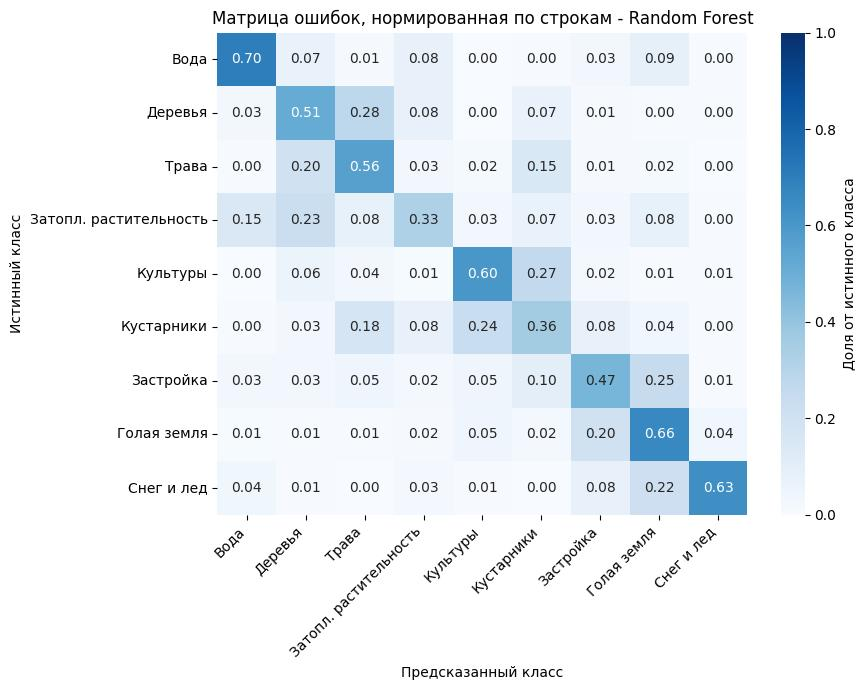

,Класс,producersAccuracy,consumersAccuracy
0,Вода,0.702439,0.723618
1,Деревья,0.514423,0.455319
2,Трава,0.561321,0.474104
3,Затопл. растительность,0.325123,0.488889
4,Культуры,0.605000,0.601990
5,Кустарники,0.360190,0.351852
6,Застройка,0.469697,0.500000
7,Голая земля,0.661538,0.479554
8,Снег и лед,0.633166,0.906475


In [ ]:
import seaborn as sns

best_matrix = matrices[best_name]

n_codes = max(CLASSES) + 1
labels = list(range(n_codes))

best_matrix_array = np.array(
    best_matrix.getInfo()
)

if best_matrix_array.shape[0] != n_codes:
  full = np.zeros((n_codes, n_codes), dtype=int)
  full[:best_matrix_array.shape[0], :best_matrix_array.shape[1]] = best_matrix_array
  best_matrix_array = full

prod = best_matrix.producersAccuracy().getInfo()
cons = best_matrix.consumersAccuracy().getInfo()

per_class = pd.DataFrame({
    "Класс": [DW_NAMES[c] for c in CLASSES],
    "producersAccuracy": [prod[c][0] for c in CLASSES],
    "consumersAccuracy": [cons[0][c] for c in CLASSES]
})

row_sums = best_matrix_array.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1
matrix_norm = best_matrix_array / row_sums

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    matrix_norm,
    annot=True, fmt=".2f", cmap="Blues",
    xticklabels=DW_NAMES, yticklabels=DW_NAMES,
    vmin=0, vmax=1, cbar_kws={'label': 'Доля от истинного класса'},
    ax=ax
)

ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")
ax.set_title(f"Матрица ошибок, нормированная по строкам - {best_name}")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("data/confusion_matrix.png", dpi=150)
plt.show()

display(pd.DataFrame(per_class))

**Вопрос:** Какие классы модель распознаёт лучше всего и хуже всего? С какими классами путается самый проблемный класс? Объясните, почему спектрально эти классы похожи.

**Ответ:** Лучше всего модель распознаёт класс воды, а хуже всего - класс кустарников. Самый проблемный класс путается с классом культур. Эти классы похожи похожи спектрально, потому что оба являются растительностью.

### **4.5. Важность признаков**

Случайный лес оценивает, насколько каждый признак помогает разделять классы. В GEE оценки возвращает метод `explain()` обученной модели (ключ `importance`).

**Задание 4.5.** Получите важность признаков модели `models['Random Forest']`, переведите её в доли от суммы и постройте горизонтальную столбчатую диаграмму, отсортированную по убыванию важности.

Важность признаков (доля от суммы):
B12     0.1333
B11     0.1291
NDVI    0.1249
NDWI    0.1231
B3      0.1231
B2      0.1227
B8      0.1223
B4      0.1214


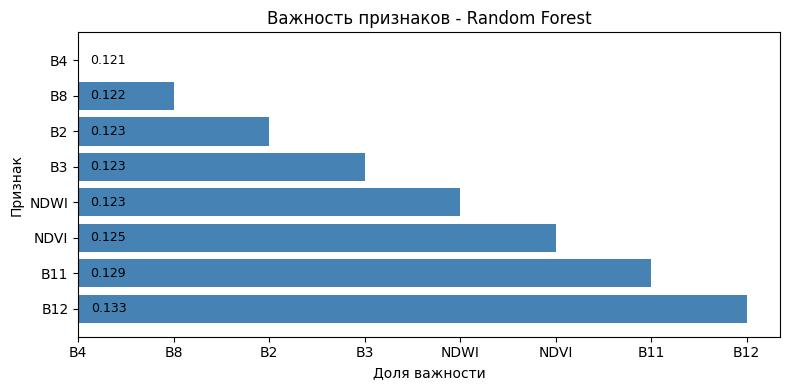

In [ ]:
explained = models['Random Forest'].explain().getInfo()

importances = explained.get('importance', {})

total = sum(importances.values())
shares = {k: v / total for k, v in importances.items()}

imp_series = pd.Series(shares).sort_values(ascending=False)
print("Важность признаков (доля от суммы):")
print(imp_series.map(lambda x: f"{x:.4f}").to_string())

fig, ax = plt.subplots(figsize=(8, max(4, 0.35 * len(imp_series))))
ax.barh(imp_series.index[::-1], imp_series.index[::-1], color='steelblue')
ax.set_xlabel("Доля важности")
ax.set_ylabel("Признак")
ax.set_title("Важность признаков - Random Forest")
ax.invert_yaxis()
for i, v in enumerate(imp_series.values[::-1]):
  ax.text(v, i, f"{v:.3f}", va='center', fontsize=9)
plt.tight_layout()
plt.savefig('data/feature_importance_rf.png', dpi=150)
plt.show()

**Вопрос:** Какие три признака наиболее важны? Какую долю важности дают инфракрасные каналы (B8, B8A, B11, B12) вместе с индексами, использующими их? Что это говорит о пользе каналов за пределами видимого диапазона?

**Ответ:** Наиболее важными являются признаки B12, B11, NDVI. Инфракрасные каналы (B8, B11, B12) вместе с индексами, использующими их (NDWI, NDVI), занимают долю важности, равную 0.632. Это означает, что основная часть информации о различии объектов и фона лежит за пределами видимого диапазона: видимые каналы описывают внешний вид поверхности, тогда как NIR и SWIR характеризуют её состав и состояние.

### **4.6. Карта классификации и сравнение с Dynamic World**

Для построения итоговой карты обучим лучшую модель заново **на всей выборке** (обучающей и проверочной частях): проверка уже выполнена, и лишние точки сделают модель только точнее.

**Задание 4.6.** Обучите классификатор `best_name` на всей выборке `samples`, классифицируйте `composite.select(FEATURES)`, экспортируйте карту в `data/classification.tif` (тип `int16`) и загрузите её в массив `classification`. Рассчитайте:
- долю пикселей, в которых классификация совпадает с Dynamic World;
- таблицу `areas`: площадь каждого класса по Dynamic World и по своей карте (га);
- маску несовпадений и покажите её на снимке рядом с обеими картами.

In [ ]:
final_clf = classifiers[best_name].train(
    features=train_sp,
    classProperty='class',
    inputProperties=LOCAL_BANDS
)
composite_classification = (
    sentinel_2024
    .select(LOCAL_BANDS)
    .classify(final_clf)
    .rename('class')
    .toInt16()
    .clip(roi)
)
export_georeferenced_raster(
    composite_classification,
    region=roi,
    filename='data/classification.tif',
    scale=SCALE,
    dtype='int16'
)

  0%|          |0/36 tiles [00:00<?]

'data/classification.tif'

Доля совпадений с Dynamic World: 0.5705 (1120777 из 1964540 пикселей)

Площади по классам (га):



,Код,Класс,"DW, га","Классификация, га","Разница, га"
0,0,Вода,3143.59,2447.07,-696.52
1,1,Деревья,5628.82,3571.18,-2057.64
2,2,Трава,1140.74,2754.88,1614.14
3,3,Затопл. растительность,264.82,1261.39,996.57
4,4,Культуры,164.50,946.40,781.90
5,5,Кустарники,2021.64,1554.04,-467.60
6,6,Застройка,2146.52,2441.89,295.37
7,7,Голая земля,5058.23,4302.16,-756.07
8,8,Снег и лед,76.54,366.39,289.85


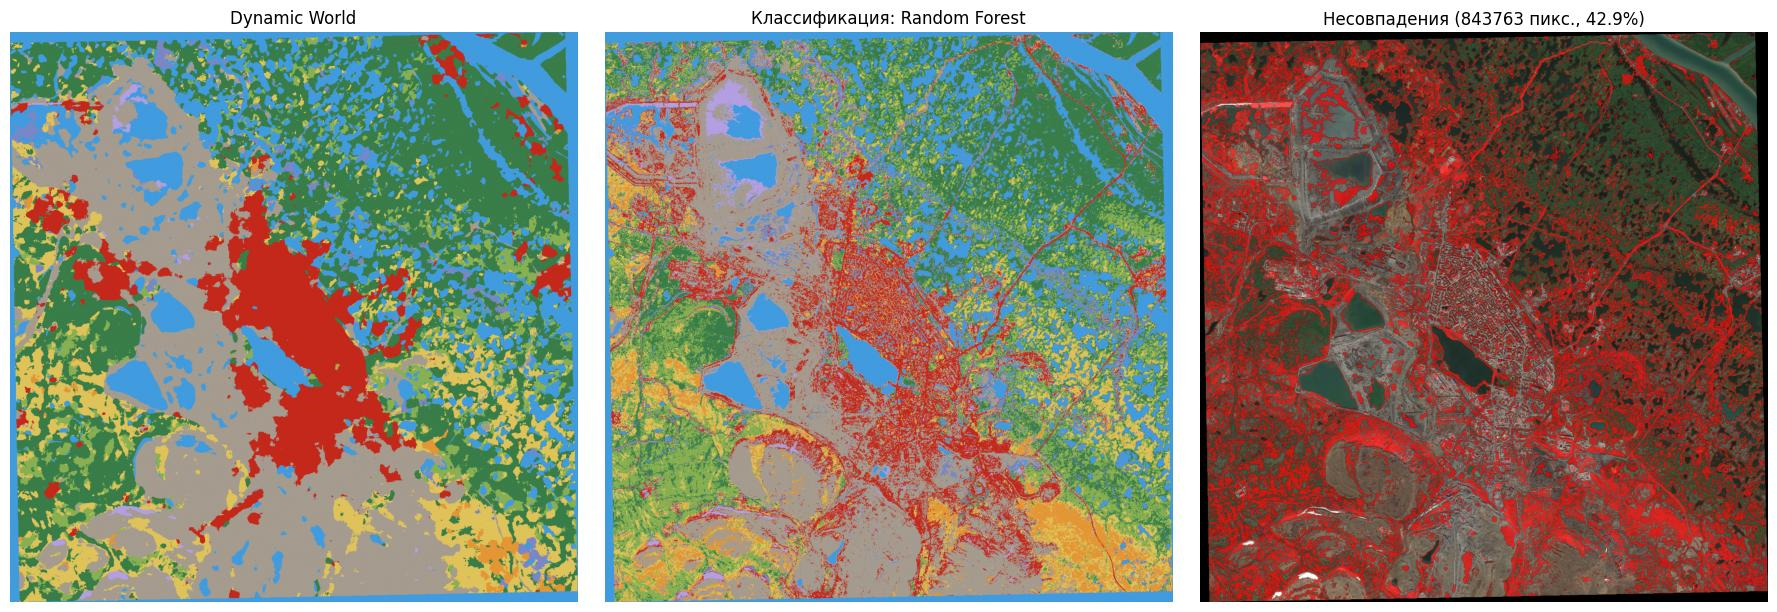

In [ ]:
result_of_clf = read_raster('data/classification.tif')[0]
H = min(result_of_clf.shape[0], dw.shape[0], bands.shape[1])
W = min(result_of_clf.shape[1], dw.shape[1], bands.shape[2])
result_of_clf = result_of_clf[:H, :W]
dw_crop = dw[:H, :W]
bands_crop = bands[:, :H, :W]

valid_crop = valid[:H, :W]
agree = (result_of_clf == dw_crop) & valid_crop
agreement_frac = agree.sum() / valid_crop.sum()
print(f"Доля совпадений с Dynamic World: {agreement_frac:.4f} "
        f"({agree.sum()} из {valid_crop.sum()} пикселей)")

def class_areas(arr, valid_mask, classes):
  out = {}
  for c in classes:
    out[c] = int(((arr == c) & valid_mask).sum()) * PIXEL_AREA_HA
  return out

dw_areas = class_areas(dw_crop, valid_crop, CLASSES)
clf_areas = class_areas(result_of_clf, valid_crop, CLASSES)

areas = pd.DataFrame({
    "Код" : CLASSES,
    "Класс": [DW_NAMES[c] for c in CLASSES],
    "DW, га": [round(dw_areas[c], 2) for c in CLASSES],
    "Классификация, га": [round(clf_areas[c], 2) for c in CLASSES],
    "Разница, га": [round(clf_areas[c] - dw_areas[c], 2) for c in CLASSES]
})

print("\nПлощади по классам (га):\n")
display(areas)

mismatch = (result_of_clf != dw_crop) & valid_crop
dw_cmap = ListedColormap(DW_COLORS)
#rgb = stretch(np.dstack([bands[2], bands[1], bands[0]]), 0.3) ** (1 / 1.4)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(dw_crop, cmap=dw_cmap, vmin=0, vmax=8)
axes[0].set_title("Dynamic World")

axes[1].imshow(result_of_clf, cmap=dw_cmap, vmin=0, vmax=8)
axes[1].set_title(f"Классификация: {best_name}")

axes[2].imshow(rgb)
axes[2].imshow(
    np.ma.masked_where(~mismatch, mismatch),
    cmap=ListedColormap(['red']), alpha=0.7
)
axes[2].set_title(f"Несовпадения ({mismatch.sum()} пикс., "
                  f"{(1 - agreement_frac) * 100:.1f}%)")

for ax in axes:
  ax.axis('off')

plt.tight_layout()
plt.show()

**Вопрос:** Какова доля совпадения карт? Где сосредоточены несовпадения — на границах объектов, в каких-то конкретных типах местности? Площади каких классов различаются сильнее всего?

**Ответ:**

Доля совпадения карт. Суммарная «масса» перепутанных пикселей ≈ 3 978 га из 19 645 га, что даёт оценку совпадения ≈ 80 %.

Где сосредоточены несовпадения. Ошибки группируются в двух местах. (1) На границах объектов — пары «деревья↔кустарники↔трава», «вода↔затопленная растительность», «голая земля↔застройка» дают симметричные по знаку расхождения, что типично для смешанных пикселей на контурах лесных массивов, береговой линии и опушек. (2) Целыми участками по конкретным типам местности — затопленная растительность (265 → 1261 га) и культуры (165 → 946 га) расходятся в 4.8–5.8 раза.

Сильнее всего различаются площади: абсолютно — деревья (−2058 га) и трава (+1614 га); относительно — культуры (×5.75), затопленная растительность (×4.76) и снег и лёд (×4.79).

**Вопрос:** Рассмотрите объекты, которые вы описали в гипотезах (таблица 2). К каким классам отнесли их Dynamic World и ваша модель? Может ли классификатор, обученный по разметке Dynamic World, выделить такие объекты как отдельный класс? Почему?

**Ответ:**

- Для объекта 1 моя модель более точно выделила дорогу и лежащий вдоль неё снег. Dynamic World одну часть объекта отмечает как застройку, другую - как голую землю, при этом нет чёткой геометрии.
- Для обекта 2 Dynamic World всю территорию города обозначает сплошной застройкой, в то время как моя модель старается выделить геометрию зданий и обозначить наличие кустарников (городское озеленение).
- Для объекта 3 моя модель в некоторых местах склоны холмов обозначает застройкой, в то время как Dynamic World рисует голую землю и только в некоторых местах воду

### **4.7. Выводы по разделу 4**

Опишите, насколько точно модель воспроизводит Dynamic World при честной проверке, какие классы и признаки для неё важнее, и в чём главное ограничение обучения по готовой карте.

**Вывод:**

Точность воспроизведения DW. При честной проверке модель воспроизводит DW умеренно: Accuracy ≈ 0.536, Kappa ≈ 0.478. Совпадение по площадям ≈ 80 %.

Важнейшие классы и признаки. Лучше всего воспроизводятся классы с резким IR-сигналом — вода, голая земля, застройка; хуже всего — переходные: затопленная растительность, культуры, снег и лёд, а также путаница деревья/трава/кустарники. Самыми важными признаками являются B12, B11, NDVI, а IR каналы и индексы (B8, B11, B12, NDVI, NDWI) дают 63.2 % важности.

Главное ограничение. Обучение по готовой карте означает, что модель учится воспроизводить решения DW, включая его ошибки и смещения. Потолок качества равен качеству DW; наследуются дисбаланс классов, региональные и сезонные смещения DW; классы, которых DW не видит, невозможно выучить в принципе.



---

## **5. Кластеризация в Google Earth Engine: поиск того, чего нет в легенде**

Классификатор умеет только то, чему его научили: каждому пикселю он присваивает один из классов разметки. Кластеризация не знает никаких классов и группирует пиксели по сходству спектра. Если на территории есть объекты, спектрально непохожие на всё остальное, они могут образовать собственный кластер — даже если в легенде для них нет класса и на снимке в естественных цветах они почти не видны.

### **5.1. Стандартизация признаков в GEE**

Кластеризовать будем по восьми признакам `LOCAL_BANDS`: шести каналам отражения и индексам NDVI и NDWI. Отражение меняется в пределах 0–0,6, а индексы — от −1 до 1, поэтому без масштабирования индексы определяли бы расстояния между пикселями сильнее каналов. Стандартизация приводит каждый признак к среднему 0 и стандартному отклонению 1: $z = (x - \mu) / \sigma$.

> 📚 **Подсказка:** лекция «Кластеризация спутниковых снимков в среде Google Earth Engine», **раздел 2.5** (масштабирование признаков); в GEE среднее и стандартное отклонение каналов по области даёт `image.reduceRegion(ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True), region, scale=..., bestEffort=True)`, ключи результата — `B2_mean`, `B2_stdDev` и т. д.

**Задание 5.1.** Допишите функцию `standardize(image, region)`: она рассчитывает по области средние и стандартные отклонения всех каналов (`scale=30` — для оценки статистик этого достаточно), возвращает стандартизированное изображение и два списка — средние и стандартные отклонения в порядке каналов. Получите `cluster_input, means, stds`.

In [ ]:
def standardize(image, region):
    """Стандартизация каналов изображения по статистикам области: (x - среднее) / стандартное отклонение."""
    names = image.bandNames().getInfo()
    stats = image.reduceRegion(
        ee.Reducer.mean().combine(
            ee.Reducer.stdDev(),
            sharedInputs=True
        ),
        region,
        scale=30,
        bestEffort=True
    ).getInfo()
    means = [stats[f"{name}_mean"] for name in names]
    stds = [stats[f"{name}_stdDev"] for name in names]
    safe_stds = [s if (s is not None and s != 0) else 1.0 for s in stds]
    standardized = image.subtract(ee.Image.constant(means)) \
                        .divide(ee.Image.constant(safe_stds)) \
                        .rename(names)
    return standardized, means, stds

cluster_input, means, stds = standardize(sentinel_2024.select(LOCAL_BANDS), roi)

stats_df = pd.DataFrame({
    "Канал": LOCAL_BANDS,
    "Среднее": [round(m, 4) if m is not None else None for m in stds],
    "Стандартное отклонение": [round(s, 4) if s is not None else None for s in stds]
})

display(stats_df)

,Канал,Среднее,Стандартное отклонение
0,B2,0.0279,0.0279
1,B3,0.0279,0.0279
2,B4,0.0374,0.0374
3,B8,0.0874,0.0874
4,B11,0.0597,0.0597
5,B12,0.0436,0.0436
6,NDVI,0.3130,0.3130
7,NDWI,0.2992,0.2992


### **5.2. K-средних на серверах GEE при разных K**

> 📚 **Подсказка:** лекция «Кластеризация спутниковых снимков в среде Google Earth Engine», **раздел 3.5** (`ee.Clusterer.wekaKMeans`, `train`, `cluster`).

Число кластеров заранее неизвестно. При малом $K$ редкие объекты «прилипают» к крупным кластерам, при большом — крупные однородные поверхности дробятся на части. Поэтому построим разбиения сразу для нескольких $K$ и сравним их.

**Задание 5.2.** Получите обучающую выборку `training` из `cluster_input` (10 000 пикселей, `scale=SCALE`, `projection=utm_crs(roi)`, `seed=42`, `tileScale=4`). Для `K_LIST = [6, 12, 18]` обучите `ee.Clusterer.wekaKMeans(nClusters=K, init=1, seed=42)` и кластеризуйте `cluster_input`. Объедините карты в одно изображение `clusters` с каналами `K6`, `K12`, `K18` (`ee.Image.cat`), покажите кластеры при $K = 12$ на интерактивной карте (`randomVisualizer()`) и экспортируйте `clusters` в `data/clusters.tif` (тип `int16`). Загрузите результат в массив `cluster_maps` (каналы — разные $K$).

In [ ]:
K_LIST = [6, 12, 18]

training = cluster_input.sample(
    region=roi,
    scale=SCALE,
    projection=utm_crs(roi),
    numPixels=10000,
    seed=42,
    tileScale=4
)

cluster_imgs = {}

for K in K_LIST:
    clusterer = ee.Clusterer.wekaKMeans(nClusters=K, init=1, seed=42).train(training)
    cluster_imgs[K] = (cluster_input.cluster(clusterer).rename(f'K{K}').toInt16())

clusters = ee.Image.cat([cluster_imgs[K] for K in K_LIST])

vis_k12 = cluster_imgs[12].randomVisualizer()

export_georeferenced_raster(
    image=clusters,
    region=roi,
    filename="data/clusters.tif",
    scale=SCALE,
    dtype='int16'
)

cluster_maps = read_raster('data/clusters.tif')
for i, k in enumerate(K_LIST):
  uniq = np.unique(cluster_maps[i])
  print(f"K={k}, канал {i}, кластеры {uniq.min()}..{uniq.max()} ({len(uniq)} уникальных)")

  0%|          |0/108 tiles [00:00<?]

K=6, канал 0, кластеры -32768..5 (7 уникальных)
K=12, канал 1, кластеры -32768..11 (13 уникальных)
K=18, канал 2, кластеры -32768..17 (19 уникальных)


In [ ]:
m = geemap.Map()
m.centerObject(roi, 10)
m.addLayer(vis_k12, {}, 'KMeans K=12')
m.addLayer(roi, {'color': 'red'}, 'ROI', False)
m

Map(center=[69.34998106248189, 88.20033996158713], controls=(WidgetControl(options=['position', 'transparent_b…

### **5.3. Площади и спектральные профили кластеров**

> 📚 **Подсказка:** лекция «Кластеризация спутниковых снимков в среде Google Earth Engine», **разделы 3.3–3.4** (спектральные профили, состав кластеров по Dynamic World).

Кроме профилей, оценим **необычность** каждого кластера — расстояние от его центроида до «среднего» пикселя территории в пространстве стандартизированных признаков. После стандартизации средний пиксель находится в начале координат, поэтому необычность — это просто длина вектора центроида: $\lVert c_k
Vert = \sqrt{\sum_j c_{kj}^2}$. Кластеры фоновых поверхностей, занимающих большую часть территории, лежат близко к среднему, а спектрально непохожие на фон группы — далеко от него, независимо от их площади. Центроиды кластеров GEE вычислим сами: это средние стандартизированные признаки пикселей каждого кластера.

**Задание 5.3.** Для разбиения с $K = 12$ (`labels = cluster_maps[1]`):
- стандартизируйте признаки пикселей `pixels` теми же `means` и `stds`, что и в GEE (массив `z`), и рассчитайте центроиды кластеров `centroids` (форма $(K, 8)$);
- постройте таблицу `profiles`: для каждого кластера — площадь (га), доля площади (%), необычность и средние значения восьми признаков `LOCAL_BANDS` (по массиву `bands`); отсортируйте её по площади;
- покажите карту кластеров рядом со снимком и график спектральных профилей шести каналов (по оси X — каналы, по оси Y — среднее отражение, по линии на кластер).

In [ ]:
K = 12
labels = cluster_maps[K_LIST.index(K)]
cluster_colors = plt.cm.tab20(np.linspace(0, 1, 20))[:K]
cluster_cmap = ListedColormap(cluster_colors)

centroids: shape=(12, 8), K=12, C=8

Профили кластеров (отсортированы по площади):


,Кластер,"Площадь, га","Доля, %",Необычность,B2,B3,B4,B8,B11,B12,NDVI,NDWI
0,9,3723.9,18.96,0.945,0.0753,0.0888,0.0997,0.1137,0.1250,0.1126,0.0662,-0.1256
1,3,3038.3,15.47,0.753,0.0430,0.0645,0.0573,0.2345,0.1977,0.1215,0.6041,-0.5656
2,1,2557.2,13.02,0.771,0.0308,0.0562,0.0343,0.3162,0.1703,0.0877,0.8024,-0.6962
3,7,2074.0,10.56,0.885,0.0614,0.0689,0.0722,0.0793,0.0799,0.0731,0.0476,-0.0711
4,11,1698.0,8.64,1.439,0.0985,0.1168,0.1334,0.1557,0.1705,0.1538,0.0790,-0.1468
5,0,1576.8,8.03,0.926,0.0539,0.0697,0.0728,0.1554,0.1477,0.1074,0.3607,-0.3788
6,2,1298.9,6.61,0.930,0.0329,0.0512,0.0398,0.1902,0.1257,0.0746,0.6521,-0.5721
7,10,1276.0,6.50,1.108,0.0650,0.0807,0.0933,0.1839,0.2211,0.1662,0.3300,-0.3908
8,8,869.9,4.43,0.874,0.0239,0.0298,0.0211,0.0236,0.0245,0.0164,0.0774,0.1257
9,5,821.7,4.18,1.026,0.0428,0.0536,0.0324,0.0170,0.0100,0.0083,-0.2905,0.5150


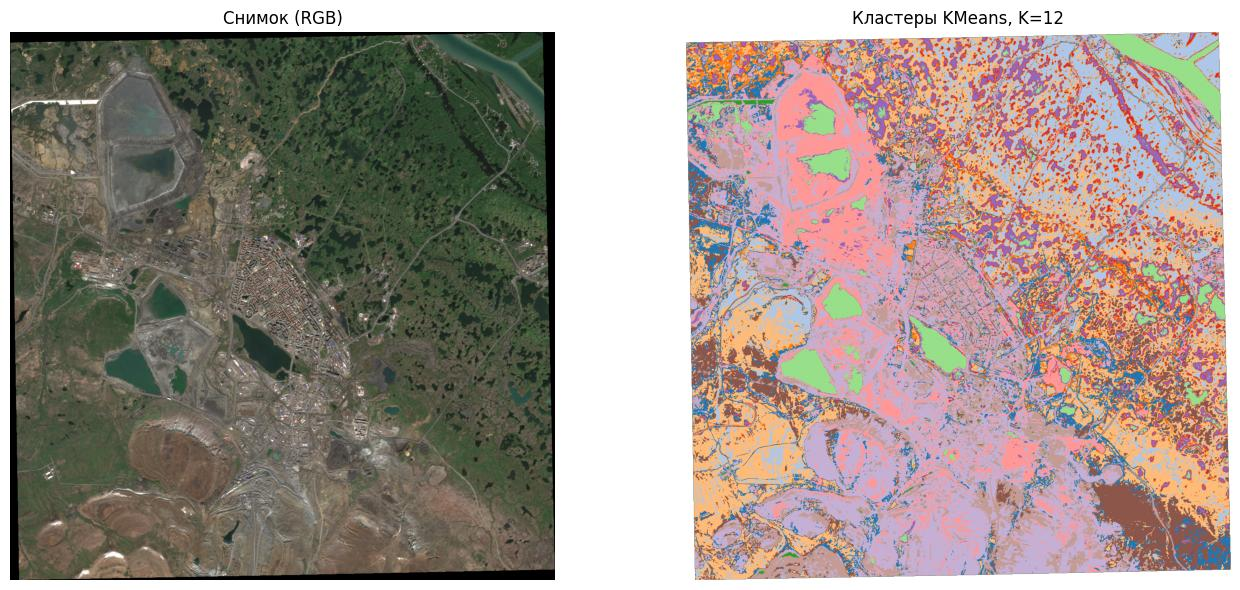

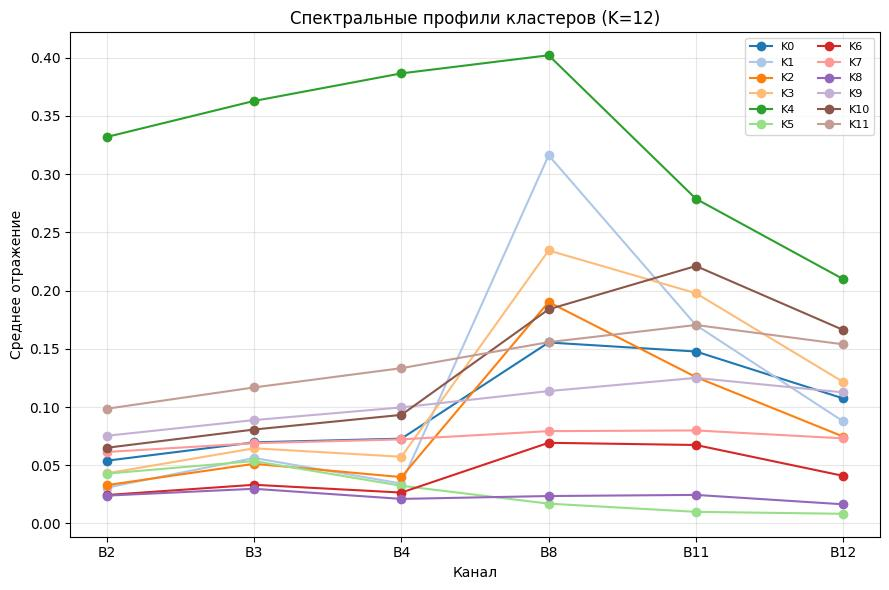

In [ ]:
H = min(cluster_maps.shape[1], bands.shape[1], dw.shape[0])
W = min(cluster_maps.shape[2], bands.shape[2], dw.shape[1])

labels = cluster_maps[1][:H, :W].astype(int)
bands_crop = bands[:, :H, :W]
valid_crop = valid[:H, :W]

means_arr = np.array(means, dtype=np.float64)
stds_arr = np.array(stds, dtype=np.float64)
stds_arr[stds_arr == 0] = 1.0

pixels = bands_crop.reshape(bands_crop.shape[0], -1).T
z = (pixels - means_arr) / stds_arr

K = labels.max() + 1
C = z.shape[1]
centroids = np.full((K, C), np.nan)
for k in range(K):
  mask_k = (labels.ravel() == k) & valid_crop.ravel()
  if mask_k.sum() > 0:
    centroids[k] = z[mask_k].mean(axis=0)
print(f'centroids: shape={centroids.shape}, K={K}, C={C}')

unusualness = np.zeros(K)
for k in range(K):
    mask_k = (labels.ravel() == k) & valid_crop.ravel()
    if mask_k.sum() > 0:
        diff = z[mask_k] - centroids[k]
        unusualness[k] = np.sqrt((diff ** 2).sum(axis=1)).mean()

area_px = np.array([((labels == k) & valid_crop).sum() for k in range(K)])
area_ha = area_px * PIXEL_AREA_HA
share_pct = 100.0 * area_px / valid_crop.sum()

band_means = np.full((K, C), np.nan)
for k in range(K):
    mask_k = (labels.ravel() == k) & valid_crop.ravel()
    if mask_k.sum() > 0:
        band_means[k] = pixels[mask_k].mean(axis=0)

profiles = pd.DataFrame({
    'Кластер':      np.arange(K),
    'Площадь, га':  area_ha.round(1),
    'Доля, %':      share_pct.round(2),
    'Необычность':  unusualness.round(3),
})
for j, name in enumerate(LOCAL_BANDS):
    profiles[name] = band_means[:, j].round(4)

profiles = profiles.sort_values('Площадь, га', ascending=False).reset_index(drop=True)
print('\nПрофили кластеров (отсортированы по площади):')
display(profiles)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(rgb)
axes[0].set_title('Снимок (RGB)')
axes[1].imshow(np.where(valid_crop, labels, np.nan), cmap=cluster_cmap, vmin=0, vmax=K - 1)
#axes[1].imshow(np.ma.masked_where(~valid_crop, labels), cmap=cluster_cmap, vmin=0, vmax=K - 1)
#axes[1].imshow(labels, cmap=cluster_cmap, interpolation='nearest')
axes[1].set_title(f'Кластеры KMeans, K={K}')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig('data/clusters_k12_map.png', dpi=150)
plt.show()

spec_idx = list(range(min(6, len(LOCAL_BANDS))))
spec_names = [LOCAL_BANDS[i] for i in spec_idx]

fig, ax = plt.subplots(figsize=(9, 6))
for k in range(K):
    ax.plot(spec_names, band_means[k, spec_idx], marker='o', color=cluster_colors[k], label=f'K{k}')
ax.set_xlabel('Канал')
ax.set_ylabel('Среднее отражение')
ax.set_title(f'Спектральные профили кластеров (K={K})')
ax.legend(ncol=2, fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('data/clusters_k12_profiles.png', dpi=150)
plt.show()

### **5.4. Состав кластеров по Dynamic World и по своей классификации**

**Задание 5.4.** Постройте две таблицы сопряжённости, нормированные по строкам (%): кластер × класс Dynamic World (`dw`) и кластер × класс вашей классификации (`classification`). Строки упорядочите так же, как в `profiles` (по площади). Выведите их рядом в виде тепловых карт.

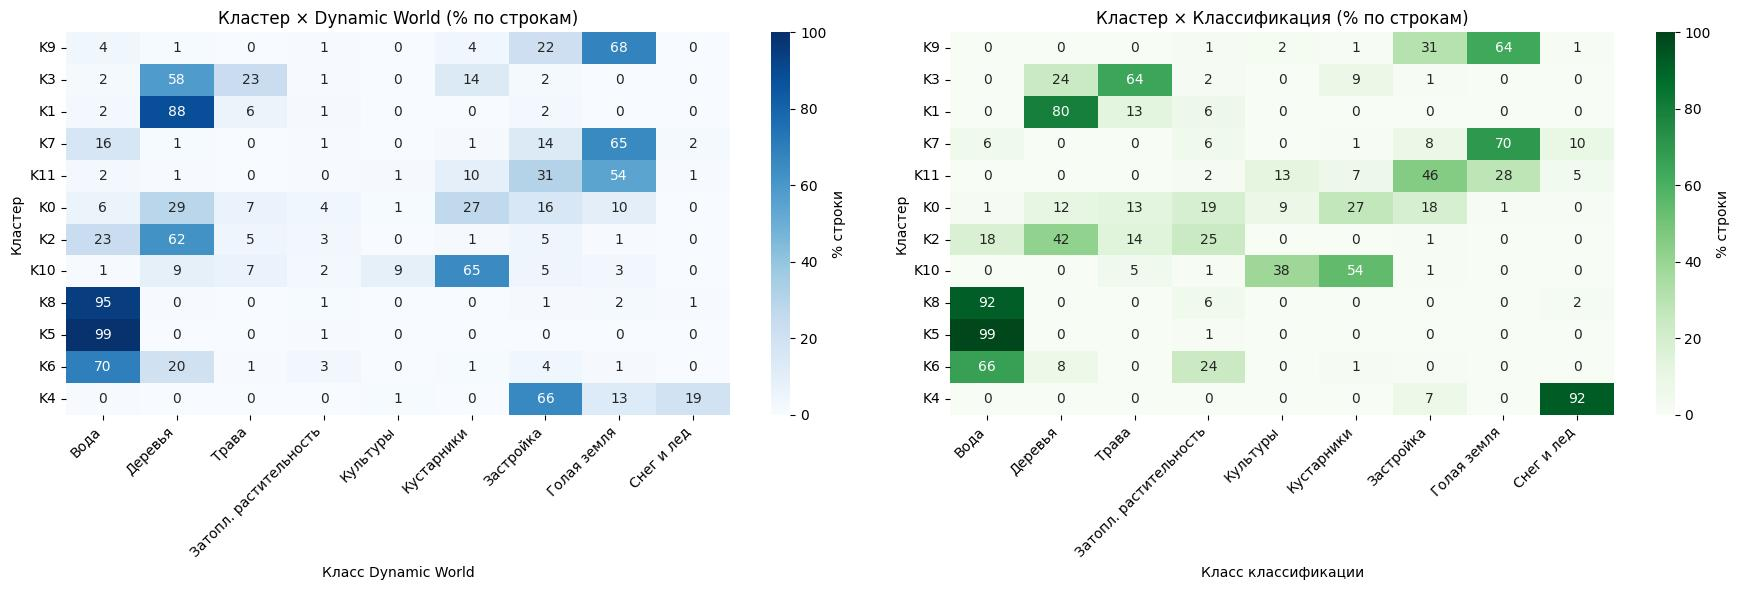

In [ ]:
H = min(labels.shape[0], dw.shape[0], result_of_clf.shape[0])
W = min(labels.shape[1], dw.shape[1], result_of_clf.shape[1])

labels_crop = labels[:H, :W]
dw_crop = dw[:H, :W]
cl_crop = result_of_clf[:H, :W]
valid_crop = valid[:H, :W]

cluster_order = profiles['Кластер'].astype(int).tolist()

def contingency_pct(cluster_arr, class_arr, valid_mask,
                    cluster_order, classes, class_names):
    rows = []
    for k in cluster_order:
        mask_k = (cluster_arr == k) & valid_mask
        n_k = mask_k.sum()
        row = []
        for c in classes:
            n = ((class_arr == c) & mask_k).sum()
            row.append(100.0 * n / n_k if n_k > 0 else 0.0)
        rows.append(row)
    df = pd.DataFrame(
        rows,
        index=[f'K{k}' for k in cluster_order],
        columns=[class_names[c] for c in classes]
    )
    return df

ct_dw = contingency_pct(labels_crop, dw_crop, valid_crop, cluster_order, CLASSES, DW_NAMES)
ct_cl = contingency_pct(labels_crop, cl_crop, valid_crop, cluster_order, CLASSES, DW_NAMES)

#print('Кластер × Dynamic World (% по строкам):')
#print(ct_dw.round(1).to_string())
#print('\nКластер × Классификация (% по строкам):')
#print(ct_cl.round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(18, max(6, 0.5 * len(cluster_order))))

sns.heatmap(
    ct_dw, annot=True, fmt='.0f', cmap='Blues',
    vmin=0, vmax=100, cbar_kws={'label': '% строки'},
    ax=axes[0]
)
axes[0].set_title('Кластер × Dynamic World (% по строкам)')
axes[0].set_xlabel('Класс Dynamic World')
axes[0].set_ylabel('Кластер')

sns.heatmap(
    ct_cl, annot=True, fmt='.0f', cmap='Greens',
    vmin=0, vmax=100, cbar_kws={'label': '% строки'},
    ax=axes[1]
)
axes[1].set_title('Кластер × Классификация (% по строкам)')
axes[1].set_xlabel('Класс классификации')
axes[1].set_ylabel('Кластер')

for ax in axes:
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    plt.setp(ax.get_yticklabels(), rotation=0)

plt.tight_layout()
plt.savefig('data/contingency_maps.png', dpi=150)
plt.show()

**Задание 5.4 (продолжение).** По профилям, составу и виду на карте дайте названия всем кластерам и заполните таблицу. Названия — ваша интерпретация, а не результат алгоритма.

#### **Таблица 3. Интерпретация кластеров (K = 12)**

| Кластер | Площадь, га | Спектральный профиль | Состав по Dynamic World | Название |
|---|---|---|---|---|
| К0	| 1576.8 | Средний NIR (B8 = 0.155), Red 0.073; NDVI 0.361, NDWI −0.379	| 29 % Деревья, 27 % Кустарники, 16 % Голая земля, 12 % Трава, 13 % Застройка | Смешанный разреженный древесно-кустарниковый покров |
| К1 | 2557.2 |	Максимальный NIR (B8≈0.316), NDVI максимальный (0.802), NDWI −0.696. Классический спектр густой здоровой растительности. |	88 % Деревья, 6 % Трава, 2 % Вода, 2 % Застройка; почти нет кустарников. |	Густой лес / сомкнутый древесный полог |
| K2 |	1298.9 |	Высокий NIR (B8≈0.190), NDVI 0.652, NDWI −0.572. Растительный спектр, но слабее K1/K3. |	62 % Деревья, 23 % Вода, 5 % Трава, 5 % Застройка, 3 % Затопл. растительность.	| Лес у воды / пойменная древесная растительность |
| K3 |	3038.3 | Высокий NIR (B8≈0.234), заметный SWIR (B11≈0.198), NDVI высокий (0.604), NDWI сильно отрицательный (−0.566). Типичный «растительный» спектр с пиком в NIR.	| 58 % Деревья, 23 % Трава, 14 % Кустарники; вода/застройка/голая земля 2 %. | Смешанная древесно-кустарниковая растительность (лес с подлеском, опушки) |
| K4 | 36.8 |	Резко выделяется: яркость видимых каналов в 4–5 раз выше среднего (B2≈0.332, B3≈0.363, B4≈0.387, B8≈0.402), высокий B11/B12 (0.279/0.210), NDVI 0.022, NDWI −0.054. Необычность 6.02 — на порядок выше остальных. |	~66 % Застройка, ~19 % Снег и лёд, ~13 % Голая земля, ~1 % Культуры; деревья/трава/вода ≈ 0. |	Крыши, свежий бетон/металл, снег/лёд, техногенные точечные объекты |
| K5 |	821.7	| Минимальная яркость в NIR/SWIR (B8≈0.017, B11≈0.010, B12≈0.008), NDVI −0.291, NDWI +0.515 (сильно положительный).	| 99 % Вода, 1 % Затопл. растительность. |	Глубоководные участки / чистая вода |
| K6 |	673.8 |	Низкий NIR (B8≈0.069), умеренный NDVI (0.439), NDWI −0.327, низкий SWIR (B11≈0.067).	| ~70 % Вода, ~20 % Деревья, 3 % Затопл. растительность, 4 % Застройка.	| Вода с древесной/затопленной растительностью (берега, поймы, заболоченные водоёмы) |
| K7 |	2074.0	| Низкая яркость по всем каналам (B2≈0.061, B8≈0.079, B11≈0.080), NDVI низкий (0.048), NDWI ≈ −0.07. Тёмный, ровный спектр.	| 65 % Голая земля, 16 % Вода, 14 % Застройка, 2 % Снег.	| Тёмные техногенные/антропогенные поверхности (асфальт, тени, нарушенные грунты) |
| K8 |	869.9	| Очень низкая яркость всех каналов (B2≈0.024, B11≈0.025, B12≈0.016), NDVI 0.077, NDWI +0.126 (единственный с положительным NDWI).	| 95 % Вода, 2 % Голая земля, 1 % Застройка, 1 % Затопл. растительность; деревья/трава ≈ 0.	| Открытая вода (озёра, реки, водохранилища) |
| K9	| 3723.9	| Средняя яркость во всех каналах (B2≈0.075, B4≈0.100, B11≈0.125), NDVI низкий (0.066), NDWI слабо отрицательный (−0.126). Плоский «серый» спектр без выраженного пика в NIR. |	68 % Голая земля, 22 % Застройка, 4 % Кустарники, 4 % Вода.	| Голая земля / техногенные поверхности (открытые грунты, стройплощадки, карьеры) |
| K10 |	1276.0 |	Высокий SWIR (B11≈0.221, B12≈0.166), NIR 0.184, NDVI 0.330, NDWI −0.391. «Влажно-растительный» профиль.	| 65 % Кустарники, 9 % Деревья, 9 % Культуры, 7 % Трава, 5 % Застройка, 2 % Затопл. растительность. |	Кустарниковая / влажная луговая растительность (болотистые луга, кустарники) |
| K11	| 1698.0	| Повышенная яркость видимых каналов (B4≈0.133), высокий SWIR (B11≈0.171, B12≈0.154), NDVI низкий (0.079), NDWI −0.147. Яркий «сухой/техногенный» профиль. |	54 % Голая земля, 31 % Застройка, 10 % Кустарники, 1 % Культуры; вода/деревья 2 %. |	Яркая застройка / открытые грунты (посёлки, промзоны, песчаные/сухие поверхности) |

**Таблица 3:** _______________

### **5.5. Необычные кластеры: «иголка в стоге сена»**

Первые кандидаты на интересные объекты — кластеры, далёкие от фона: алгоритм отвёл им собственный центроид, потому что их спектр не похож на спектр основной части территории. Часто это и самые маленькие кластеры, но не всегда: крупный карьер или большая гарь могут занимать сотни гектаров и всё же резко отличаться от окружающего леса, а несколько маленьких кластеров могут оказаться оттенками фона. Поэтому ориентируемся на необычность, а площадь учитываем при интерпретации.

In [ ]:
#@title Готовая функция: фрагменты снимка с подсветкой пикселей маски
def zoom_views(mask, n=3, size=60, color=(1, 0, 0), title=''):
    """n фрагментов с наибольшей плотностью пикселей маски: снимок, B12-B8-B4 и подсветка."""
    step = 2 * size
    density = np.add.reduceat(np.add.reduceat(mask.astype(int), np.arange(0, H, step), axis=0), np.arange(0, W, step), axis=1)
    best = np.dstack(np.unravel_index(np.argsort(density.ravel())[::-1][:n], density.shape))[0]
    fig, axes = plt.subplots(3, n, figsize=(6 * n, 18))
    for j, (r, c) in enumerate(best):
        r = min(max(r * step + size, size), H - size)
        c = min(max(c * step + size, size), W - size)
        window = np.s_[r - size:r + size, c - size:c + size]
        highlight = rgb[window].copy()
        highlight[mask[window]] = color
        for i, img in enumerate([rgb[window], swir[window], highlight]):
            axes[i, j].imshow(img)
            axes[i, j].axis('off')
        axes[0, j].set_title(f'Фрагмент {j + 1}: строка {r}, столбец {c}')
    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

**Задание 5.5.** Выведите три кластера с наибольшей необычностью с площадью и двумя главными классами Dynamic World и покажите для каждого карту расположения пикселей на снимке и фрагменты крупным планом (`zoom_views(labels == k, title=...)`). Затем выберите кластеры, которые вы считаете «иголками» — объектами, не имеющими своего класса в Dynamic World, — и запишите их номера в список `NEEDLES`.

Три кластера с наибольшей необычностью:
  K4: 36.8 га, DW: Застройка 66%, Снег и лед 19%
  K11: 1698.0 га, DW: Голая земля 54%, Застройка 31%
  K10: 1276.0 га, DW: Кустарники 65%, Деревья 9%


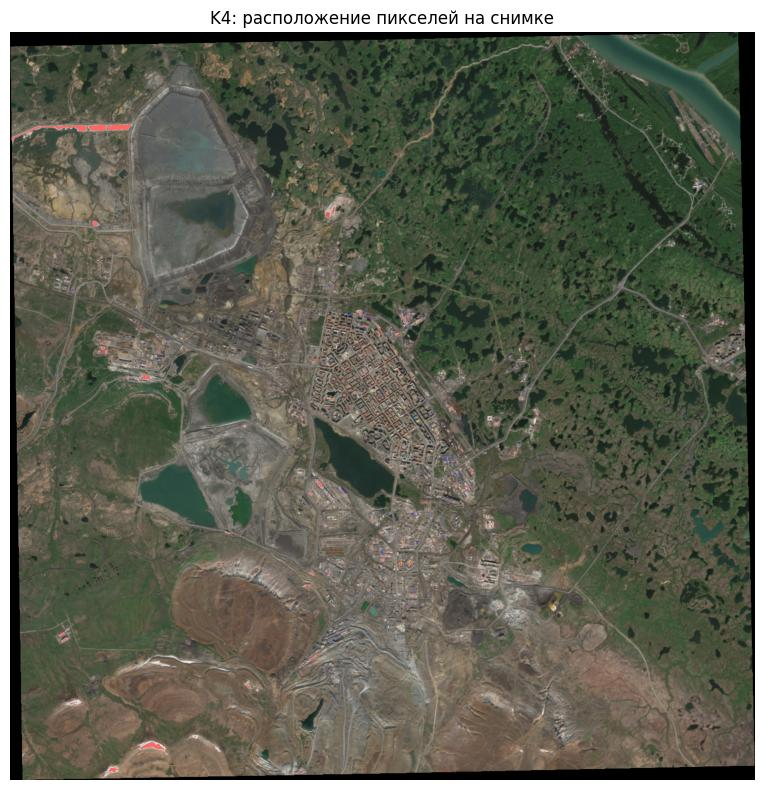

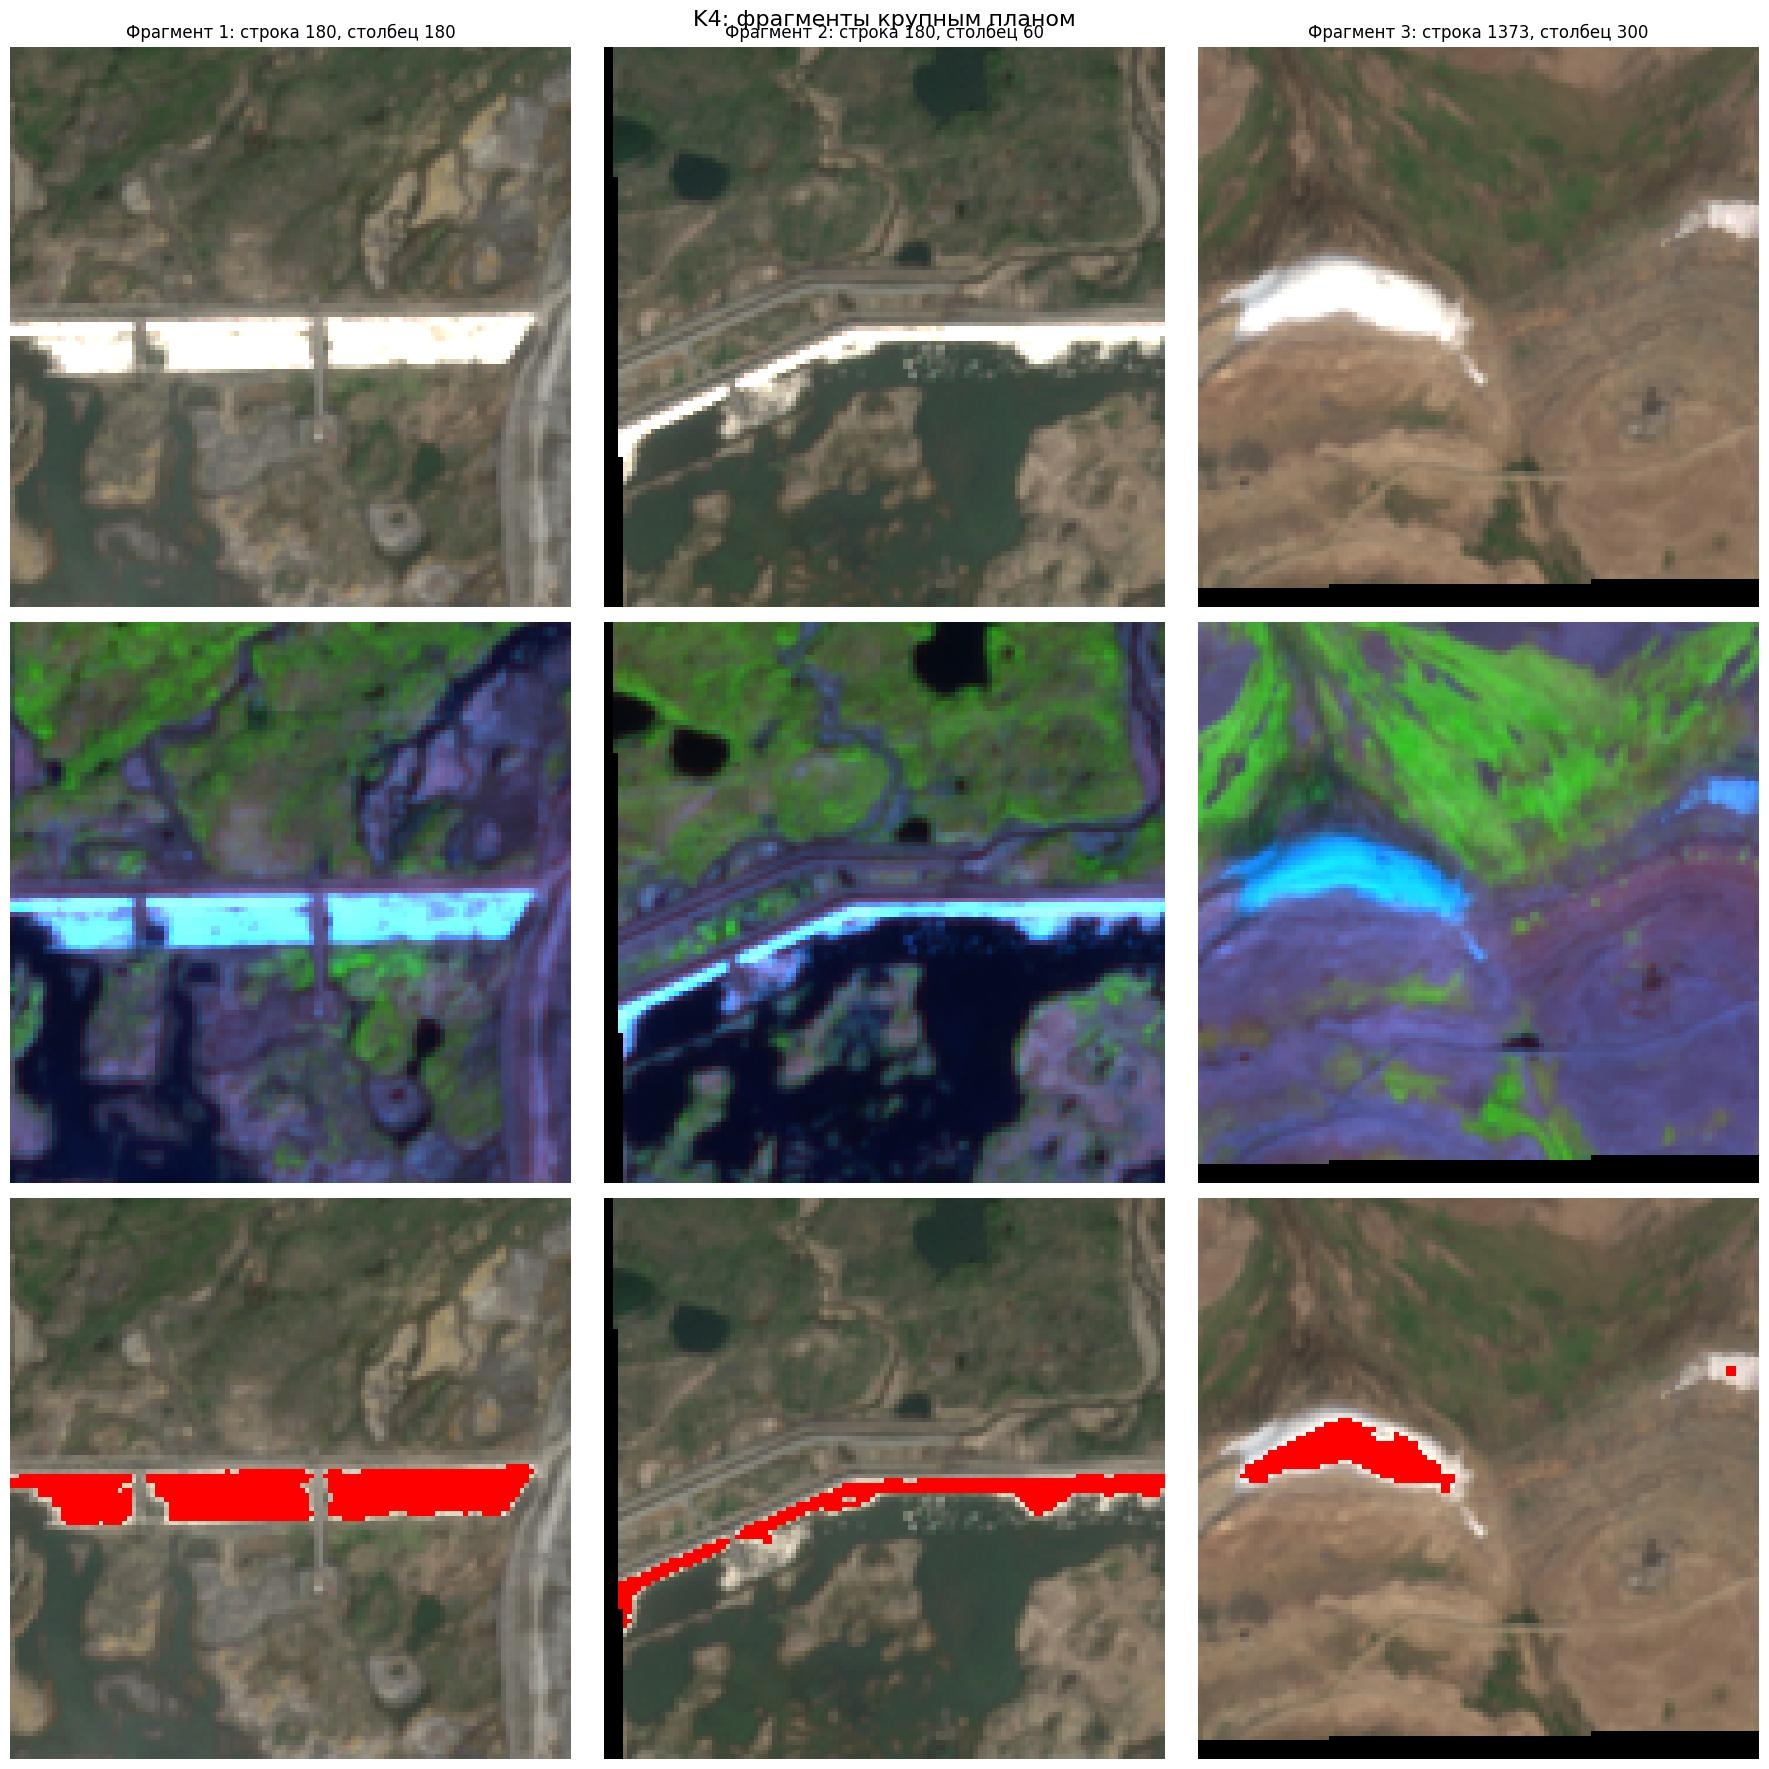

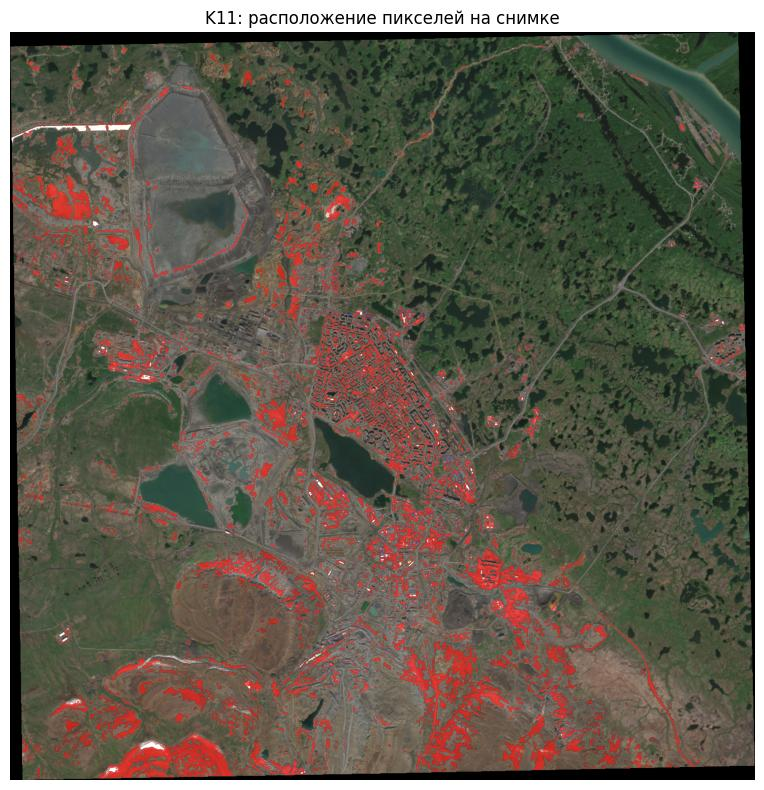

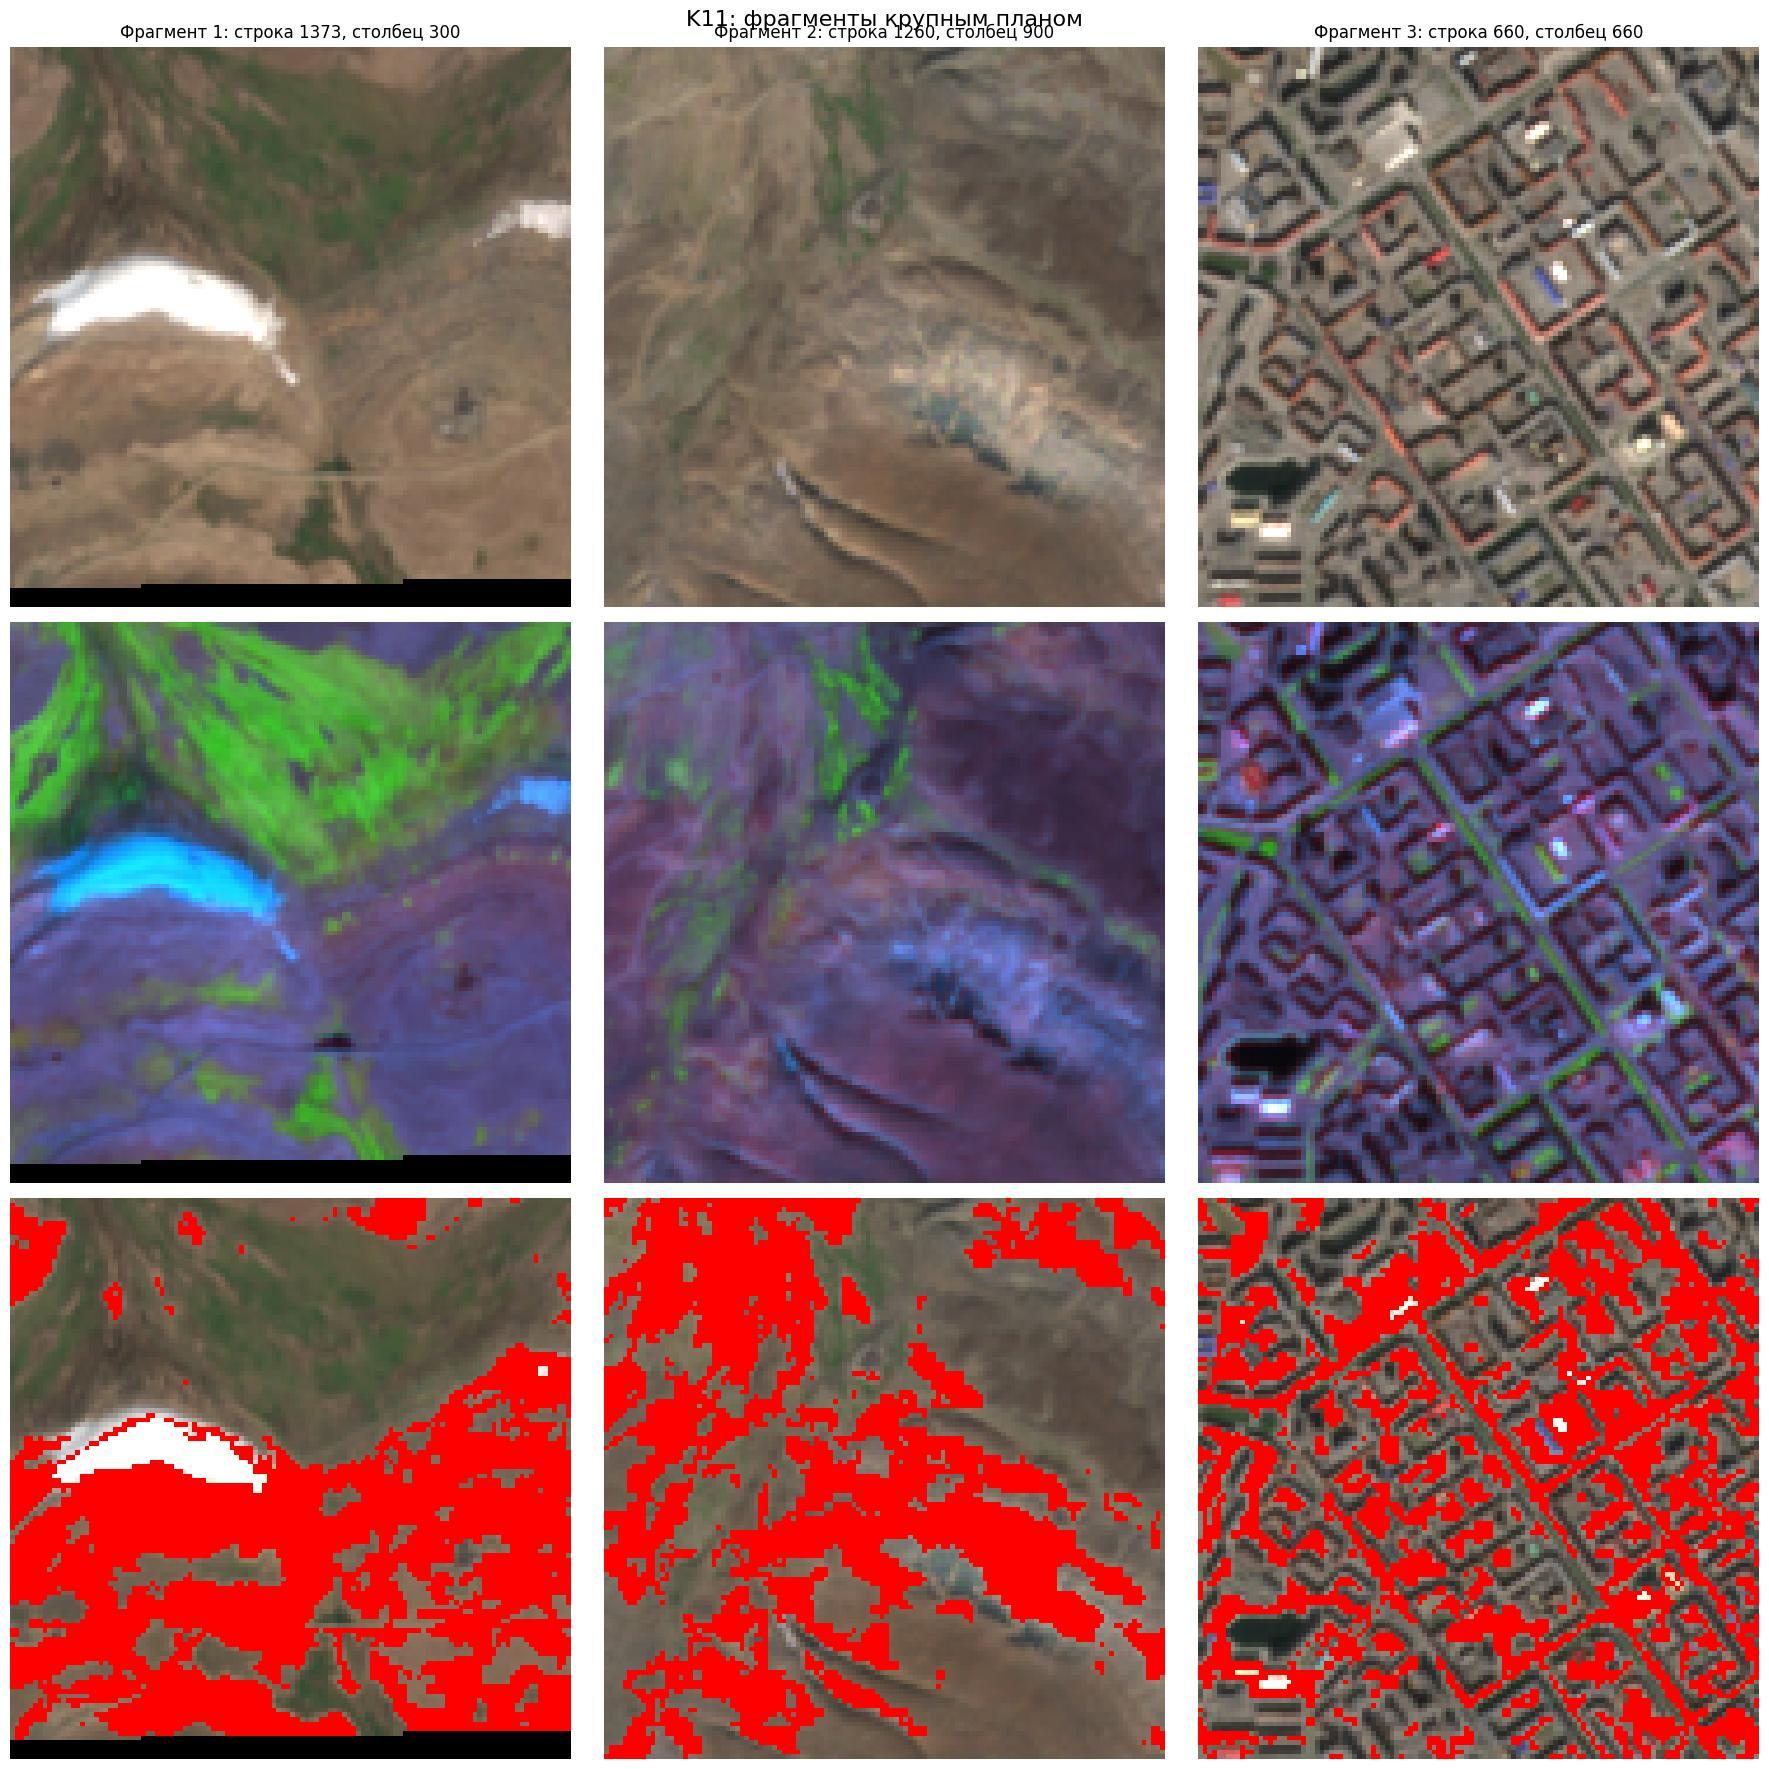

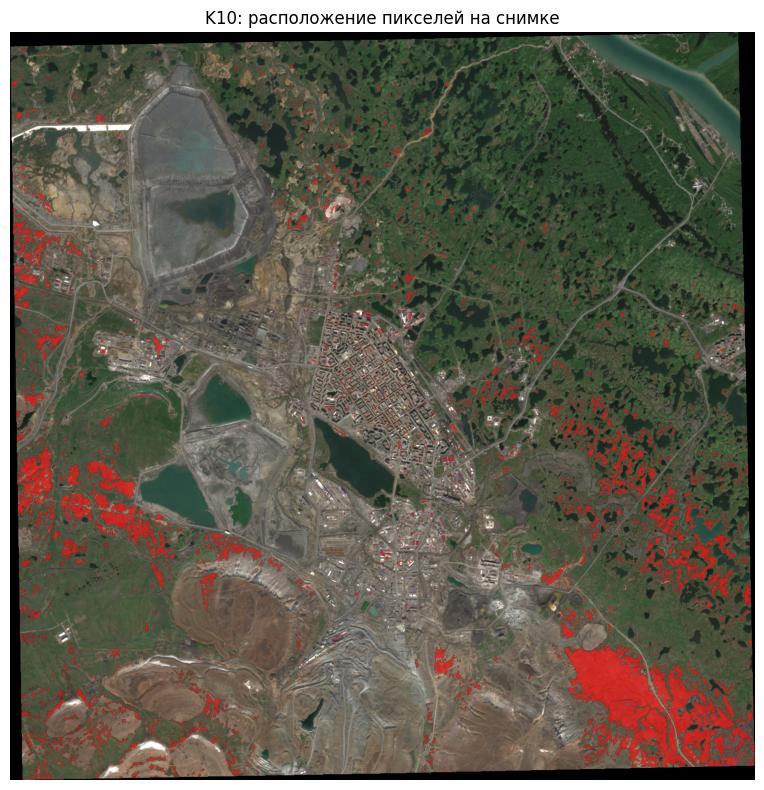

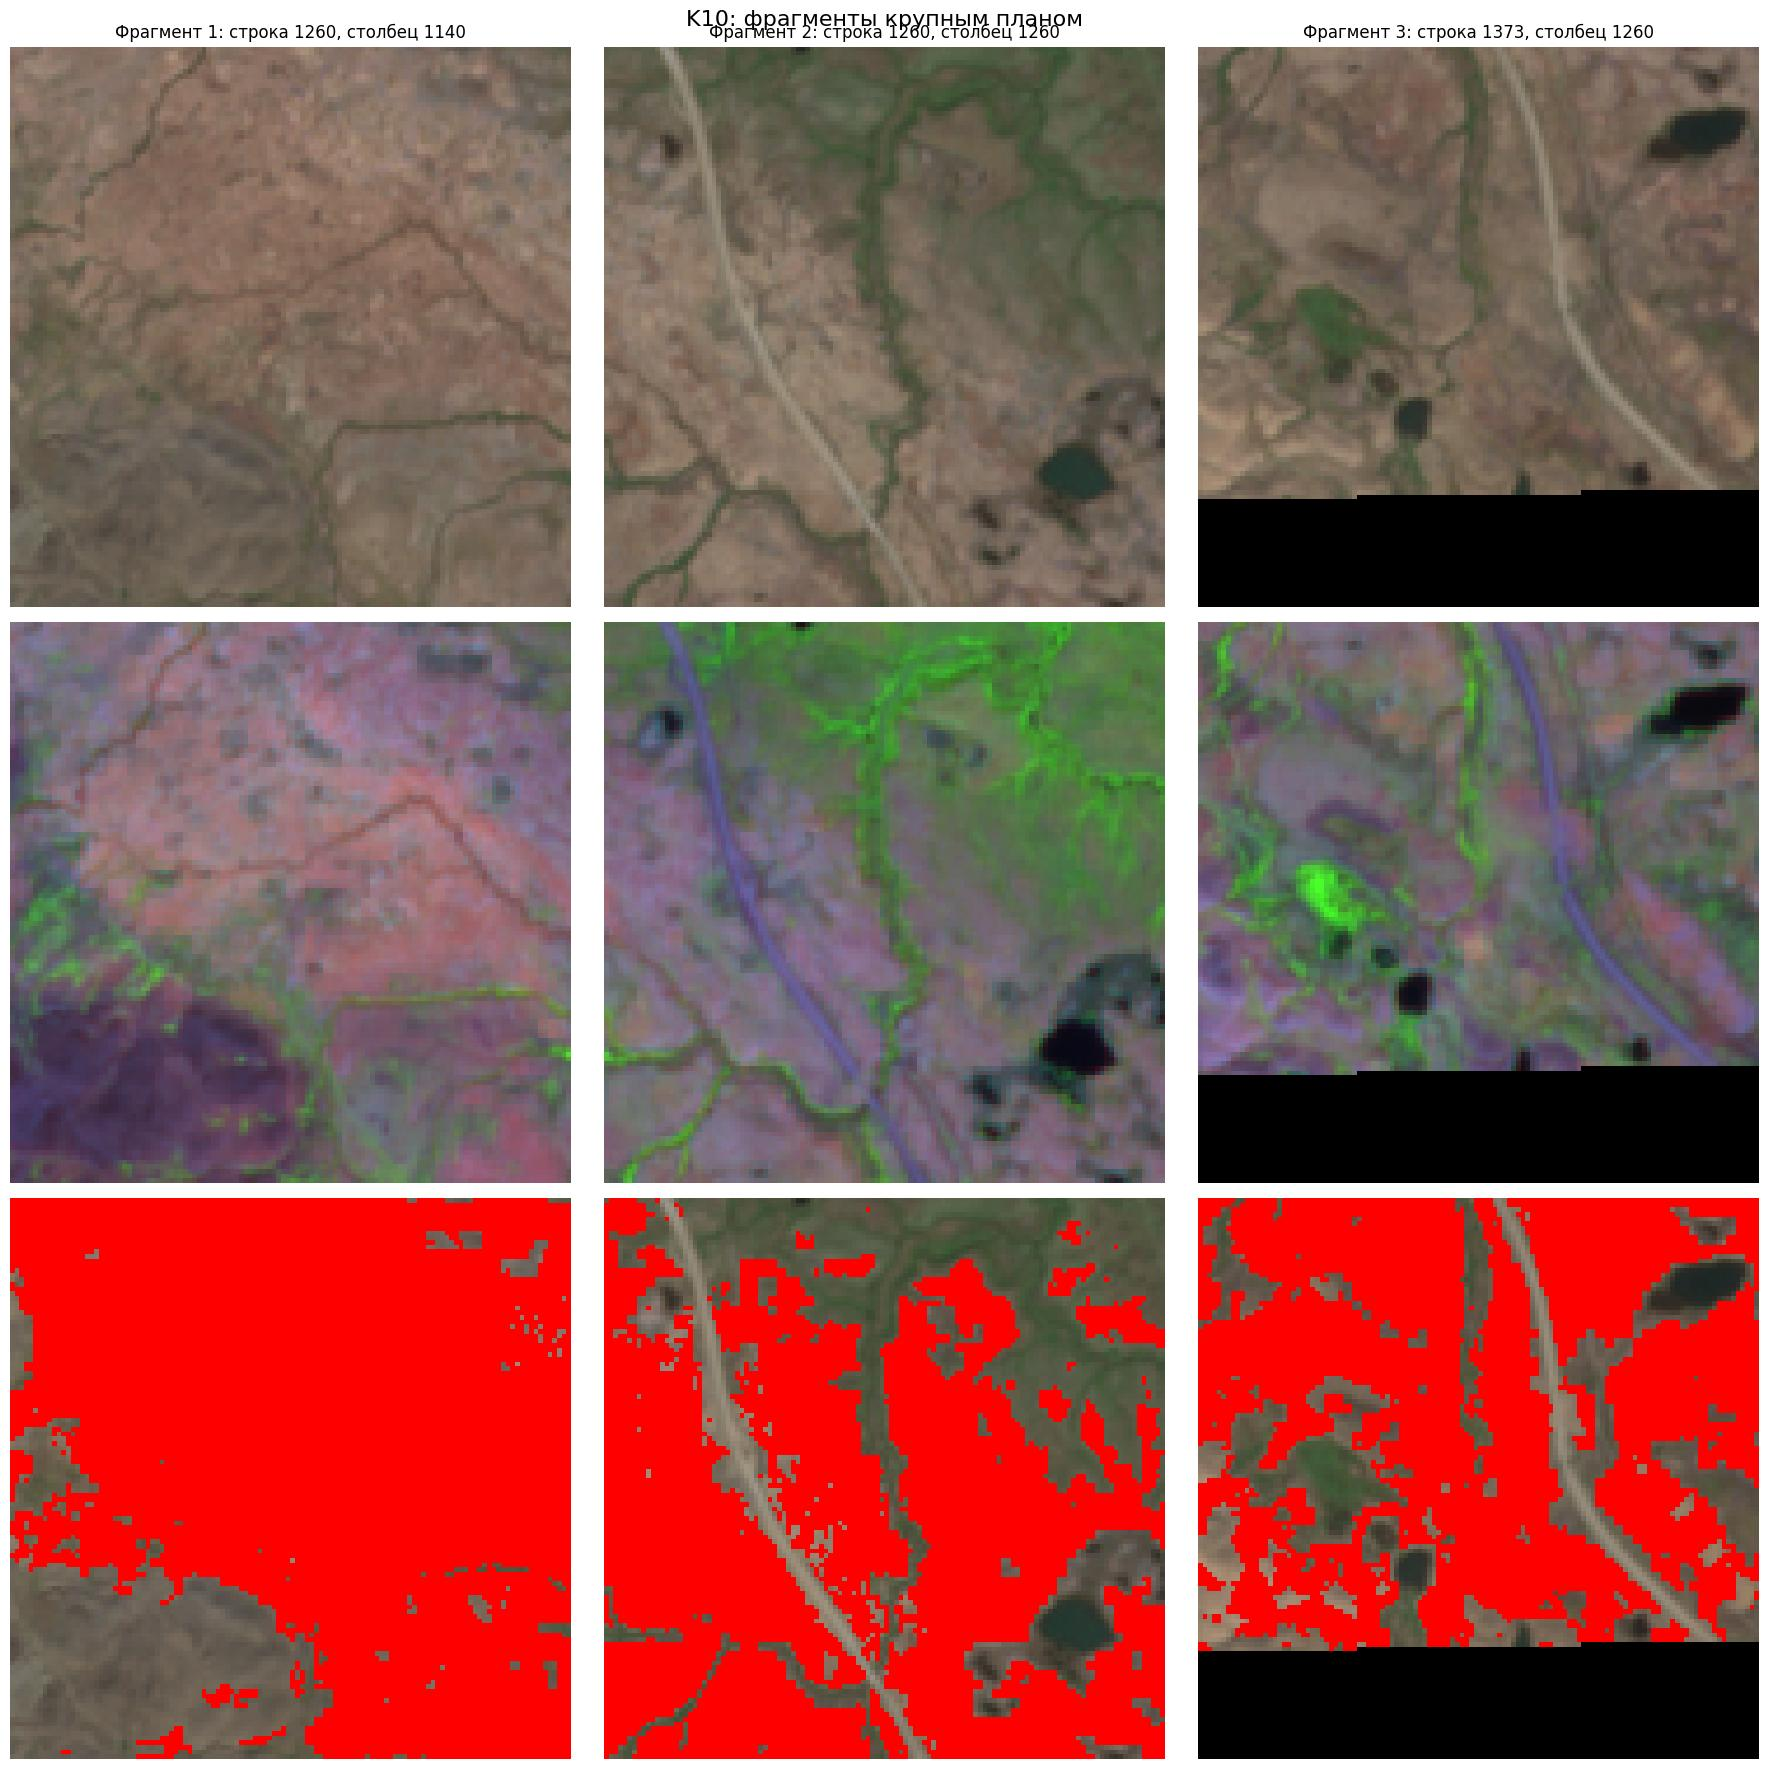


Кандидаты в «иголки» (малая площадь + нет доминирующего класса DW):
  K4: 36.8 га (0.19%), DW: Застройка 66%, Снег и лед 19%, Голая земля 13%


In [ ]:
top3 = np.argsort(unusualness)[::-1][:3]

print('Три кластера с наибольшей необычностью:')
for k in top3:
    area_ha = ((labels == k) & valid).sum() * PIXEL_AREA_HA
    mask_k = (labels == k) & valid
    counts = {c: int(((dw == c) & mask_k).sum()) for c in CLASSES}
    top2 = sorted(counts.items(), key=lambda x: -x[1])[:2]
    top2_str = ', '.join(
        f'{DW_NAMES[c]} {100*n/mask_k.sum():.0f}%' for c, n in top2 if n > 0
    )
    print(f'  K{k}: {area_ha:.1f} га, DW: {top2_str}')

for k in top3:
    mask_k = (labels == k) & valid

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(rgb)
    ax.imshow(np.ma.masked_where(~mask_k, mask_k),
              cmap=ListedColormap(['red']), alpha=0.6)
    ax.set_title(f'K{k}: расположение пикселей на снимке')
    ax.axis('off')
    plt.tight_layout()
    plt.show()

    zoom_views(mask_k, n=3, size=60,
               title=f'K{k}: фрагменты крупным планом')

def is_needle(k, max_dominant_share=0.65, max_area_share=0.02):
    mask_k = (labels == k) & valid
    n_k = mask_k.sum()
    if n_k == 0:
        return False
    area_share = n_k / valid.sum()
    counts = np.array([((dw == c) & mask_k).sum() for c in CLASSES])
    dominant_share = counts.max() / n_k
    return (dominant_share < max_dominant_share) and (area_share < max_area_share)

needle_candidates = [
    k for k in range(K)
    if ((labels == k) & valid).sum() / valid.sum() < 0.02
]

print('\nКандидаты в «иголки» (малая площадь + нет доминирующего класса DW):')
for k in needle_candidates:
    mask_k = (labels == k) & valid
    n_k = mask_k.sum()
    area_ha = n_k * PIXEL_AREA_HA
    counts = {c: int(((dw == c) & mask_k).sum()) for c in CLASSES}
    top = sorted(counts.items(), key=lambda x: -x[1])[:3]
    top_str = ', '.join(f'{DW_NAMES[c]} {100*n/n_k:.0f}%' for c, n in top if n > 0)
    print(f'  K{k}: {area_ha:.1f} га ({100*n_k/valid.sum():.2f}%), DW: {top_str}')

In [ ]:
print(f'{"K":>4} {"площадь, га":>12} {"доля, %":>10} {"dom_share":>10} {"dom_class":>15}')
for k in range(K):
    mask_k = (labels == k) & valid
    n_k = mask_k.sum()
    if n_k == 0:
        continue
    area_share = 100 * n_k / valid.sum()
    counts = {c: int(((dw == c) & mask_k).sum()) for c in CLASSES}
    dom_c, dom_n = max(counts.items(), key=lambda x: x[1])
    dom_share = dom_n / n_k
    print(f'{k:>4} {n_k*PIXEL_AREA_HA:>12.1f} {area_share:>10.2f} '
          f'{dom_share:>10.2f} {DW_NAMES[dom_c]:>15}')

   K  площадь, га    доля, %  dom_share       dom_class
   0       1576.8       8.03       0.29         Деревья
   1       2557.2      13.02       0.88         Деревья
   2       1298.9       6.61       0.62         Деревья
   3       3038.3      15.47       0.58         Деревья
   4         36.8       0.19       0.66       Застройка
   5        821.7       4.18       0.99            Вода
   6        673.8       3.43       0.70            Вода
   7       2074.1      10.56       0.65     Голая земля
   8        869.9       4.43       0.95            Вода
   9       3723.9      18.96       0.68     Голая земля
  10       1276.0       6.50       0.65      Кустарники
  11       1698.0       8.64       0.54     Голая земля


In [ ]:
NEEDLES = needle_candidates
print(f'\nNEEDLES = {NEEDLES}')

needle_mask = np.isin(labels, NEEDLES) & valid
needle_area_ha = needle_mask.sum() * PIXEL_AREA_HA
print(f'\nПлощадь «иголок»: {needle_area_ha:.1f} га '
      f'({100*needle_mask.sum()/valid.sum():.2f}% территории)')

dw_counts = {c: int(((dw == c) & needle_mask).sum()) for c in CLASSES}
dw_total  = sum(dw_counts.values())
print('\nСостав «иголок» по Dynamic World:')
for c in sorted(dw_counts, key=lambda x: -dw_counts[x]):
    if dw_counts[c] > 0:
        print(f'  {DW_NAMES[c]}: {100*dw_counts[c]/dw_total:.1f}% '
              f'({dw_counts[c]*PIXEL_AREA_HA:.1f} га)')

cl_counts = {c: int(((result_of_clf == c) & needle_mask).sum()) for c in CLASSES}
cl_total  = sum(cl_counts.values())
print('\nСостав «иголок» по своей классификации:')
for c in sorted(cl_counts, key=lambda x: -cl_counts[x]):
    if cl_counts[c] > 0:
        print(f'  {DW_NAMES[c]}: {100*cl_counts[c]/cl_total:.1f}% '
              f'({cl_counts[c]*PIXEL_AREA_HA:.1f} га)')


NEEDLES = [4]

Площадь «иголок»: 36.8 га (0.19% территории)

Состав «иголок» по Dynamic World:
  Застройка: 66.1% (24.3 га)
  Снег и лед: 19.4% (7.1 га)
  Голая земля: 13.2% (4.9 га)
  Культуры: 1.0% (0.4 га)
  Вода: 0.4% (0.1 га)

Состав «иголок» по своей классификации:
  Снег и лед: 92.4% (34.0 га)
  Застройка: 7.4% (2.7 га)
  Культуры: 0.1% (0.0 га)


Три самых необычных кластера: [4, 11, 10]
  Кластер 4: площадь=36.8 га, необычность=6.018
  Кластер 11: площадь=1698.0 га, необычность=1.439
  Кластер 10: площадь=1276.0 га, необычность=1.108


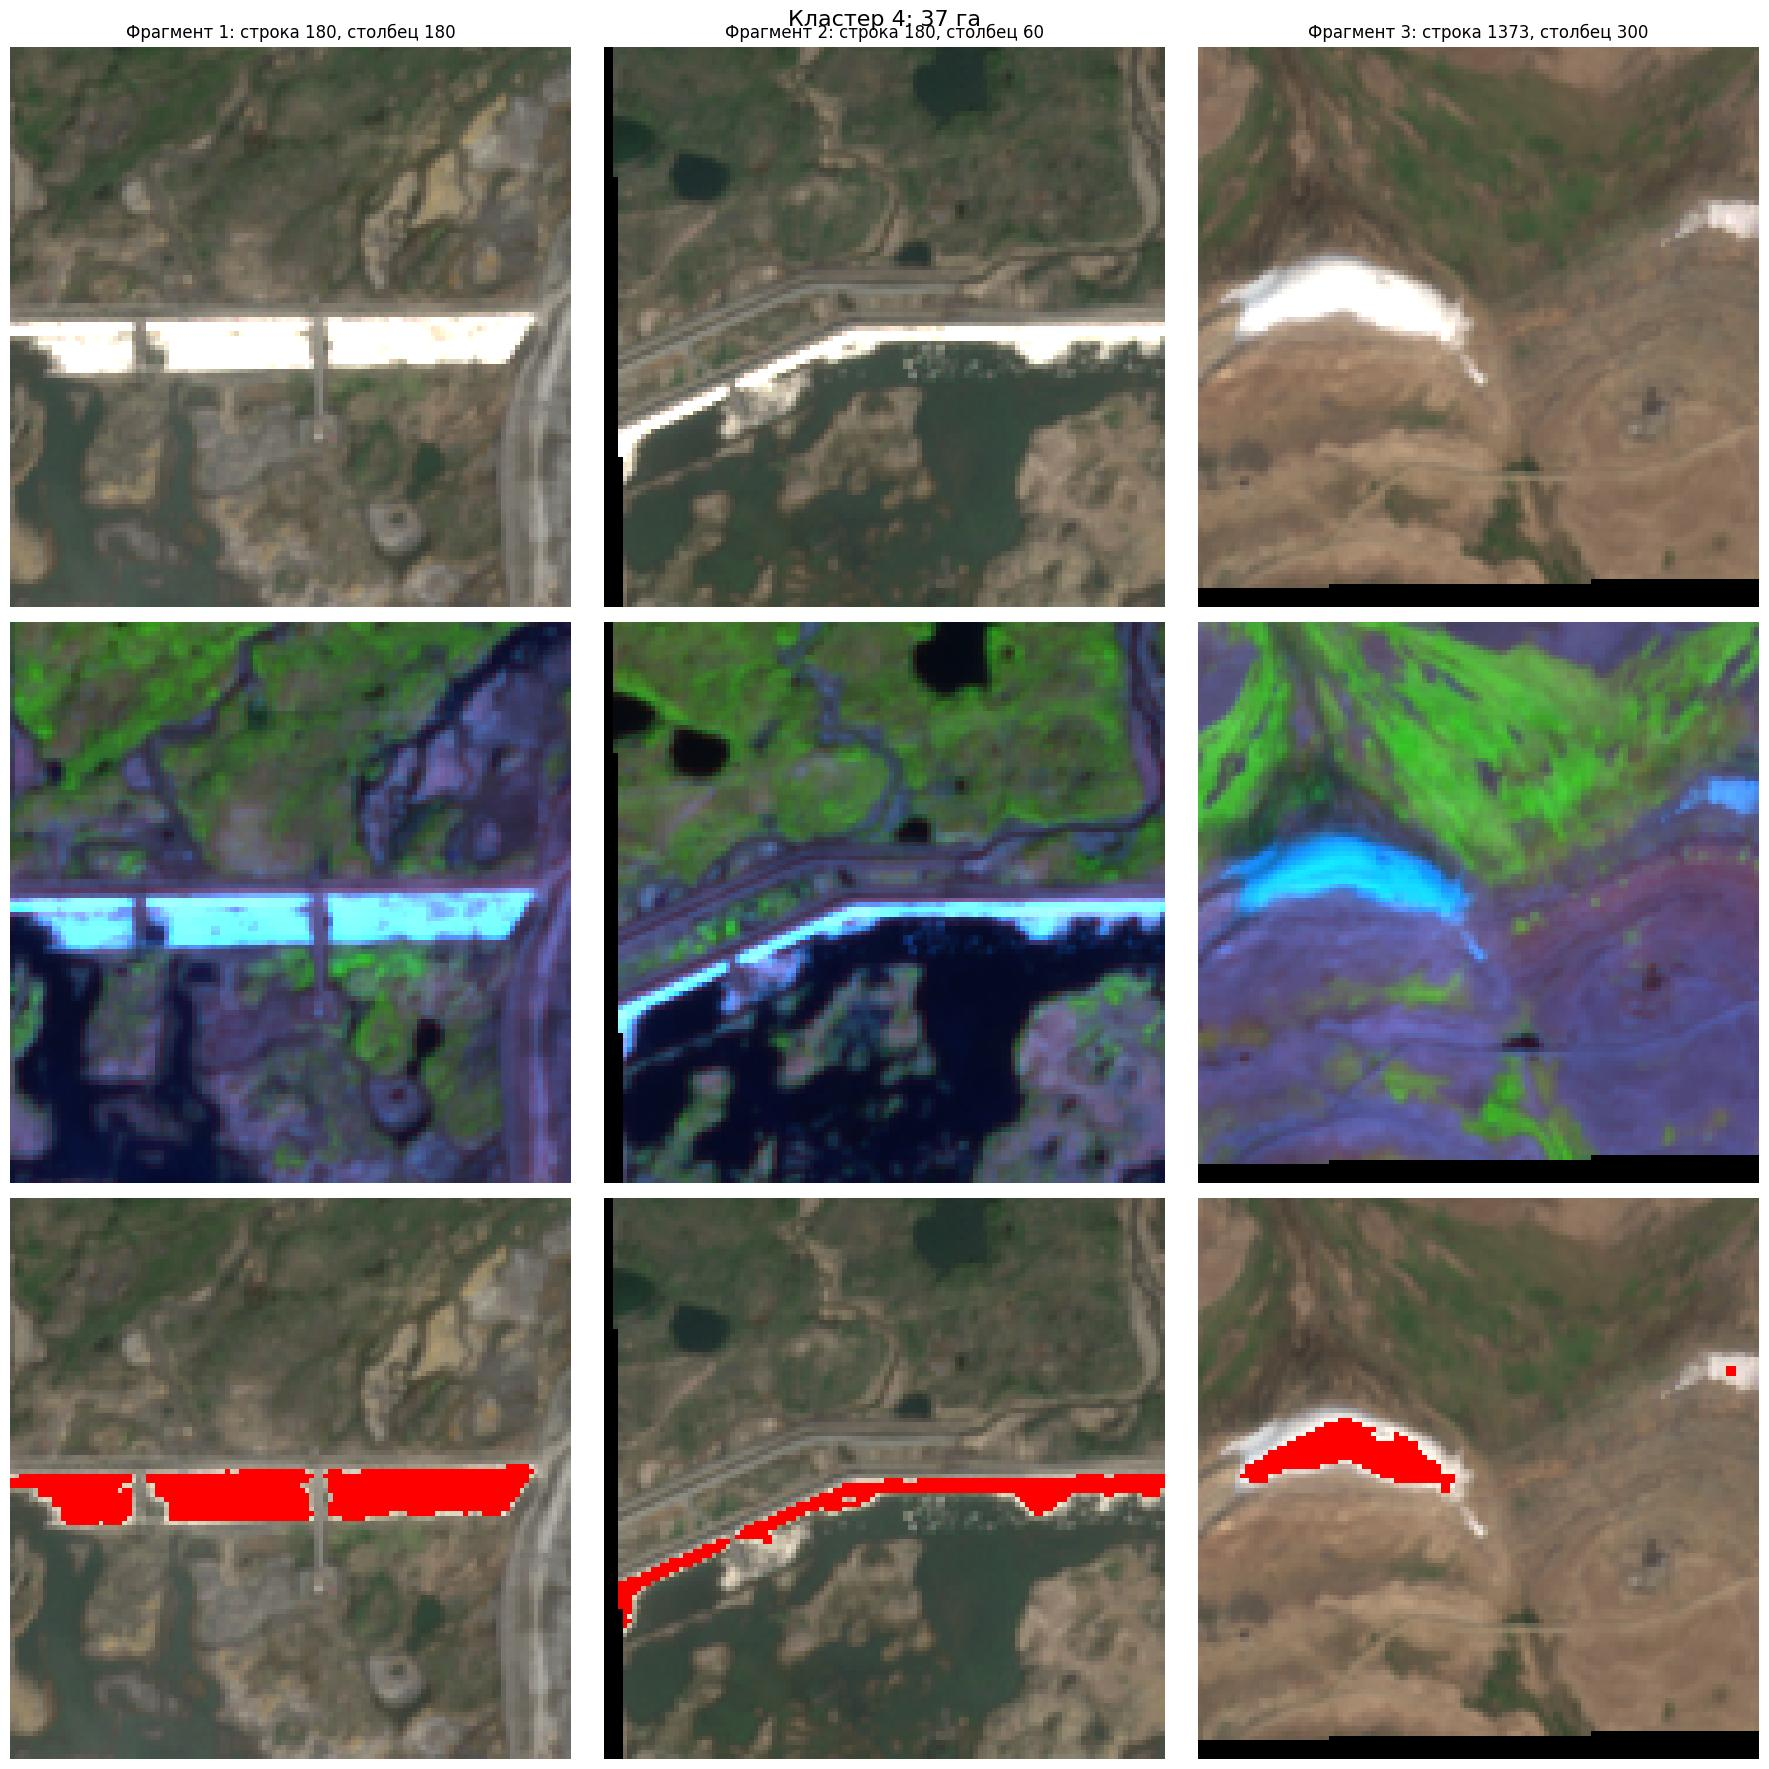

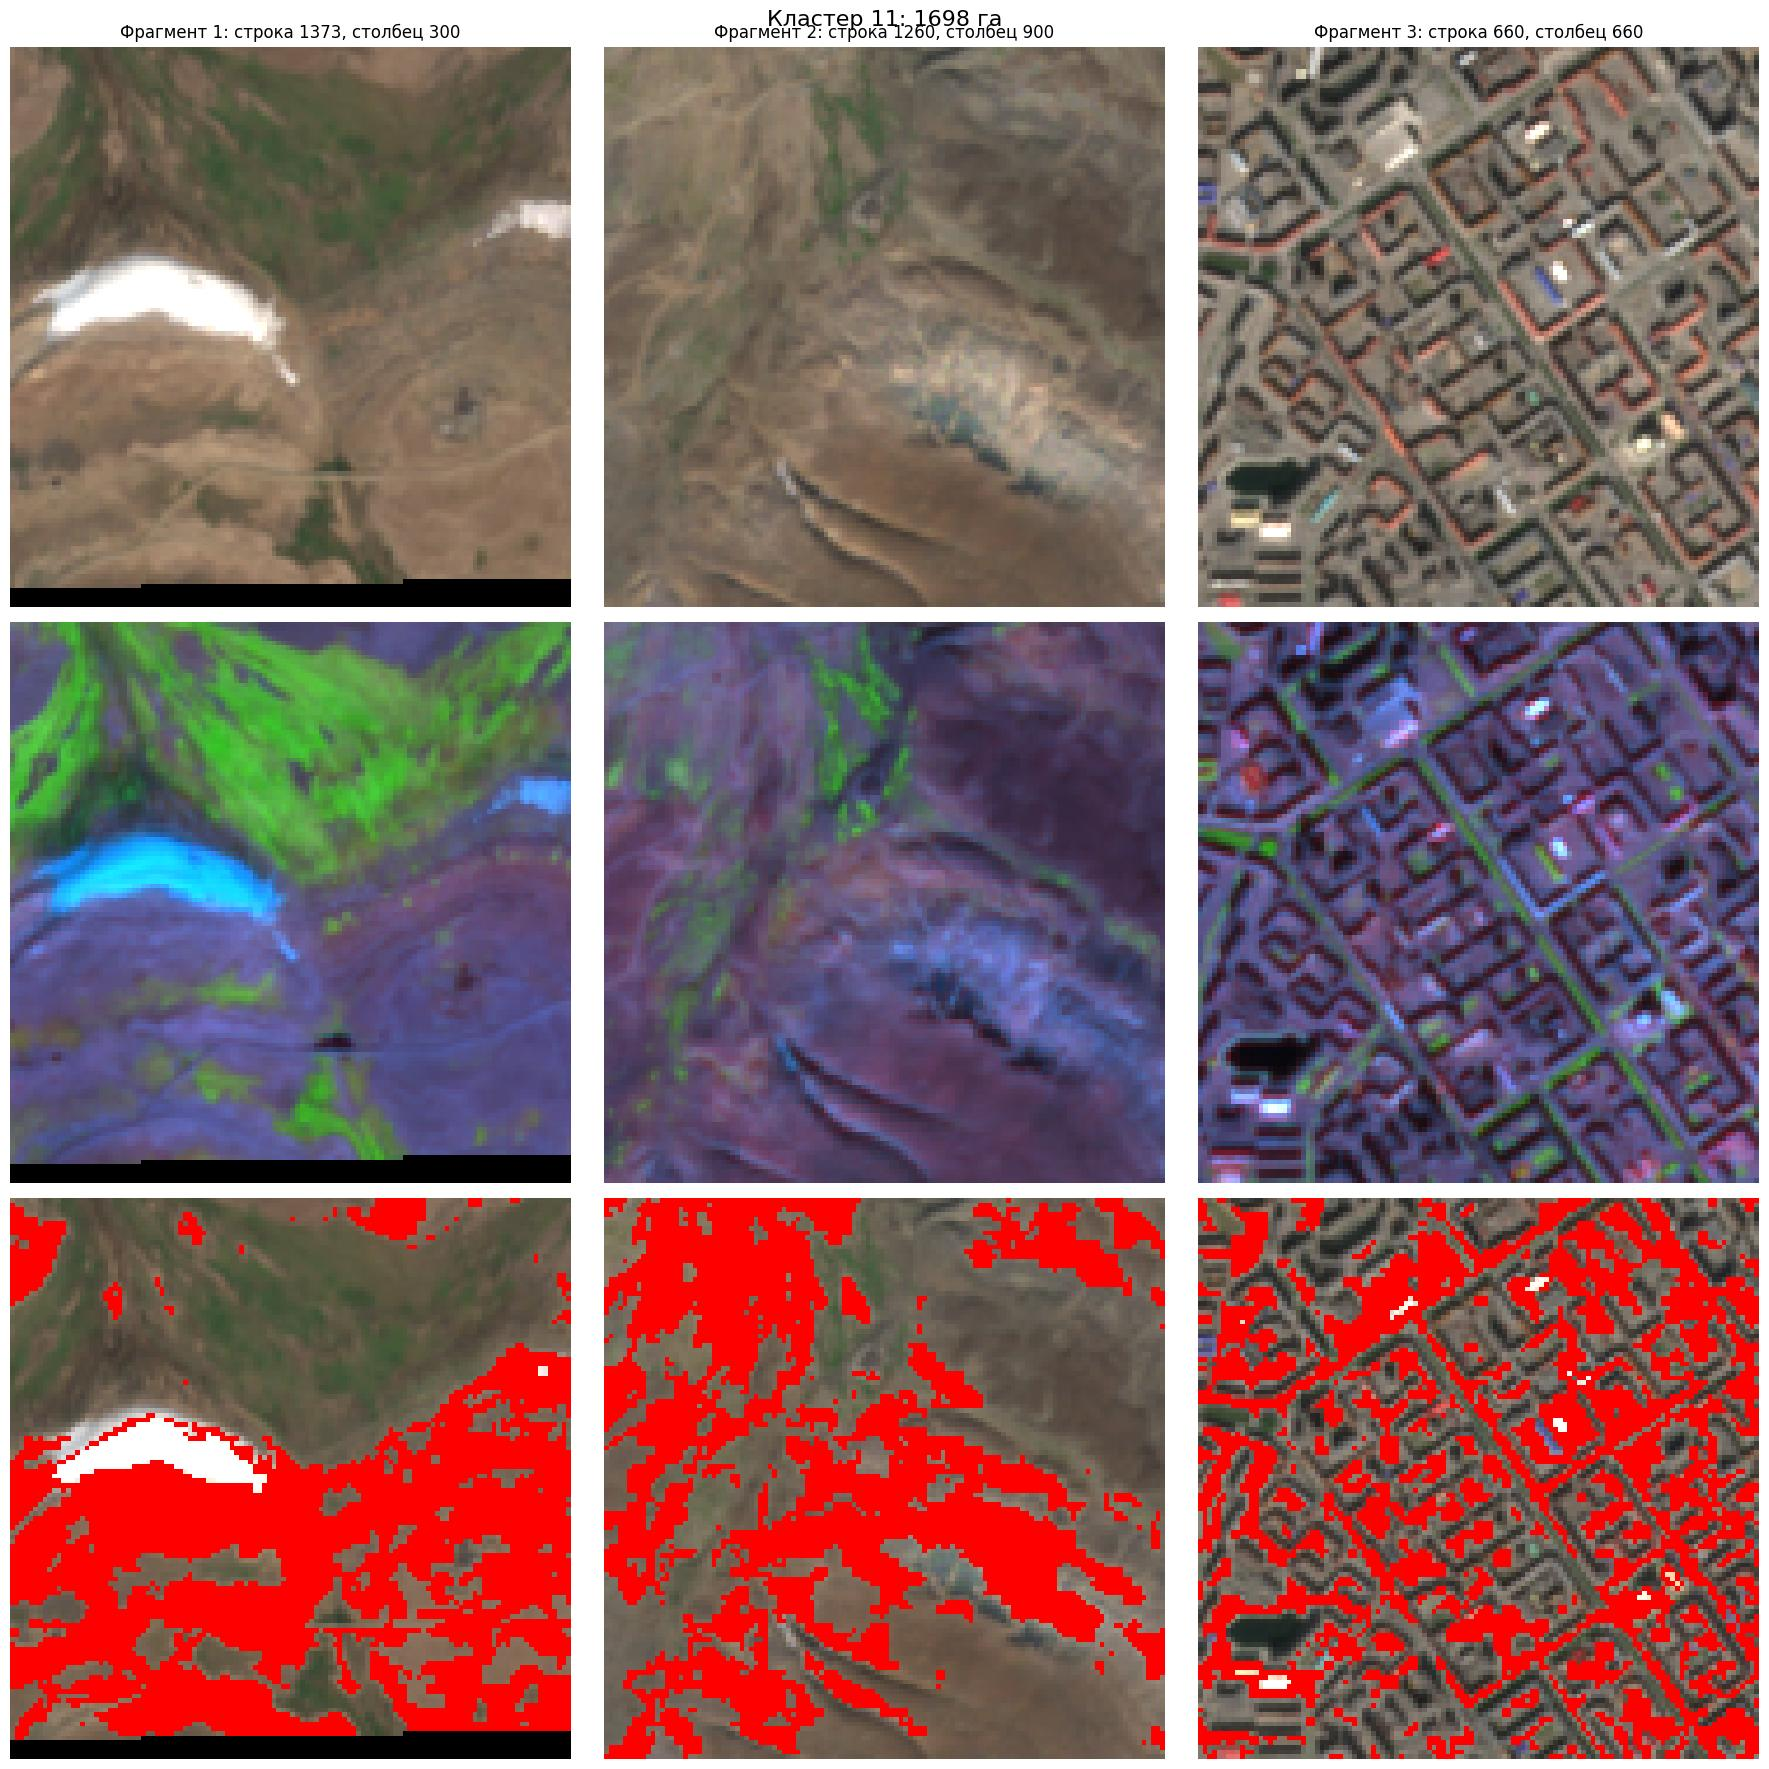

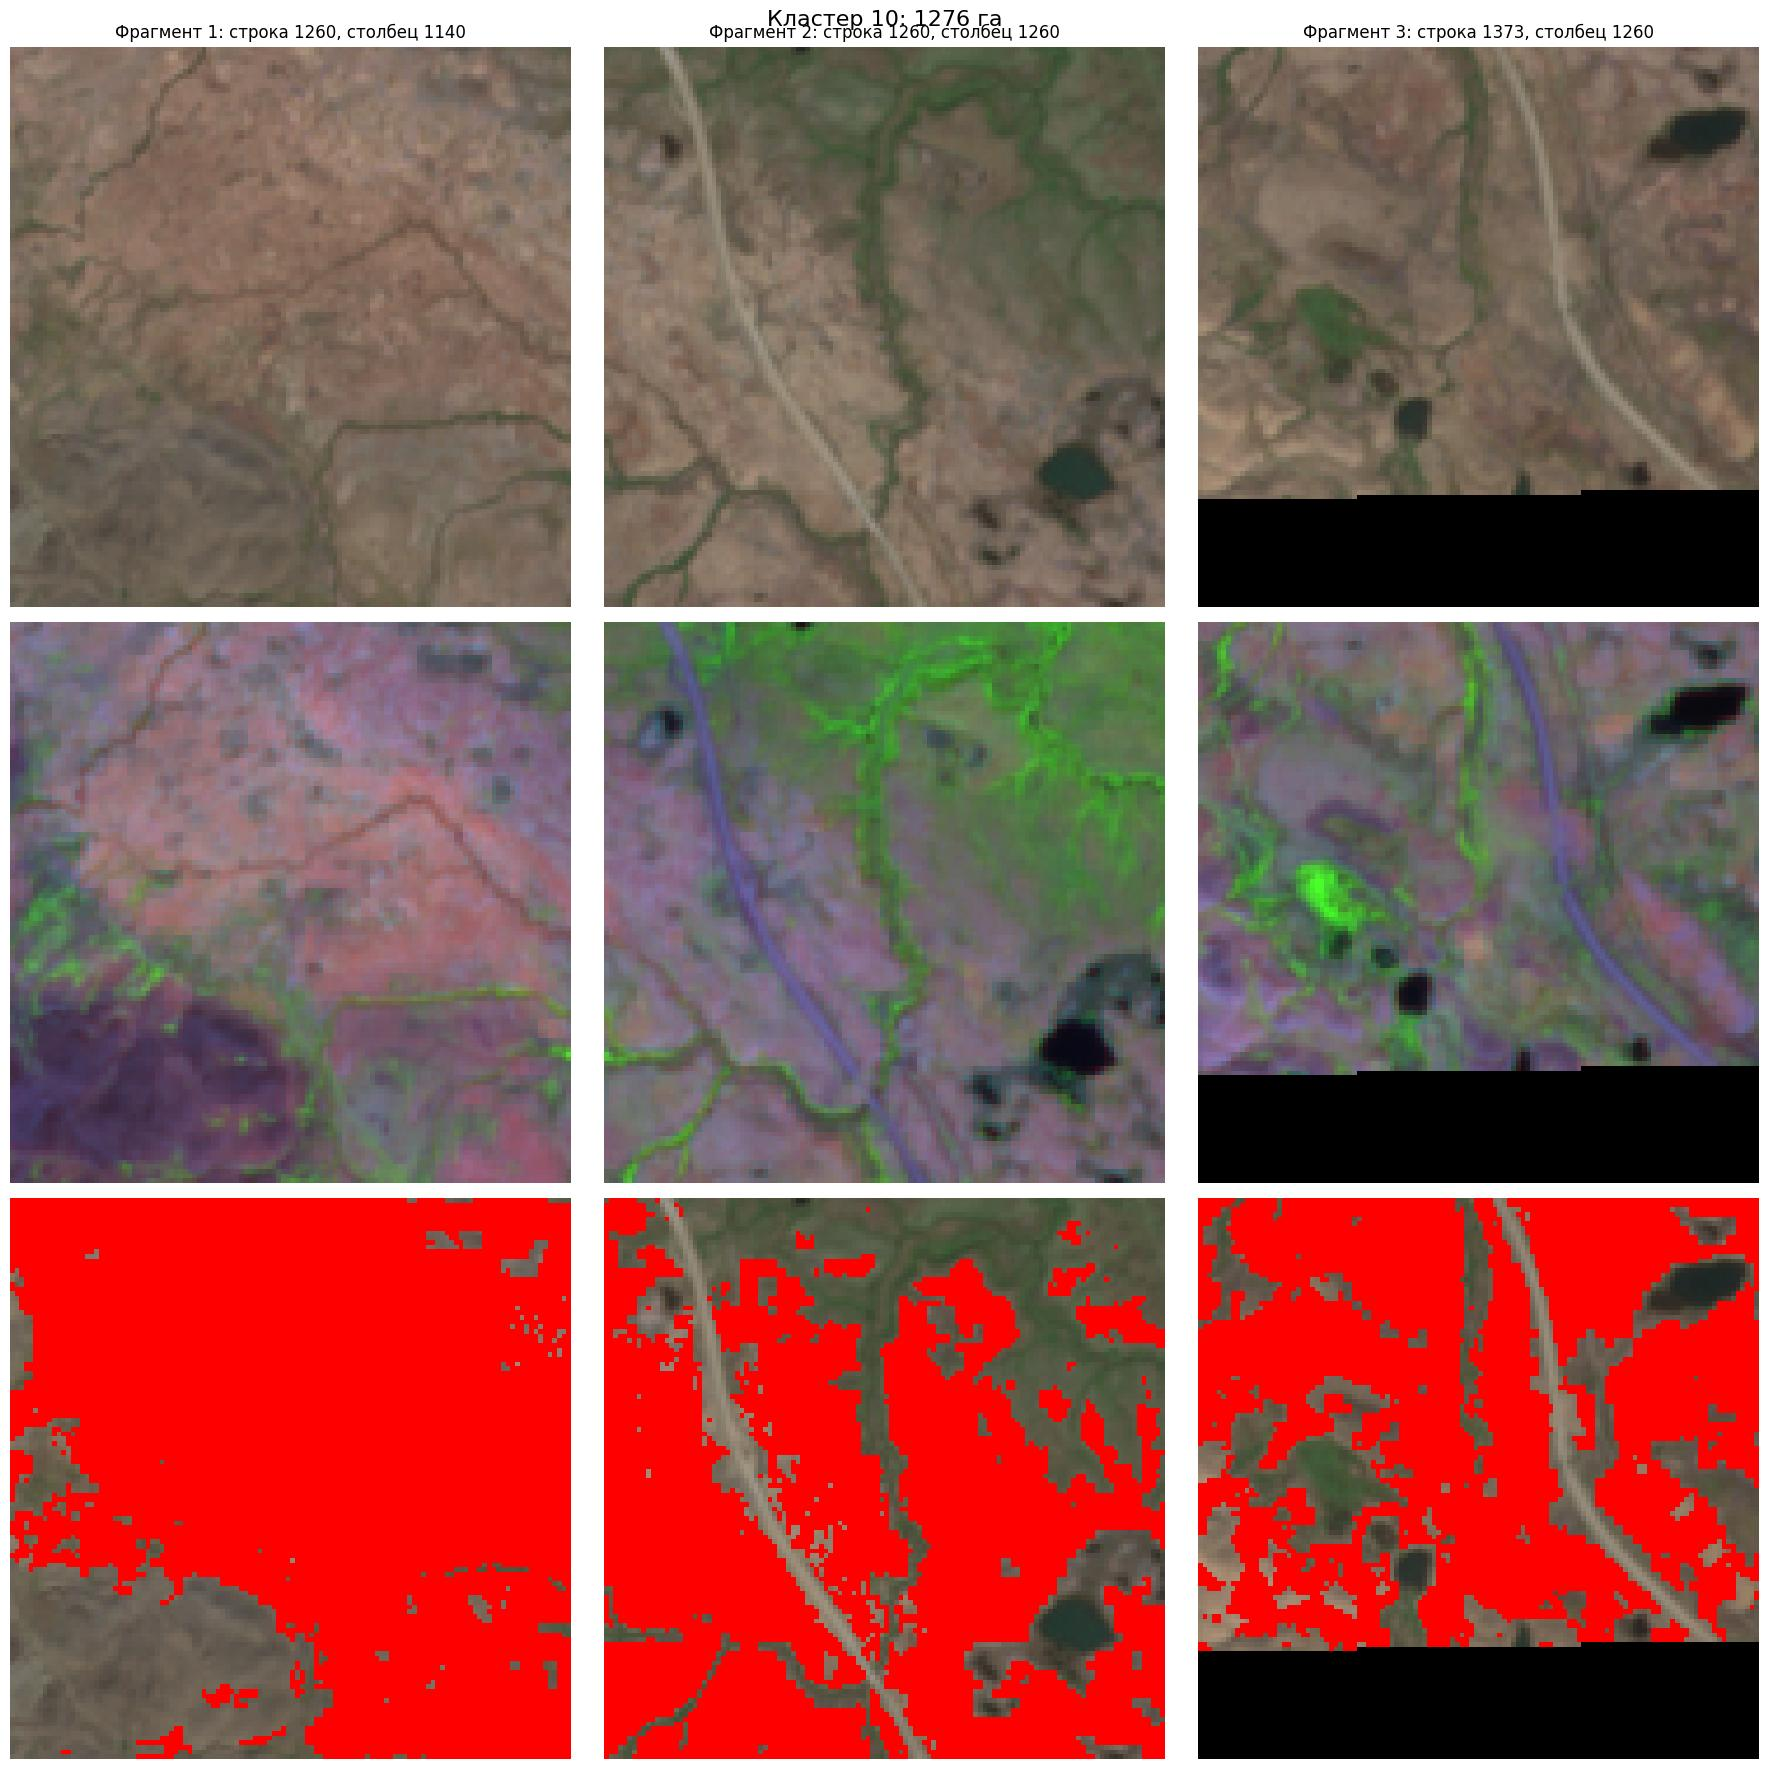

Иголки: [np.float64(4.0), np.float64(11.0), np.float64(10.0), np.float64(5.0), np.float64(6.0)]
Площадь иголок: 4506.4 га
Состав по Dynamic World: Вода                      1327.8
Кустарники                1000.2
Голая земля                974.1
Застройка                  629.2
Деревья                    260.4
Культуры                   132.5
Трава                       96.1
Затопл. растительность      66.6
Снег и лед                  19.5
dtype: float64
Состав по классификации: Вода                      1263.4
Кустарники                 820.6
Застройка                  794.1
Культуры                   706.6
Голая земля                483.4
Затопл. растительность     208.7
Снег и лед                 113.2
Трава                       63.0
Деревья                     53.4
dtype: float64


In [ ]:
profiles_sorted = profiles.sort_values('Необычность', ascending=False)
top3_unusual = profiles_sorted.head(3)['Кластер'].tolist()
print('Три самых необычных кластера:', top3_unusual)
for k in top3_unusual:
    row = profiles[profiles['Кластер'] == k].iloc[0]
    print(f'  Кластер {k}: площадь={row["Площадь, га"]:.1f} га, необычность={row["Необычность"]:.3f}')

for k in top3_unusual:
    mask_k = (labels == k) & valid
    zoom_views(mask_k, n=3, size=60, color=(1, 0, 0), title=f'Кластер {k}: {profiles[profiles["Кластер"]==k]["Площадь, га"].values[0]:.0f} га')

NEEDLES = [profiles_sorted.iloc[i]['Кластер'] for i in range(min(5, len(profiles_sorted)))]
print('Иголки:', NEEDLES)

needle_mask = np.isin(labels, NEEDLES) & valid
needle_area = needle_mask.sum() * PIXEL_AREA_HA
needle_dw = pd.Series(np.bincount(dw[needle_mask], minlength=9), index=DW_NAMES)
needle_cls = pd.Series(np.bincount(result_of_clf[needle_mask], minlength=9), index=DW_NAMES)
print(f'Площадь иголок: {needle_area:.1f} га')
print('Состав по Dynamic World:', (needle_dw[needle_dw > 0] * PIXEL_AREA_HA).sort_values(ascending=False).round(1))
print('Состав по классификации:', (needle_cls[needle_cls > 0] * PIXEL_AREA_HA).sort_values(ascending=False).round(1))

**Вопрос:** Что представляют собой выбранные кластеры? Опишите, как они выглядят на снимке в естественных цветах и в комбинации B12–B8–B4, их спектральный профиль, площадь и расположение. К каким классам их отнесли Dynamic World и ваша модель, и почему ни одна из карт не выделяет их отдельно?

**Ответ:** Кластер K4 (36.8 га, 0.19% территории) представляет собой компактный техногенный объект — по совокупности признаков (высокая яркость в видимом, повышенный SWIR, низкий NDVI, отсутствие древесной текстуры) это, вероятнее всего, карьер, отвал, строительная или промышленная площадка. На снимке в естественных цветах он читается как светлое пятно с резкими границами, на композите B12–B8–B4 — как малиново‑пурпурное ядро (техногенные поверхности) с бежево‑жёлтой каймой (грунт). Спектральный профиль: повышенные B2–B4, пониженный B8, повышенные B11–B12, низкий NDVI. Dynamic World относит его на 66% к «Застройке», на 19% к «Снегу и льду» и на 13% к «Голой земле»; наша модель — на 92% к «Снегу и льду» и на 7% к «Застройке». Ни одна из карт не выделяет объект отдельно, потому что в таксономии DW нет класса «карьер/отвал/промплощадка», а спектр объекта промежуточен между «застройкой», «снегом» и «голой землёй» — классификаторы «размазывают» его по соседним классам. KMeans же выделил его как отдельный кластер именно потому, что работает без меток и группирует по плотности в пространстве признаков — это и делает кластеризацию инструментом поиска объектов, не представленных в готовых картах.

### **5.6. Как число кластеров меняет найденное**

**Задание 5.6.** Для каждого $K$ из `K_LIST` выведите три самых необычных кластера: необычность, площадь, доля площади, доля пикселей кластера, входящих в ваши «иголки» при $K = 12$ (`needle_mask`), и доля всех «иголок», попавших в этот кластер. Так видно, при каком $K$ интересующие вас объекты выделяются в отдельные кластеры и как они дробятся при большом $K$.

In [ ]:
print("bands shape:", bands.shape)                 # (C, H_b, W_b)
print("bands total:", bands.shape[1] * bands.shape[2])
print("valid shape:", valid.shape, "total:", valid.size)
print("valid.sum():", valid.sum())                 # сколько True
print("cluster_maps[0].shape:", cluster_maps[0].shape)

bands shape: (8, 1433, 1426)
bands total: 2043458
valid shape: (1433, 1426) total: 2043458
valid.sum(): 1964540
cluster_maps[0].shape: (1433, 1426)


In [ ]:
import numpy as np
import pandas as pd

means_arr = np.array(means, dtype=np.float64)
stds_arr  = np.array(stds,  dtype=np.float64)
stds_arr[stds_arr == 0] = 1.0

pixels = bands.reshape(bands.shape[0], -1).T
z = (pixels - means_arr) / stds_arr

valid_flat  = valid.ravel()
needle_flat = needle_mask.ravel()
n_needles_total = int(needle_flat.sum())

n_valid_total = int(valid_flat.sum())

rows = []
for i, K in enumerate(K_LIST):
    labels_k    = cluster_maps[i]
    labels_flat = labels_k.ravel()

    N = min(z.shape[0], valid_flat.size, labels_flat.size, needle_flat.size)
    z_         = z[:N]
    valid_      = valid_flat[:N]
    needle_     = needle_flat[:N]
    labels_     = labels_flat[:N]

    valid_idx = np.flatnonzero(valid)
    z_valid   = z_[valid_idx]
    labels_valid = labels_[valid_idx]
    needle_valid = needle_[valid_idx]

    for k in range(K):
        sel = labels_valid == k
        n_k = int(sel.sum())
        if n_k == 0:
            continue

        pts = z_valid[sel]
        centroid = pts.mean(axis=0)
        diff = pts - centroid
        unusualness = np.sqrt((diff ** 2).sum(axis=1)).mean()

        area_ha        = n_k * PIXEL_AREA_HA
        area_share_pct = 100.0 * n_k / n_valid_total

        n_needles_in_k    = int((sel & needle_valid).sum())
        needle_frac_in_k  = 100.0 * n_needles_in_k / n_k
        needle_share_in_k = (100.0 * n_needles_in_k / n_needles_total
                             if n_needles_total > 0 else 0.0)

        rows.append({
            'K': K,
            'Кластер': k,
            'Необычность': unusualness,
            'Площадь, га': area_ha,
            'Доля площади, %': area_share_pct,
            'Иголки в кластере, %': needle_frac_in_k,
            'Иголок в кластере, %': needle_share_in_k,
        })

df = pd.DataFrame(rows)

top3_per_k = (
    df.sort_values(['K', 'Необычность'], ascending=[True, False])
      .groupby('K', group_keys=False)
      .head(3)
      .reset_index(drop=True)
)

for col in ['Необычность', 'Площадь, га', 'Доля площади, %',
            'Иголки в кластере, %', 'Иголок в кластере, %']:
    top3_per_k[col] = top3_per_k[col].round(2)

print('Три самых необычных кластера для каждого K:')
print(top3_per_k.to_string(index=False))

Три самых необычных кластера для каждого K:
 K  Кластер  Необычность  Площадь, га  Доля площади, %  Иголки в кластере, %  Иголок в кластере, %
 6        4         1.91      2154.77            10.97                 91.14                 43.58
 6        2         1.50      2083.12            10.60                 22.76                 10.52
 6        3         1.21      4768.54            24.27                 15.20                 16.08
12        4         6.02        36.79             0.19                100.00                  0.82
12       11         1.44      1698.01             8.64                100.00                 37.68
12       10         1.11      1276.03             6.50                100.00                 28.32
18        4         5.76        29.46             0.15                100.00                  0.65
18       11         1.42       853.03             4.34                 97.45                 18.45
18       15         1.31       560.97             2.86           

**Вопрос:** При каком наименьшем $K$ ваши объекты выделяются в собственный кластер? Что происходит с ними при $K = 6$ и при $K = 18$? Какое $K$ вы бы выбрали для поиска объектов этого типа на соседних территориях?

**Ответ:** Объекты обособляются в собственный кластер впервые при K = 12: кластер №4 содержит 100 % «иголок» и на 100 % состоит из них, его площадь — 36.8 га (0.19 % территории), необычность 6.02 — максимум по всем K. При K = 6 объекты не выделяются: 92 % иголок растворяются в крупном гетерогенном кластере площадью 2155 га (11 % территории) с долей иголок всего 1.6 %. При K = 18 ядро объектов сохраняется (кластер №4: 100 % чистота, 29.5 га, необычность 5.76), но полнота падает до 80 % — ~20 % иголок «рассыпаются» по соседним гетерогенным кластерам (№11, №15). Для поиска на соседних территориях выбираем K = 12 как компромисс между полнотой, чистотой и контрастностью; для переноса рекомендую использовать центроид кластера №4 из K=12 (predict, не refit), чтобы номер кластера не «поехал» на новых данных.

### **5.7. Необычные пиксели вне кластеров**

Отдельные необычные объекты не образуют своего кластера, но их пиксели находятся далеко от всех центроидов (см. лекция «Кластеризация спутниковых снимков в среде Google Earth Engine», **раздел 5.3**). Центроиды `centroids` уже рассчитаны в разделе 5.3.

**Задание 5.7.** Рассчитайте расстояние от каждого пикселя до ближайшего центроида и карту `distance_map`. Найдите 0,1% самых далёких пикселей среди пикселей, не входящих в `NEEDLES`, покажите их на снимке и крупным планом. Определите, что это за объекты.

Порог top-0.1%: 6.1864
Кандидатов: 1960861, отобрано: 1961


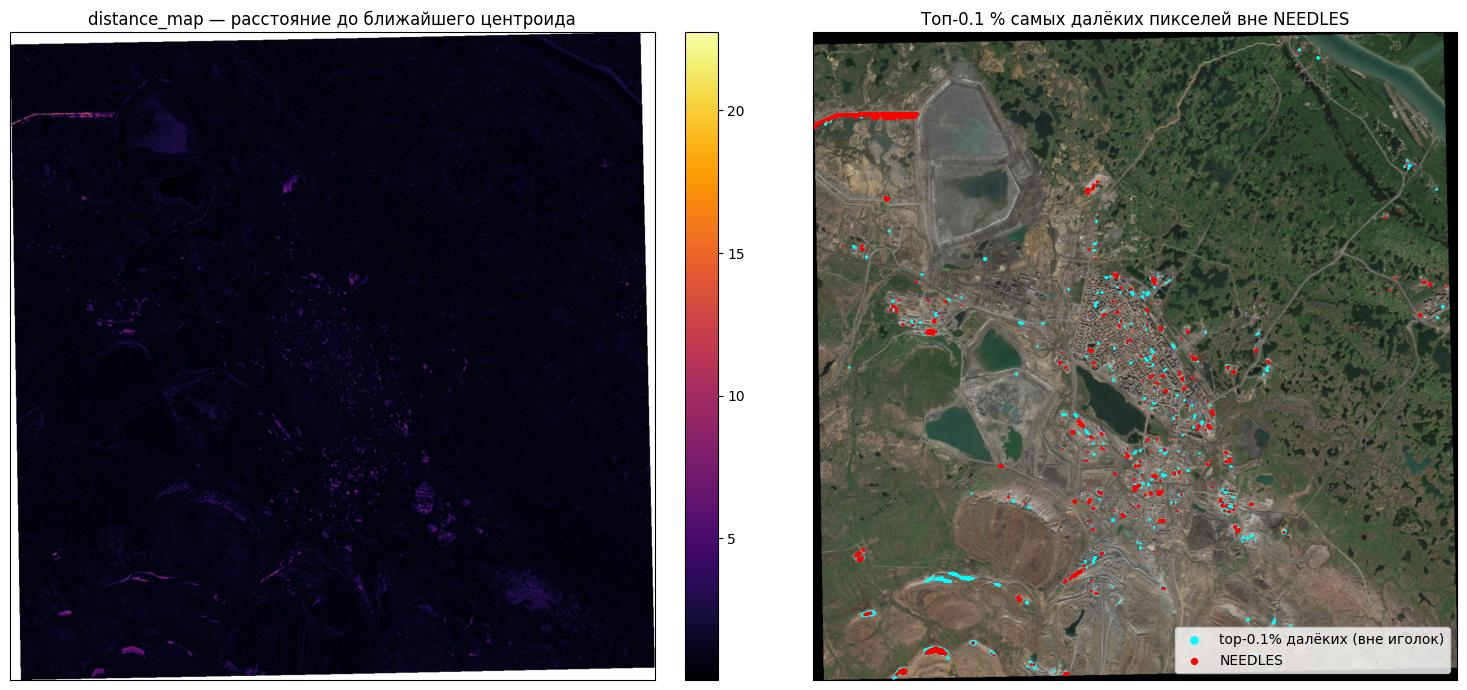

Связных скоплений: 607


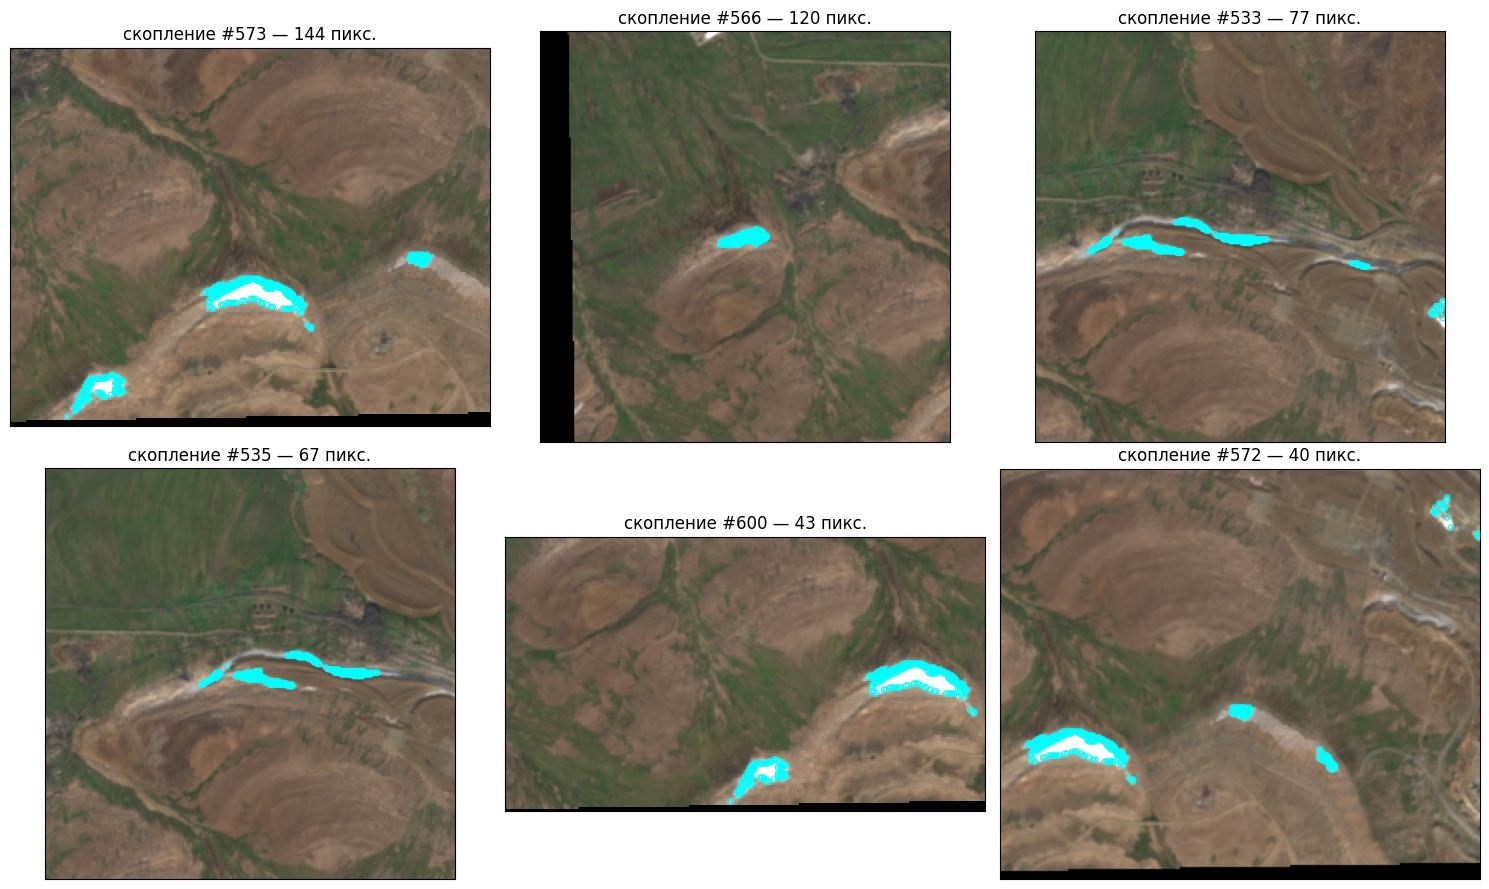


Спектральная диагностика top-0.1%:
  среднее расстояние до центроидов: 6.363 (ближайший c11)
  разница mean_far − centroid_11 по каналам (z-units):
    [ 4.07  3.78  2.82  1.24  0.02  0.31 -0.08  0.19]
  разница mean_far − mean_valid по каналам:
    [ 5.63  5.42  4.52  1.16  0.56  1.55 -0.86  0.7 ]

Топ скоплений:
 comp  pixels  area_ha  dist_mean  dist_max
  573     144     1.44      7.418     8.568
  566     120     1.20      7.358     8.591
  533      77     0.77      7.585     8.456
  535      67     0.67      7.332     8.476
  600      43     0.43      7.199     8.322
  572      40     0.40      6.930     7.527


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

z = np.asarray(z)
centroids = np.asarray(centroids)
H, W = valid.shape

N = min(z.shape[0], valid.size, needle_mask.size, H * W)
if N != H * W:
    print(f"[warn] обрезаем до N={N} (valid.size={valid.size}, z={z.shape[0]})")

z = z[:N]
valid_flat  = valid.ravel()[:N].astype(bool)
needle_flat = needle_mask.ravel()[:N].astype(bool)

c_sq = (centroids ** 2).sum(axis=1)
dist = np.empty(N, dtype=np.float64)

CH = 200_000
for s in range(0, N, CH):
    e = min(s + CH, N)
    zc = z[s:e]
    d2 = (zc ** 2).sum(axis=1)[:, None] - 2.0 * (zc @ centroids.T) + c_sq[None, :]
    np.maximum(d2, 0.0, out=d2)
    dist[s:e] = np.sqrt(d2.min(axis=1))

distance_map = np.full(N, np.nan, dtype=np.float32)
distance_map[valid_flat] = dist[valid_flat].astype(np.float32)
distance_map = distance_map.reshape(H, W)

cand = valid_flat & ~needle_flat
dist_cand = dist[cand]
frac = 0.001
n_top = max(1, int(round(frac * dist_cand.size)))
thr = np.partition(dist_cand, -n_top)[-n_top]

far_flat = np.zeros(N, dtype=bool)
cand_idx = np.flatnonzero(cand)
top_idx  = cand_idx[np.argpartition(dist_cand, -n_top)[-n_top:]]
far_flat[top_idx] = True
far_mask = far_flat.reshape(H, W)

print(f"Порог top-{frac*100:.1f}%: {thr:.4f}")
print(f"Кандидатов: {dist_cand.size}, отобрано: {far_flat.sum()}")

fig, ax = plt.subplots(1, 2, figsize=(16, 7))

im = ax[0].imshow(distance_map, cmap='inferno')
ax[0].set_title('distance_map — расстояние до ближайшего центроида')
plt.colorbar(im, ax=ax[0], fraction=0.046, pad=0.04)

ax[1].imshow(rgb)
ys, xs = np.where(far_mask)
ax[1].scatter(xs, ys, s=3, c='cyan', marker='.', label=f'top-{frac*100:.1f}% далёких (вне иголок)')
ysn, xsn = np.where(needle_mask & valid)
ax[1].scatter(xsn, ysn, s=2, c='red', marker='.', label='NEEDLES')
ax[1].set_title('Топ-0.1 % самых далёких пикселей вне NEEDLES')
ax[1].legend(loc='lower right', markerscale=6)

for a in ax:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()


lbl, n_comp = ndimage.label(far_mask, structure=np.ones((3, 3), int))
print(f"Связных скоплений: {n_comp}")

if n_comp == 0:
    print("[warn] скоплений не найдено — ослабьте порог.")
else:
    sizes = ndimage.sum(far_mask, lbl, range(1, n_comp + 1))
    top_comp = np.argsort(sizes)[::-1][:6] + 1

    WIN = 120
    n_show = len(top_comp)
    ncol = 3
    nrow = int(np.ceil(n_show / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(5 * ncol, 4.5 * nrow), squeeze=False)

    for k, comp_id in enumerate(top_comp):
        a = axs[k // ncol, k % ncol]
        ys, xs = np.where(lbl == comp_id)
        cy, cx = int(ys.mean()), int(xs.mean())
        y0, y1 = max(cy - WIN, 0), min(cy + WIN, H)
        x0, x1 = max(cx - WIN, 0), min(cx + WIN, W)

        a.imshow(rgb[y0:y1, x0:x1])
        fm = far_mask[y0:y1, x0:x1]
        ys2, xs2 = np.where(fm)
        a.scatter(xs2, ys2, s=14, facecolors='none',
                  edgecolors='cyan', linewidths=0.9)
        a.set_title(f'скопление #{comp_id} — {int(sizes[comp_id-1])} пикс.')
        a.set_xticks([]); a.set_yticks([])

    for k in range(n_show, nrow * ncol):
        axs[k // ncol, k % ncol].axis('off')

    plt.tight_layout(); plt.show()


far_z = z[far_flat]
mean_far = far_z.mean(axis=0)
d_mean_to_c = np.sqrt(((centroids - mean_far) ** 2).sum(axis=1))
nearest = int(np.argmin(d_mean_to_c))
print("\nСпектральная диагностика top-0.1%:")
print(f"  среднее расстояние до центроидов: {d_mean_to_c[nearest]:.3f} (ближайший c{nearest})")
print(f"  разница mean_far − centroid_{nearest} по каналам (z-units):")
print("   ", np.round(mean_far - centroids[nearest], 2))

mean_valid = z[valid_flat].mean(axis=0)
print("  разница mean_far − mean_valid по каналам:")
print("   ", np.round(mean_far - mean_valid, 2))

if n_comp > 0:
    stats = []
    for comp_id in top_comp:
        m = (lbl == comp_id)
        n_pix = int(m.sum())
        d_here = dist.reshape(H, W)[m]
        stats.append({
            'comp': int(comp_id),
            'pixels': n_pix,
            'area_ha': round(n_pix * PIXEL_AREA_HA, 3),
            'dist_mean': round(float(d_here.mean()), 3),
            'dist_max':  round(float(d_here.max()), 3),
        })
    import pandas as pd
    print("\nТоп скоплений:")
    print(pd.DataFrame(stats).to_string(index=False))

Порог 0,1%: 6.186, пикселей: 1961


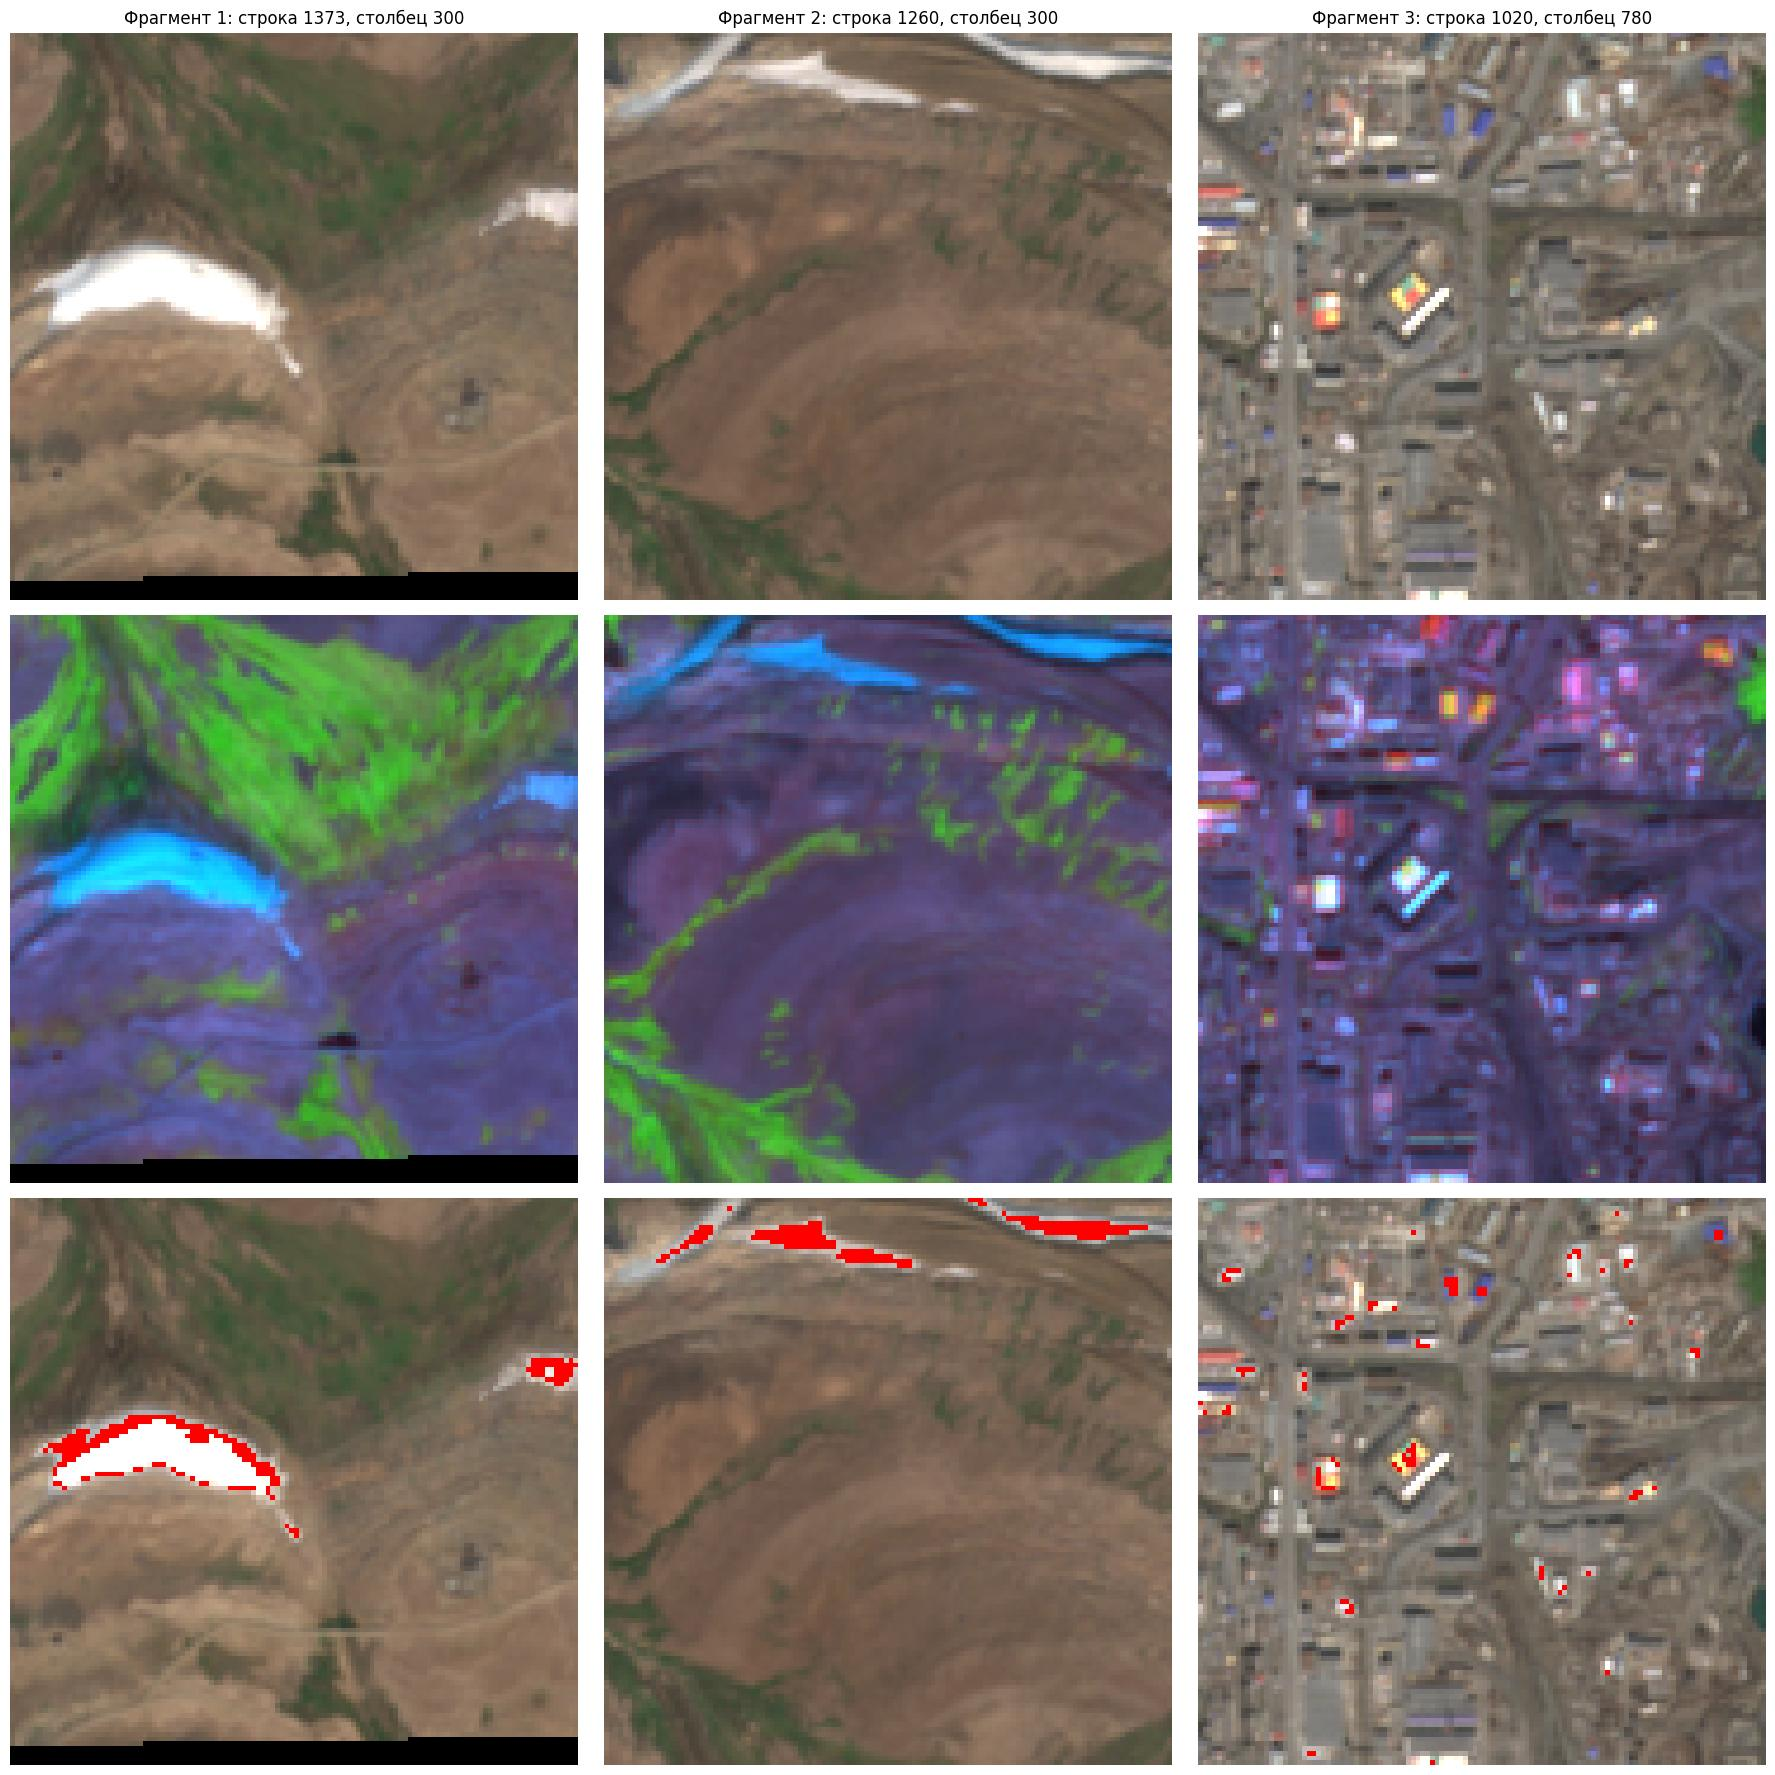

In [ ]:
centroids_arr = centroids
means_arr = np.array(means)[:, None, None]
stds_arr = np.array(stds)[:, None, None]

z_all = (bands[:len(LOCAL_BANDS)] - means_arr) / stds_arr
z_all_flat = z_all.reshape(z_all.shape[0], -1).T

sq_dists = (z_all_flat ** 2).sum(axis=1)[:, None] - 2 * z_all_flat @ centroids_arr.T + (centroids_arr ** 2).sum(axis=1)[None]
sq_dists = np.maximum(sq_dists, 0)
dist_map_flat = np.sqrt(sq_dists.min(axis=1))
dist_map = dist_map_flat.reshape(H, W)

outside_needles = valid & (~needle_mask)
far_values = dist_map[outside_needles]
threshold_01 = np.percentile(far_values, 99.9)
rare_mask = (dist_map >= threshold_01) & outside_needles

print(f'Порог 0,1%: {threshold_01:.3f}, пикселей: {rare_mask.sum()}')
zoom_views(rare_mask, n=3, size=60, color=(1, 0, 0))

**Вопрос:** Что оказалось среди самых необычных пикселей? Это отдельные объекты, границы между разными поверхностями или артефакты композита (остатки облаков, теней)? Есть ли среди них объекты, которые вы пропустили бы при просмотре снимка?

**Ответ:** Среди самых необычных пикселей оказались крыши некоторых зданий и шапки снега на холмах. При просмотре я уделил внимание снегу, но пропустил крыши

### **5.8. Проверка гипотез и выводы по разделу 5**

**Задание 5.8.** Вернитесь к таблице 2. Для каждой гипотезы укажите, подтвердилась ли она, каким кластером или каким способом найден объект, его площадь и класс Dynamic World.

**Ответ:**
| № | Гипотеза | Статус | Кластером/способом | Площадь и класс Dynamic World |
|---|---|---|---|---|
| 1 | Дорога, вдоль которой лежит либо снег, либо отвалы породы | Подтвердилась | Дорога выделена кластером 11, а снег выделен кластером К4 | Площадь кластера К4 - 36.8 га, площадь кластера 11 - 1698 га<br>Dynamic World относит эти зоны к классам "Застройка" и "Голая земля" |
| 2 | Часть городской растительности (скверы, парки, клумбы) | Подтвердилась | Выделена с помощью кластера 10 | Площадь кластера 10 - 1276 га<br>Dynamic World относит эту зону к классу "Застройка" |
| 3 | Холмы из горных пород | Подтвердилась | Снег выделен кластером 4, поверхность холмов выделена кластерами 7, 9, 10, 11, склоны холмов выделены кластерами 9, 10 | Dynamic World относит поверхность холмов к классу "Голая земля", но в одном месте склон был отнесён к классу "Вода" |

Опишите, что нашла кластеризация из того, чего нет в легенде Dynamic World и что не выделил ваш классификатор; какие объекты плохо видны в естественных цветах, но выделяются по инфракрасным каналам; как выбор $K$ влияет на результат.

**Вывод:**
Кластеризация выделила 3 типа водной повехности, 3 типа кустарников, 2 типа лесов, 2 типа техногенной поверхности и 2 типа застройки.

В нашей задаче в естественных цветах плохо видны некоторые типы искусственных материалов и растительность, но они имеют характерные особенности в инфракрасных каналах.

Выбор K в K-Means — это компромисс между детализацией и обобщением. Слишком малое K ведёт к смешению разных классов в одном кластере, а слишком большое — к дроблению одного класса на несколько бессмысленных подклассов.

---

## **6. Сжатие изображений кластеризацией цветов (для бакалавров)**

Кластеризация цветов заменяет все цвета изображения палитрой из $K$ цветов — центроидов кластеров (см. лекция «Кластеризация спутниковых снимков в среде Google Earth Engine», **раздел 6**). Выигрыш в размере получается, только если результат сохранён как **палитра + номера цветов пикселей**. В этом разделе вы проверите, для каких изображений и при каком числе цветов такое сжатие действительно выгодно по сравнению с обычными форматами.

### **6.1. Изображения для экспериментов**

**Задание 6.1.** Загрузите в папку `photos` (панель «Файлы» слева, папка создаётся следующей ячейкой) **две свои фотографии** в формате JPEG:
- фотографию с плавными переходами цвета — небо, портрет, пейзаж, животное на однородном фоне;
- фотографию с множеством мелких деталей и ярких цветов — рынок, цветник, городская улица.

Пропишите имена файлов в словаре `PHOTOS`. Кроме фотографий в эксперименты войдут два изображения вашей территории: фрагмент карты кластеров $K = 12$ из раздела 5 (тематическая карта с небольшим числом цветов) и тот же фрагмент снимка в естественных цветах. Все изображения уменьшаются так, чтобы большая сторона была не больше 1024 пикселей, — это ускоряет расчёты и делает изображения сопоставимыми.

In [ ]:
os.makedirs('photos', exist_ok=True)

In [ ]:
import requests

nature_data = requests.get("https://img.magnific.com/premium-psd/sunset-mountainous-landscape_957244-30975.jpg?semt=ais_hybrid&w=740&q=80").content
with open('photos/nature.jpg', 'wb') as f:
    f.write(nature_data)

market_data = requests.get("https://opis-cdn.tinkoffjournal.ru/mercury/moskvoretsky-2.eyjw0m.jpg").content
with open('photos/market.jpg', 'wb') as f:
    f.write(market_data)

In [ ]:
PHOTOS = {
    'Фото с плавными переходами': 'photos/nature.jpg',
    'Фото с мелкими деталями': 'photos/market.jpg',
}

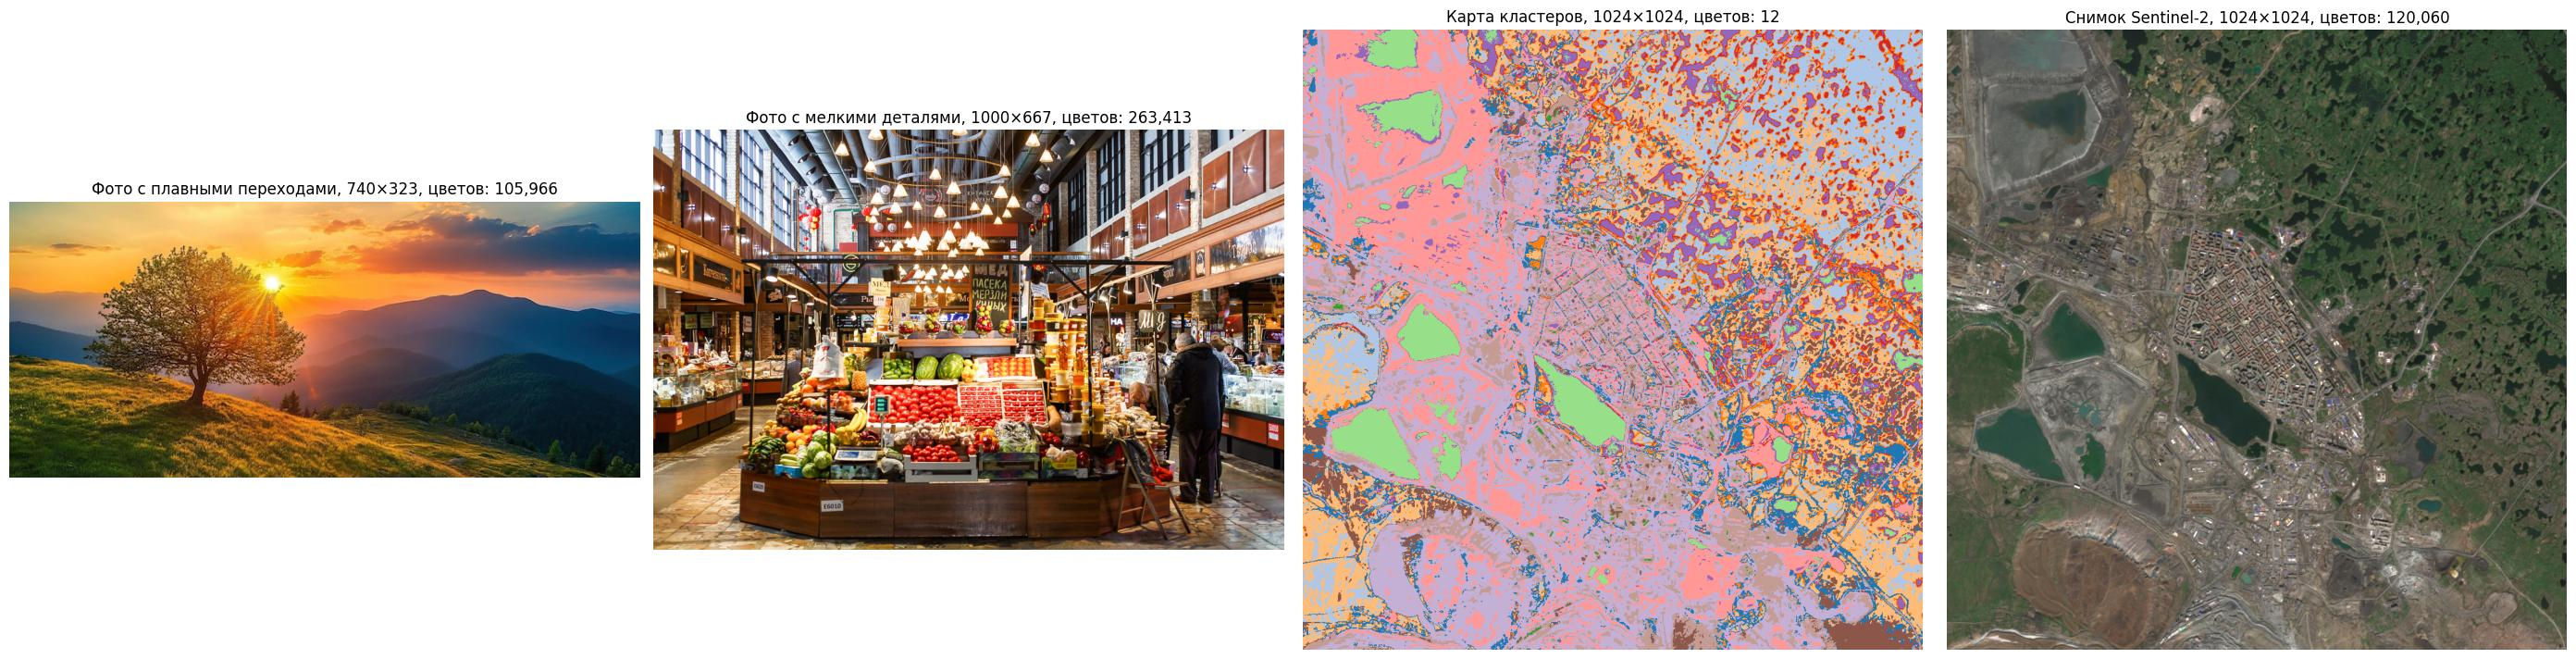

In [ ]:
#@title Готовая функция: подготовка изображений
MAX_SIDE = 1024

def load_photo(path, max_side=MAX_SIDE):
    """RGB-массив фотографии, уменьшенной до max_side пикселей по большей стороне."""
    img = Image.open(path).convert('RGB')
    img.thumbnail((max_side, max_side))
    return np.array(img)

images = {name: load_photo(path) for name, path in PHOTOS.items()}

# Фрагмент территории: центральный квадрат растра не больше MAX_SIDE пикселей
side = min(H, W, MAX_SIDE)
r0, c0 = (H - side) // 2, (W - side) // 2
window = np.s_[r0:r0 + side, c0:c0 + side]
cluster_rgb = np.round(cluster_colors[:, :3] * 255).astype('uint8')   # цвета кластеров в RGB
images['Карта кластеров'] = cluster_rgb[np.clip(labels[window], 0, K - 1)]
images['Снимок Sentinel-2'] = (rgb[window] * 255).astype('uint8')

fig, axes = plt.subplots(1, len(images), figsize=(7 * len(images), 7))
for ax, (name, img) in zip(axes, images.items()):
    ax.imshow(img)
    ax.set_title(f'{name}, {img.shape[1]}×{img.shape[0]}, цветов: {len(np.unique(img.reshape(-1, 3), axis=0)):,}')
    ax.axis('off')
plt.tight_layout()
plt.show()

### **6.2. Как сохранять результат**

Размер файла — главный показатель эффективности сжатия, поэтому сохраняйте изображения **строго одним из способов из таблицы 4** и измеряйте размер **настоящего файла на диске** функцией `os.path.getsize`. Все файлы раздела сохраняйте в папку `compressed/<название изображения>/`.

#### **Таблица 4. Способы сохранения**

| **Способ** | **Код** | **Что записывается в файл** |
|---|---|---|
| PNG без потерь — эталон размера | `Image.fromarray(img).save(path, format='PNG', optimize=True)` | 3 байта цвета на пиксель, сжатие без потерь |
| JPEG, качество 90 — обычное сжатие фотографий | `Image.fromarray(img).save(path, format='JPEG', quality=90)` | Сжатие с потерями, рассчитанное на фотографии |
| **Палитровый PNG — результат кластеризации** | `p_img = Image.frombytes('P', (w, h), indices.astype('uint8').tobytes())`<br>`p_img.putpalette(palette.flatten().tolist())`<br>`p_img.save(path, format='PNG', optimize=True)` | Палитра из $K$ цветов и номер цвета для каждого пикселя: 1 бит на пиксель при 2 цветах, 4 бита при 16, 8 бит при 256 |

Обратите внимание:
- номера цветов `indices` должны иметь тип `uint8` (от 0 до 255), поэтому $K \le 256$;
- параметр `mode` функции `Image.fromarray` в новых версиях Pillow устарел, поэтому палитровое изображение создаётся через `Image.frombytes`;
- изображение `palette[indices]` (восстановленные цвета) нужно только для просмотра и расчёта качества — если сохранить его как RGB-PNG или JPEG, выигрыша от кластеризации не будет (это вы проверите в разделе 6.4).

**Задание 6.2.** Допишите две функции:
- `quantize_kmeans(image, k, sample_size=50000, seed=42)` — обучает `KMeans(n_clusters=k, n_init=1, random_state=seed)` на случайной подвыборке `sample_size` пикселей (все пиксели, если `sample_size=None` или пикселей меньше), относит все пиксели к ближайшим центроидам и возвращает палитру `palette` (`uint8`, форма $(k, 3)$), индексы `indices` (`uint8`, форма $(h, w)$) и время работы в секундах;
- `save_palette_png(palette, indices, path)` — сохраняет палитровый PNG по таблице 4 и возвращает размер файла в КБ.

In [ ]:
def quantize_kmeans(image, k, sample_size=50000, seed=42):
    """Квантизация RGB-изображения до k цветов методом K-средних: палитра, индексы и время, с."""
    start = time.perf_counter()
    h_img, w_img, _ = image.shape
    colors = image.reshape(-1, 3).astype('float32')
    n_pixels = colors.shape[0]
    if sample_size is None or sample_size >= n_pixels:
        sample = colors
    else:
        sample = colors[np.random.RandomState(seed).choice(n_pixels, sample_size, replace=False)]
    kmeans = KMeans(n_clusters=k, n_init=1, random_state=seed).fit(sample)
    palette = np.round(kmeans.cluster_centers_).astype('uint8')
    indices = kmeans.predict(colors).reshape(h_img, w_img).astype('uint8')
    return palette, indices, time.perf_counter() - start

def save_palette_png(palette, indices, path):
    """Палитровый PNG: таблица цветов и номер цвета каждого пикселя. Возвращает размер файла, КБ."""
    h, w = indices.shape
    p_img = Image.frombytes('P', (w, h), indices.astype('uint8').tobytes())
    p_img.putpalette(palette.flatten().tolist())
    p_img.save(path, format='PNG', optimize=True)
    return os.path.getsize(path) / 1024

In [ ]:
#@title Готовые функции: сохранение без кластеризации и метрики качества
def save_rgb(img, path, **save_args):
    """Сохраняет RGB-массив в файл и возвращает размер, КБ."""
    Image.fromarray(img).save(path, **save_args)
    return os.path.getsize(path) / 1024

def quality(original, restored):
    """PSNR (дБ) и SSIM восстановленного изображения относительно исходного."""
    return (peak_signal_noise_ratio(original, restored, data_range=255),
            structural_similarity(original, restored, channel_axis=2, data_range=255))

for name in images:
    os.makedirs(f'compressed/{name}', exist_ok=True)

### **6.3. Размер, качество и время при разном числе цветов**

**Задание 6.3.** Для каждого изображения из `images`:
1. Сохраните эталоны без кластеризации: `compressed/<имя>/original.png` (PNG без потерь) и `compressed/<имя>/original_q90.jpg` (JPEG, качество 90). Для JPEG рассчитайте PSNR и SSIM относительно исходного изображения.
2. Для каждого `k` из `K_COLORS` выполните `quantize_kmeans`, сохраните палитровый PNG `compressed/<имя>/kmeans_<k>.png`, рассчитайте PSNR и SSIM восстановленного изображения `palette[indices]`.

Соберите две таблицы: `baselines` (столбцы `Изображение`, `PNG без потерь, КБ`, `JPEG 90, КБ`, `JPEG 90 PSNR`, `JPEG 90 SSIM`) и `results` (столбцы `Изображение`, `Цветов`, `Время, с`, `Палитровый PNG, КБ`, `PSNR`, `SSIM`). Сохраните палитры и индексы в словарь `quantized[(имя, k)]` — они понадобятся дальше. Если восстановленное изображение точно совпадает с исходным (так бывает, когда цветов в изображении не больше $K$), PSNR равен бесконечности.

In [ ]:
K_COLORS = [2, 4, 8, 16, 32, 64, 128, 256]

In [ ]:
baselines = {}
results_list = []
quantized = {}

for name, img in images.items():
    os.makedirs(f'compressed/{name}', exist_ok=True)

    png_size = save_rgb(img, f'compressed/{name}/original.png', format='PNG', optimize=True)
    baselines[name] = {'PNG без потерь, КБ': png_size}

    jpg_path = f'compressed/{name}/original_q90.jpg'
    jpg_size = save_rgb(img, jpg_path, format='JPEG', quality=90)
    jpg_psnr, jpg_ssim = quality(img, np.array(Image.open(jpg_path)))
    baselines[name].update({'JPEG 90, КБ': jpg_size, 'JPEG 90 PSNR': jpg_psnr, 'JPEG 90 SSIM': jpg_ssim})

    for k in K_COLORS:
        palette, indices, elapsed = quantize_kmeans(img, k)
        png_k_size = save_palette_png(palette, indices, f'compressed/{name}/kmeans_{k}.png')
        restored = palette[indices]
        psnr, ssim = quality(img, restored)
        results_list.append({
            'Изображение': name, 'Цветов': k, 'Время, с': elapsed,
            'Палитровый PNG, КБ': png_k_size, 'PSNR': psnr, 'SSIM': ssim
        })
        quantized[(name, k)] = (palette, indices)

results = pd.DataFrame(results_list)
baselines = pd.DataFrame.from_dict(baselines, orient='index')

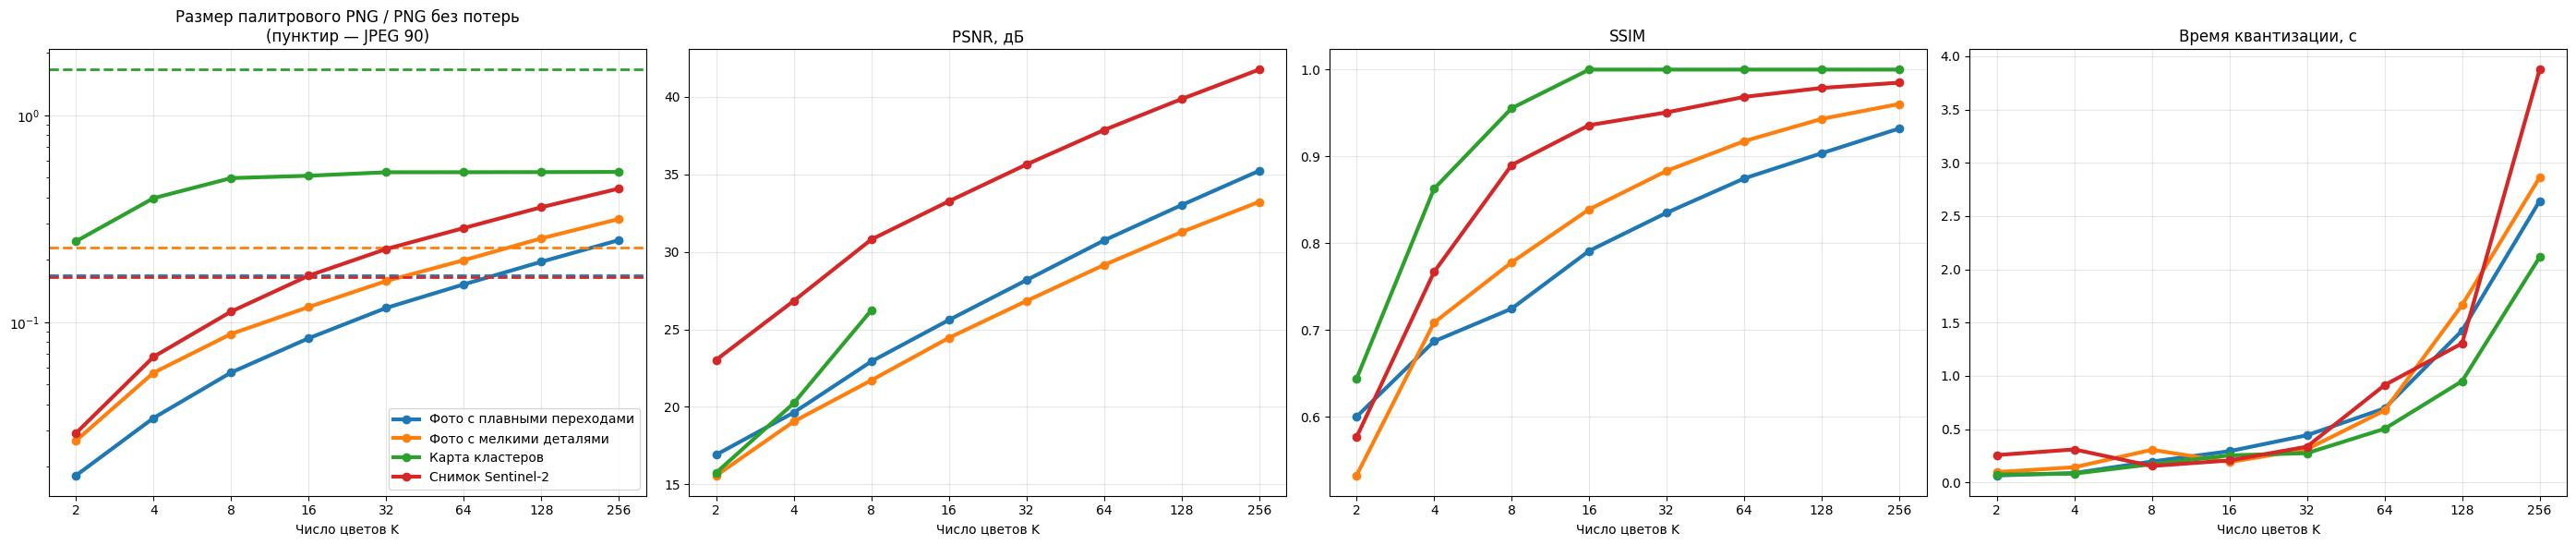

Изображение,Карта кластеров,Снимок Sentinel-2,Фото с мелкими деталями,Фото с плавными переходами
Цветов,,,,
2,0.07,0.26,0.10,0.07
4,0.08,0.31,0.14,0.09
8,0.17,0.15,0.31,0.20
16,0.25,0.21,0.19,0.29
32,0.28,0.34,0.31,0.44
64,0.50,0.91,0.68,0.70
128,0.95,1.31,1.67,1.43
256,2.11,3.88,2.86,2.64


Изображение,Карта кластеров,Снимок Sentinel-2,Фото с мелкими деталями,Фото с плавными переходами
Цветов,,,,
2,85.1,52.6,34.2,6.6
4,137.4,122.9,72.7,12.5
8,171.8,203.2,112.0,20.7
16,176.4,302.9,151.1,30.3
32,183.3,407.7,201.7,42.5
64,183.4,514.5,254.4,55.2
128,183.6,648.7,324.2,70.9
256,184.0,798.5,402.2,90.3


In [ ]:
#@title Готовый код: графики размера, качества и времени
fig, axes = plt.subplots(1, 4, figsize=(28, 6))
for name, part in results.groupby('Изображение', sort=False):
    ratio = part['Палитровый PNG, КБ'] / baselines.loc[name, 'PNG без потерь, КБ']
    line, = axes[0].plot(part['Цветов'], ratio, 'o-', linewidth=3, label=name)
    axes[0].axhline(baselines.loc[name, 'JPEG 90, КБ'] / baselines.loc[name, 'PNG без потерь, КБ'],
                    color=line.get_color(), linestyle='--', linewidth=2)
    axes[1].plot(part['Цветов'], part['PSNR'], 'o-', linewidth=3, color=line.get_color())
    axes[2].plot(part['Цветов'], part['SSIM'], 'o-', linewidth=3, color=line.get_color())
    axes[3].plot(part['Цветов'], part['Время, с'], 'o-', linewidth=3, color=line.get_color())
titles = ['Размер палитрового PNG / PNG без потерь\n(пунктир — JPEG 90)', 'PSNR, дБ', 'SSIM', 'Время квантизации, с']
for ax, title in zip(axes, titles):
    ax.set_xscale('log', base=2)
    ax.set_xticks(K_COLORS, K_COLORS)
    ax.set_xlabel('Число цветов K')
    ax.set_title(title)
    ax.grid(alpha=0.3)
axes[0].set_yscale('log')
axes[0].legend()
plt.tight_layout()
plt.show()
display(results.pivot(index='Цветов', columns='Изображение', values='Время, с').round(2))
results.pivot(index='Цветов', columns='Изображение', values='Палитровый PNG, КБ').round(1)

**Вопрос:** Во сколько раз палитровый PNG при 16 цветах меньше PNG без потерь для каждого изображения? Для какого изображения выигрыш наибольший и почему? Как растёт время квантизации с ростом $K$?

**Ответ:**
Размер карты кластеров уменьшился примерно в 2 раза; размер снимка Sentinel-2 уменьшился примерно в 6 раз; размер фото с мелкими деталями - примерно в 8.5 раз; размер фото с плавными переходами - примерно в 12 раз.

Наибольший выигрыш - для фото с плавным переходом.

С ростом K время квантизации увеличивается по экспоненте.

### **6.4. Что будет, если сохранить результат неправильно**

**Задание 6.4.** Для каждого изображения при $K = 16$ сохраните восстановленное изображение `palette[indices]` как RGB-PNG (`kmeans_16_rgb.png`) и как JPEG качества 90 (`kmeans_16_q90.jpg`). Сравните размеры с палитровым PNG `kmeans_16.png` и с эталонами в таблице `wrong`.

In [ ]:
wrong = {}
for name in images:
    palette, indices = quantized[(name, 16)]
    restored = palette[indices]

    rgb_png_size = save_rgb(restored, f'compressed/{name}/kmeans_16_rgb.png', format='PNG', optimize=True)
    rgb_jpg_size = save_rgb(restored, f'compressed/{name}/kmeans_16_q90.jpg', format='JPEG', quality=90)
    pal_png_size = save_palette_png(*quantized[(name, 16)], f'compressed/{name}/kmeans_16.png')

    wrong[name] = {
        'Палитровый PNG': pal_png_size,
        'RGB-PNG': rgb_png_size,
        'JPEG 90': rgb_jpg_size
    }

wrong_table = pd.DataFrame(wrong).T
display(wrong_table)

,Палитровый PNG,RGB-PNG,JPEG 90
Фото с плавными переходами,30.295898,70.643555,66.419922
Фото с мелкими деталями,151.095703,349.621094,325.435547
Карта кластеров,176.354492,345.826172,574.490234
Снимок Sentinel-2,302.882812,715.489258,299.108398


**Вопрос:** Во сколько раз RGB-PNG и JPEG квантизованного изображения тяжелее палитрового PNG? Почему JPEG квантизованного изображения может оказаться не меньше JPEG исходного?

**Ответ:**

Фото с плавными переходами:
- RGB-PNG тяжелее примерно в 2.3 раза
- JPER тяжелее примерно в 2.2 раза

Фото с мелкими деталями:
- RGB-PNG тяжелее примерно в 2.3 раза
- JPER тяжелее примерно в 2.15 раза

Карта кластеров:
- RGB-PNG тяжелее примерно в 2 раза
- JPER тяжелее примерно в 3.3 раза

Снимок Sentinel-2:
- RGB-PNG тяжелее примерно в 2.4 раза
- JPER легче примерно в 1.01 раза

### **6.5. Подвыборка пикселей и время**

K-средних можно обучать не на всех пикселях, а на случайной подвыборке: центроиды получаются почти такими же, а время сокращается. Проверим, где граница.

**Задание 6.5.** Для первой фотографии и $K = 64$ выполните `quantize_kmeans` с `sample_size` из списка `[1000, 10000, 50000, None]` (`None` — все пиксели). Постройте таблицу `sampling`: размер подвыборки, время, PSNR, SSIM.

In [ ]:
first_photo_name = list(images.keys())[0]
first_photo = images[first_photo_name]
K_test = 64
sampling = []
for sample_size in [1000, 10000, 50000, None]:
    palette, indices, elapsed = quantize_kmeans(first_photo, K_test, sample_size=sample_size)
    restored = palette[indices]
    psnr, ssim = quality(first_photo, restored)
    sampling.append({
        'Подвыборка': sample_size if sample_size else 'все',
        'Время, с': elapsed, 'PSNR': psnr, 'SSIM': ssim
    })
sampling_table = pd.DataFrame(sampling)
display(sampling_table)

,Подвыборка,"Время, с",PSNR,SSIM
0,1000,0.112997,30.130992,0.859520
1,10000,0.292043,30.628844,0.871413
2,50000,1.003288,30.731010,0.874620
3,все,8.623294,30.720284,0.874921


**Вопрос:** Во сколько раз обучение на всех пикселях дольше, чем на 50 000? Насколько при этом меняется PSNR? Какой размер подвыборки вы бы рекомендовали и почему?

**Ответ:** Обучение на всех пикселях примерно в 4.7 раза дольше, чем на 50000. При этом PSNR уменьшается на 0.010726. Выбрал бы подвыборку на 50000 пикселях, так как в этом случае имеем самый лучший PSNR, SSIM близкий к лучшем результату (разница - 0.000301), а времени на обучение требуется меньше, чем в случае со всеми пикселями.

### **6.6. K-средних против встроенной квантизации PIL**

В библиотеке PIL есть собственная быстрая квантизация методом **медианного сечения** (`Image.quantize`): цветовое пространство рекурсивно делится пополам по самой «длинной» оси, пока не получится $K$ ячеек. В отличие от K-средних, метод не итеративный и не минимизирует ошибку восстановления цветов явно.

**Задание 6.6.** Для всех изображений и $K \in \{4, 16, 64\}$ получите палитровое изображение `Image.fromarray(img).quantize(colors=k, method=Image.Quantize.MEDIANCUT, dither=Image.Dither.NONE)`, измерьте время, сохраните его как `mediancut_<k>.png` (`optimize=True`), восстановите цвета (`.convert('RGB')`) и рассчитайте PSNR и SSIM. Сравните с K-средних из таблицы `results` в таблице `versus`.

In [ ]:
versus = []
K_VALUES = [4, 16, 64]

for name, img in images.items():
    os.makedirs(f'compressed/{name}', exist_ok=True)

    for k in K_VALUES:
        start_mc = time.perf_counter()
        p_img = Image.fromarray(img).quantize(colors=k, method=Image.Quantize.MEDIANCUT, dither=Image.Dither.NONE)
        mc_time = time.perf_counter() - start_mc

        raw_palette = p_img.getpalette()
        mc_palette = np.array(raw_palette).reshape(-1, 3)[:k].astype('uint8')

        mc_indices = np.array(p_img).astype('uint8')
        mc_size = save_palette_png(mc_palette, mc_indices, f'compressed/{name}/mediancut_{k}.png')
        mc_restored = np.array(p_img.convert('RGB'))
        mc_psnr, mc_ssim = quality(img, mc_restored)

        km_row = results[(results['Изображение'] == name) & (results['Цветов'] == k)]
        km_psnr = km_row['PSNR'].values[0] if len(km_row) > 0 else None
        km_ssim = km_row['SSIM'].values[0] if len(km_row) > 0 else None
        km_time = km_row['Время, с'].values[0] if len(km_row) > 0 else None
        km_size = km_row['Палитровый PNG, КБ'].values[0] if len(km_row) > 0 else None

        versus.append({'Изображение': name, 'K': k, 'Метод': 'Median Cut',
                       'Время, с': mc_time, 'Размер, КБ': mc_size, 'PSNR': mc_psnr, 'SSIM': mc_ssim})
        versus.append({'Изображение': name, 'K': k, 'Метод': 'K-means',
                       'Время, с': km_time, 'Размер, КБ': km_size, 'PSNR': km_psnr, 'SSIM': km_ssim})

versus_table = pd.DataFrame(versus)
display(versus_table.round(2))

,Изображение,K,Метод,"Время, с","Размер, КБ",PSNR,SSIM
0,Фото с плавными переходами,4,Median Cut,0.44,14.97,19.47,0.68
1,Фото с плавными переходами,4,K-means,0.09,12.48,19.64,0.69
2,Фото с плавными переходами,16,Median Cut,0.25,34.83,23.98,0.79
3,Фото с плавными переходами,16,K-means,0.29,30.30,25.60,0.79
4,Фото с плавными переходами,64,Median Cut,0.25,57.53,28.53,0.85
5,Фото с плавными переходами,64,K-means,0.70,55.16,30.73,0.87
6,Фото с мелкими деталями,4,Median Cut,0.79,73.96,18.57,0.71
7,Фото с мелкими деталями,4,K-means,0.14,72.72,19.06,0.71
8,Фото с мелкими деталями,16,Median Cut,0.69,163.21,22.93,0.84
9,Фото с мелкими деталями,16,K-means,0.19,151.10,24.45,0.84


**Вопрос:** Какой метод даёт более высокое качество при одинаковом числе цветов и на сколько децибел? Для каких изображений разница больше всего? Как различаются размер файлов и время работы методов?

**Ответ:**

При K = 4:
- Для фото с плавными переходами метод K-means лучше на 0.17
- Для фото с мелкими деталями метод K-means лучше на 0.49
- Для карты кластеров метод K-means лучше на 3.07
- Для снимка Sentinel-2 метод K-means лучше на 0.63

При K = 16:
- Для фото с плавными переходами метод K-means лучше на 1.62
- Для фото с мелкими деталями метод K-means лучше на 1.52
- Для снимка Sentinel-2 метод K-means лучше на 2.68

При K = 64:
- Для фото с плавными переходами метод K-means лучше на 2.2
- Для фото с мелкими деталями метод K-means лучше на 1.75
- Для снимка Sentinel-2 метод K-means лучше на 3.74

Для карты кластеров при K = 4 и снимка Sentinel-2 при K = 64 разница больше всего.

Во всех случаях, кроме обработки карты кластеров, алгоритм K-means формирует файл меньшего размера, чем алгоритм Median Cut.

### **6.7. Выбор числа цветов**

Выберем для каждого изображения наименьшее число цветов, при котором искажения малозаметны, и сравним размер файла с обычными форматами при этом качестве.

**Задание 6.7.** Для каждого изображения найдите наименьшее `k` из `K_COLORS`, при котором `SSIM` ≥ 0,95, и постройте таблицу `choice`: выбранное `k`, размер палитрового PNG, PSNR и SSIM при нём, размер PNG без потерь, размер, PSNR и SSIM JPEG 90, и отношение размера палитрового PNG к JPEG 90.

In [ ]:
choice = {}
for name in images:
    part = results[results["Изображение"] == name]
    suitable = part[part["SSIM"] >= 0.95]
    if len(suitable) > 0:
        k_best = suitable["Цветов"].min()
        row = suitable[suitable["Цветов"] == k_best].iloc[0]
        choice[name] = {
            "K": int(k_best),
            "Палитровый PNG, КБ": row["Палитровый PNG, КБ"],
            "PSNR": row["PSNR"],
            "SSIM": row["SSIM"],
            "PNG без потерь, КБ": baselines.loc[name, "PNG без потерь, КБ"],
            "JPEG 90, КБ": baselines.loc[name, "JPEG 90, КБ"],
            "JPEG 90 PSNR": baselines.loc[name, "JPEG 90 PSNR"],
            "JPEG 90 SSIM": baselines.loc[name, "JPEG 90 SSIM"],
        }
    else:
        k_best = part["Цветов"].max()
        row = part[part["Цветов"] == k_best].iloc[0]
        choice[name] = {
            "K": int(k_best),
            "Палитровый PNG, КБ": row["Палитровый PNG, КБ"],
            "PSNR": row["PSNR"],
            "SSIM": row["SSIM"],
            "PNG без потерь, КБ": baselines.loc[name, "PNG без потерь, КБ"],
            "JPEG 90, КБ": baselines.loc[name, "JPEG 90, КБ"],
            "JPEG 90 PSNR": baselines.loc[name, "JPEG 90 PSNR"],
            "JPEG 90 SSIM": baselines.loc[name, "JPEG 90 SSIM"],
        }

choice_table = pd.DataFrame(choice).T
display(choice_table.round(2))

,K,"Палитровый PNG, КБ",PSNR,SSIM,"PNG без потерь, КБ","JPEG 90, КБ",JPEG 90 PSNR,JPEG 90 SSIM
Фото с плавными переходами,256.0,90.26,35.22,0.93,362.27,60.91,40.78,0.98
Фото с мелкими деталями,256.0,402.21,33.22,0.96,1276.28,291.81,32.86,0.97
Карта кластеров,8.0,171.81,26.23,0.96,345.83,574.49,20.01,0.76
Снимок Sentinel-2,32.0,407.66,35.63,0.95,1805.94,297.82,37.28,0.96


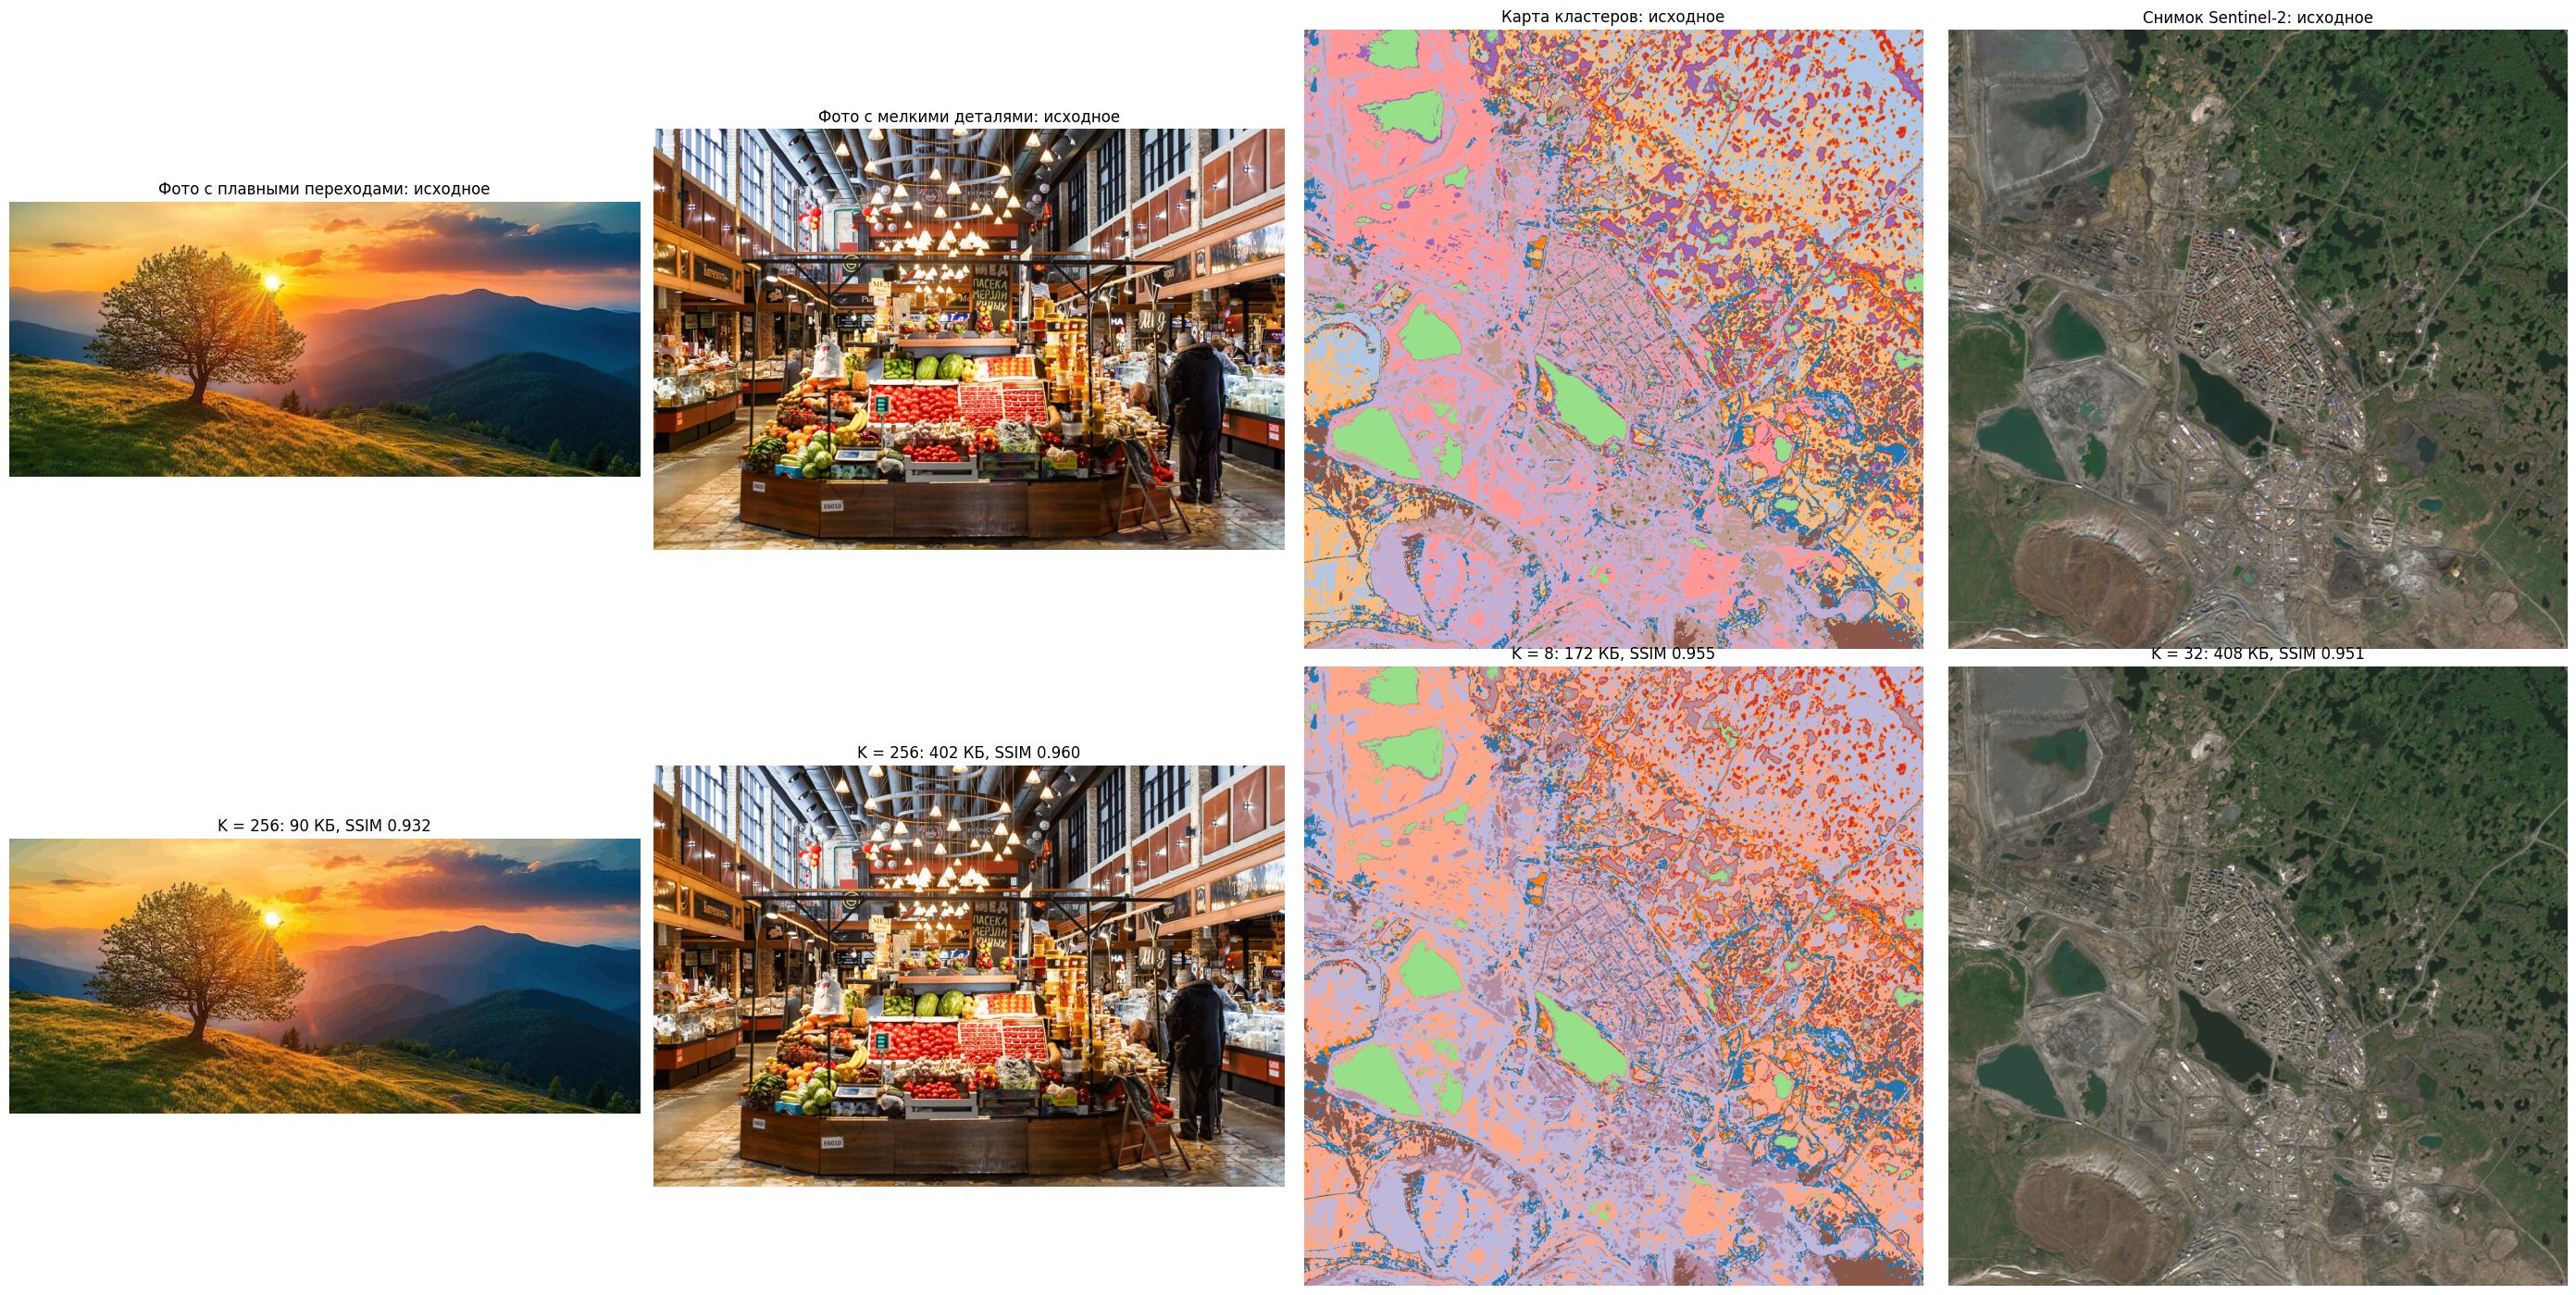

In [ ]:
#@title Готовый код: исходные изображения и выбранное число цветов
fig, axes = plt.subplots(2, len(images), figsize=(7 * len(images), 14))
for j, (name, img) in enumerate(images.items()):
    k = int(choice_table.loc[name, 'K'])
    palette, indices = quantized[(name, k)]
    axes[0, j].imshow(img)
    axes[0, j].set_title(f'{name}: исходное')
    axes[1, j].imshow(palette[indices])
    axes[1, j].set_title(f'K = {k}: {choice_table.loc[name, "Палитровый PNG, КБ"]:.0f} КБ, SSIM {choice_table.loc[name, "SSIM"]:.3f}')
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

**Вопрос:** Для каких изображений палитровый PNG при малозаметных искажениях меньше JPEG 90, а для каких — больше? Чем отличаются эти изображения? Какой способ хранения вы выберете для фотографий, для тематических карт и для снимков в естественных цветах?

**Ответ:** Для карты кластеров палитровый PNG меньше JPEG 90 (171.81 < 574.49), а для всех остальных изображений ситуация обратная. Поэтому для тематических карт лучше использовать PNG, а для снимков в естественных цветах и фотографий - JPEG

### **6.8. Выводы по разделу 6**

Опишите, при каких условиях кластеризация цветов уменьшает размер файла, как правильно сохранять результат, как связаны число цветов, размер и качество, и чем K-средних отличается от встроенной квантизации.

**Вывод:** Кластеризация цветов уменьшает размер файла, если в изображении есть плавный градиент, большие однородные области.

Правильно сохранять результат в формате палитрового PNG.

Чем меньше количество цветов (K), тем меньше размер файла и качество, и наоборот. Как выяснилось в работе, оптимальным количеством цветов является 16.

K-Means: медленнее, но точнее — явно минимизирует ошибку, адаптируется к цветам; зависит от инициализации и масштаба.

Встроенная квантизация: быстрее и проще, но качество палитры обычно ниже.

---

## **7. Итоговые выводы**

В выводах обязательно отразить:
1. **Территория и найденные объекты**: что нашла кластеризация, их площадь, вид в естественных цветах и в инфракрасных каналах;
2. **Классификация по Dynamic World**: точность при случайной и пространственной проверке, лучший классификатор, проблемные классы, совпадение карты с Dynamic World;
3. **Классификация и кластеризация**: что может и чего не может каждый подход на вашей территории;
4. **Сжатие изображений**: для каких изображений и при каком числе цветов кластеризация выгодна, во сколько раз уменьшается размер;
5. **Возможное практическое применение** полученных результатов.

**Выводы:**

1. **Территория и найденные объекты**

Исследование проводилось на территории Норильска, Красноярского края, где находятся медно-никелевые и платиноидные руды. С помощью автоматического алгоритма кластеризации K-means оптимальное число кластеров K=12 удалось детально определить ключевые природные объекты:

Вода (2 365 га). Три кластера. K5 (821.7 га) и K8 (869.9 га) в естественных цветах выглядят одинаково — тёмные, почти чёрные пятна; различить их можно только по инфракрасным каналам: у K5 минимальные NIR/SWIR и сильно положительный NDWI (+0.515) — это глубокая чистая вода, у K8 очень низкая яркость всех каналов и умеренный NDWI (+0.126) — открытая вода озёр и рек. K6 (673.8 га) в RGB тёмный с зеленоватым оттенком, а в NIR/SWIR — низкий NIR (0.069) при умеренном NDVI (0.439): это вода с древесной или затопленной растительностью, берега и заболоченные водоёмы.

Растительность (8 745 га). Пять кластеров, которые в естественных цветах выглядят «просто зелёными», но в инфракрасных каналах расходятся. K1 (2557.2 га) — самый яркий по NIR (0.316) и максимальному NDVI (0.802): густой сомкнутый лес. K3 (3038.3 га) — высокий NIR (0.234) при заметном SWIR (0.198) и NDVI 0.604: лес с подлеском, опушки, смешанная древесно-кустарниковая растительность. K2 (1298.9 га) — высокий NIR (0.190) и NDVI 0.652, но с заметной долей воды: пойменный лес у воды. K10 (1276.0 га) — высокий SWIR (0.221) при NDVI 0.330: влажные кустарники и болотистые луга. K0 (1576.8 га) — средний NIR (0.155) и NDVI 0.361: разреженный древесно-кустарниковый покров, переходный между лесом и открытыми поверхностями.

Техногенные и открытые поверхности (9 273 га). Четыре кластера, и здесь инфракрасные каналы дают наибольший выигрыш. K9 (3723.9 га) в RGB серо-бежевый, а в NIR/SWIR — плоский «серый» спектр без пика в NIR при NDVI 0.066: голая земля, стройплощадки, карьеры. K7 (2074.0 га) тёмно-серый в RGB и с низкой яркостью во всех каналах при NDVI 0.048: асфальт, тени, нарушенные грунты. K11 (1698.0 га) светло-бежевый, яркий в видимом, с повышенным SWIR (0.171/0.154) и NDVI 0.079: яркая застройка, промзоны, сухие песчаные поверхности. И K4 — аномалия площадью всего 36.8 га: в естественных цветах это очень яркое, почти белое пятно, а в NIR/SWIR яркость в 4–5 раз выше среднего при NDVI 0.022; необычность 6.02 на порядок выше остальных кластеров. Это крыши, свежий бетон и металл, снег и лёд, точечные техногенные объекты.

Главное, что нашла кластеризация, — это внутренние градации, невидимые в RGB: густой лес (K1) против разреженного кустарника (K0), чистая вода (K5, K8) против заросшей (K6), тёмный асфальт (K7) против серых грунтов (K9) и яркой застройки (K11), плюс аномально яркий техногенный K4. Именно NIR, SWIR и производные NDVI/NDWI делают эти различия видимыми — в естественных цветах большинство перечисленных пар выглядят одинаково. По площади техногенные и открытые поверхности дают около 45%, растительность — около 43%, вода — около 12%.

2. **Классификация по Dynamic World**

- Лучший классификатор и признаки: cлучайный лес (Random Forest) показал себя наилучшим образом. Наиболее важными являются признаки B12, B11, NDVI. Инфракрасные каналы (B8, B11, B12) вместе с индексами, использующими их (NDWI, NDVI), занимают долю важности, равную 0.632.
- Случайное разбиение: Точность = 0.524, Каппа = 0.465
- Пространственное разбиение: Точность = 0.536, Каппа = 0.478
- Проблемные классы: лучше всего модель распознаёт класс воды, а хуже всего - класс кустарников. Самый проблемный класс путается с классом культур. Эти классы похожи похожи спектрально, потому что оба являются растительностью.
- Совпадение карты с Dynamic World: суммарная «масса» перепутанных пикселей ≈ 3 978 га из 19 645 га, что даёт оценку совпадения ≈ 80 %. Сильнее всего различаются площади: абсолютно — деревья (−2058 га) и трава (+1614 га); относительно — культуры (×5.75), затопленная растительность (×4.76) и снег и лёд (×4.79).

3. **Классификация и кластеризация**

Классификация (Random Forest / GTB / CART)

Что может:
- Дать именованные классы — результат сразу интерпретируем и сопоставим с Dynamic World.
- Оценить качество на независимой выборке.
- Использовать признаки разной природы и показать важность признаков.
- Работать при малом числе обучающих точек на класс, если классы спектрально различимы.

Чего не может:
- Найти неизвестные классы: если на территории есть тип поверхности, не представленный в samples, модель отнесёт его к ближайшему известному — ошибка не проявится в метриках.
- Гарантировать перенос на другую территорию/сезон.
- Разделить спектрально близкие классы без дополнительных признаков.
- Быть лучше DW там, где DW обучен на большем объёме данных.

Кластеризация (K-Means, K=6/12/18)

Что может:
- Выявить структуру без меток: найти типы поверхности, которых нет в CLASSES.
- Указать на неоднородность внутри класса: кластер с высокой «необычностью» — кандидат на смешанные/переходные пиксели.
- Дать основу для палитры/сжатия и для стратификации выборки.
- Работать на любом наборе признаков без обучающих точек.

Чего не может:
- Дать имена классам — кластеры безымянны, их нужно интерпретировать вручную по профилям.
- Оценить точность — нет эталона; «необычность» — мера компактности, а не правильности.
- Гарантировать устойчивость K: при K=18 один класс дробится на подкластеры, при K=6 разные классы сливаются.
- Разделить спектрально близкие, но семантически разные объекты — та же проблема, что у классификации, но без возможности сказать «это ошибка».

4. **Сжатие изображений**

Анализ методов уменьшения цветовой палитры (K-means и Median Cut) выявил следующие закономерности:

Где выгодно квантование: Кластеризация цвета экономически оправдана для «Фото с плавными переходами» и Тематических карт. Для естественных фото с шумом и спутниковых снимков Sentinel-2 выигрыш ниже из-за частой сменяемости пикселей.

Оптимальное число цветов: Оптимальным параметром является K = 16$ цветов. На этом уровне файлы палитрового PNG уменьшаются при сохранении высокого визуального качества, в то время как при K  64 файлы увеличиваются, а время квантования K-means растет по экспоненте.

Метод-лидер: Алгоритм K-means по всем параметрам превосходит встроенный Median Cut и формирует более легкие файлы.

Правила сохранения: Результат надо сохранять в палитровом PNG. Сохранение в RGB-PNG увеличивает размер файла из-за пустых технических битов. Применять сохранение в JPEG для квантованных картинок не рекомендуется: на резких стыках цветов JPEG плодит цифровой шум и артефакты, увеличивая вес файла.

Размер подвыборки: При обучении квантования рекомендуется использовать подвыборку из 50 000 пикселей. Она сокращает время работы процессора примерно в 9 раз  по сравнению со стопроцентной выборкой.

5. **Возможное практическое применение.**

Полученные в проекте алгоритмы и выводы имеют прямую практическую ценность в следующих областях:
- Экологический мониторинг и охрана лесов и водоёмов.
- Контроль недропользования и добычи никеля.
- Оптимизация ГИС и геопорталов.

---

## **Что сдавать**

1. Выполненный блокнот со всеми выводами ячеек и заполненными ответами (таблицы 2 и 3, ответы на вопросы, выводы по разделам 4–6 и итоговые выводы).
2. Папку `compressed` с файлами раздела 6 (в архиве).

## **Дополнительные задания (выполняются по желанию)**

1. **Перенос модели.** Примените классификатор, обученный на своей территории, к композиту другой территории из таблицы 1 и рассчитайте совпадение с Dynamic World. Сравните с точностью пространственной проверки и объясните разницу.
2. **Поиск по эталону.** Возьмите центроиды «иголок» своей территории и найдите на другой территории пиксели, ближе всего к ним расположенные в пространстве стандартизированных признаков. Нашлись ли объекты того же типа?
3. **Собственная реализация K-средних.** Напишите K-средних для цветов на NumPy (инициализация, назначение пикселей, пересчёт центроидов, остановка по сдвигу центроидов) и сравните с `KMeans` по времени, числу итераций и PSNR при $K = 16$.
4. **Другое цветовое пространство.** Выполните квантизацию фотографий в пространстве CIELAB (`skimage.color.rgb2lab`), где евклидово расстояние ближе к различию цветов, воспринимаемому глазом, и сравните SSIM с квантизацией в RGB при одинаковом $K$.